In [2]:
import pickle
import pandas as pd
import numpy as np
import networkx as nx

from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -----------------------------------------
# Load graph
# -----------------------------------------

with open(
    "master_compressed_river_graph.pkl",
    "rb"
) as f:
    G = pickle.load(f)


# -----------------------------------------
# Load hourly data
# -----------------------------------------

hourly = pd.read_csv(
    "usgs_all_stations_hourly.csv"
)


print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

print()
print("Hourly columns:")
print(hourly.columns.tolist())

Graph nodes: 67
Graph edges: 66

Hourly columns:
['station_id', 'time', 'DO concentration', 'Water temperature', 'Specific conductance', 'Turbidity', 'pH', 'Discharge', 'Stage']


In [3]:
TARGET = "pH"

station_values = (
    hourly[
        ["station_id", TARGET]
    ]
    .dropna()
    .groupby("station_id")[TARGET]
    .median()
)

print(
    "Stations with usable",
    TARGET,
    "data:",
    len(station_values)
)

display(
    station_values.head()
)

Stations with usable pH data: 21


station_id
USGS-09070500    8.4
USGS-09071750    8.3
USGS-09085000    8.4
USGS-09085150    7.9
USGS-09085160    8.0
Name: pH, dtype: float64

In [4]:
node_records = []

for node, data in G.nodes(data=True):

    for cluster in data.get(
        "usgs_clusters",
        []
    ):

        member_stations = cluster.get(
            "member_stations",
            []
        )

        values = [
            station_values.loc[station]
            for station in member_stations
            if station in station_values.index
        ]

        if len(values) == 0:
            continue

        node_records.append({
            "node": node,
            "cluster_id":
                cluster.get("cluster_id"),

            "role":
                cluster.get("ml_role"),

            "stations":
                member_stations,

            TARGET:
                float(np.median(values))
        })


node_values = pd.DataFrame(
    node_records
)

display(node_values)

print()
print(
    node_values["role"]
    .value_counts()
)

,node,cluster_id,role,stations,pH
0,97532807,2,train,[USGS-09144250],8.40
1,96496279,3,train,[USGS-09180500],8.30
2,90706215,5,train,[USGS-09163500],8.40
3,67739434,6,train,[USGS-09261000],8.40
4,88786999,8,train,[USGS-09095500],8.40
5,134075067,11,test_partial,[USGS-09365000],8.20
6,93300040,14,train,[USGS-09315000],8.40
7,83027786,15,test_full,[USGS-09071750],8.30
8,81497938,17,test_full,[USGS-09070500],8.40
9,186559442,18,test_partial,[USGS-09510000],8.30



role
train           10
test_partial     5
test_full        4
Name: count, dtype: int64


In [5]:
def build_laplacian(
    G,
    tau_km=100
):

    G_L = nx.Graph()

    G_L.add_nodes_from(
        G.nodes()
    )

    for u, v, data in G.edges(
        data=True
    ):

        distance_km = (
            float(
                data.get(
                    "length_m",
                    0
                )
            )
            / 1000
        )

        weight = np.exp(
            -distance_km / tau_km
        )

        if G_L.has_edge(u, v):

            G_L[u][v][
                "weight"
            ] += weight

        else:

            G_L.add_edge(
                u,
                v,
                weight=weight
            )

    node_order = list(
        G_L.nodes()
    )

    L = nx.laplacian_matrix(
        G_L,
        nodelist=node_order,
        weight="weight"
    ).astype(float)

    return (
        G_L,
        node_order,
        L
    )

In [6]:
G_L, node_order, L = (
    build_laplacian(
        G,
        tau_km=100
    )
)

print("Laplacian shape:", L.shape)
print("Nodes:", len(node_order))

Laplacian shape: (67, 67)
Nodes: 67


In [7]:
def fit_graph_laplacian(
    G,
    node_values,
    target,
    lambda_lap=1.0,
    tau_km=100
):

    G_L, node_order, L = (
        build_laplacian(
            G,
            tau_km=tau_km
        )
    )

    node_index = {
        node: i
        for i, node
        in enumerate(node_order)
    }

    n = len(node_order)

    y = np.zeros(n)

    observed = np.zeros(n)


    # -------------------------------------
    # TRAINING LABELS ONLY
    # -------------------------------------

    training_rows = node_values[
        node_values["role"]
        == "train"
    ]

    for _, row in training_rows.iterrows():

        node = row["node"]

        if node not in node_index:
            continue

        i = node_index[node]

        y[i] = row[target]

        observed[i] = 1


    # -------------------------------------
    # Observation mask
    # -------------------------------------

    M = diags(
        observed
    )


    # -------------------------------------
    # Solve:
    #
    # (M + lambda L) f = M y
    #
    # Small ridge term prevents numerical
    # singularity.
    # -------------------------------------

    epsilon = 1e-8

    A = (
        M
        +
        lambda_lap * L
        +
        epsilon * eye(n)
    )

    b = M @ y

    prediction = spsolve(
        A,
        b
    )


    predictions = {
        node:
            prediction[
                node_index[node]
            ]

        for node in node_order
    }

    return predictions

In [8]:
predictions = fit_graph_laplacian(
    G,
    node_values,
    target="pH",
    lambda_lap=1,
    tau_km=100
)

In [9]:
node = list(G.nodes())[0]

print(
    "Predicted pH:",
    predictions[node]
)

Predicted pH: 8.029403034876466


In [10]:
test = node_values[
    node_values["role"]
    == "test_full"
].copy()

test["predicted_pH"] = (
    test["node"]
    .map(predictions)
)

display(
    test[
        [
            "node",
            "stations",
            "pH",
            "predicted_pH"
        ]
    ]
)

,node,stations,pH,predicted_pH
7,83027786,[USGS-09071750],8.30,8.186677
8,81497938,[USGS-09070500],8.40,8.186677
13,83222751,"[USGS-09085000, USGS-393259107194801]",8.10,8.186678
18,82982643,"[USGS-09085150, USGS-09085160]",7.95,8.186678


In [11]:
y_true = test["pH"]
y_pred = test["predicted_pH"]

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

r2 = r2_score(
    y_true,
    y_pred
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.16250037513497895
RMSE: 0.17455538458037453
R²: -2.7316053411441388e-05


In [12]:
print("Number of test nodes:", len(test))

print("\nActual pH:")
print(test["pH"].describe())

print("\nPredicted pH:")
print(test["predicted_pH"].describe())

print("\nPrediction table:")
display(
    test[
        [
            "node",
            "stations",
            "pH",
            "predicted_pH"
        ]
    ].assign(
        residual=lambda x:
            x["pH"] - x["predicted_pH"]
    )
)

Number of test nodes: 4

Actual pH:
count    4.000000
mean     8.187500
std      0.201556
min      7.950000
25%      8.062500
50%      8.200000
75%      8.325000
max      8.400000
Name: pH, dtype: float64

Predicted pH:
count    4.000000e+00
mean     8.186678e+00
std      5.424181e-07
min      8.186677e+00
25%      8.186677e+00
50%      8.186678e+00
75%      8.186678e+00
max      8.186678e+00
Name: predicted_pH, dtype: float64

Prediction table:


,node,stations,pH,predicted_pH,residual
7,83027786,[USGS-09071750],8.30,8.186677,0.113323
8,81497938,[USGS-09070500],8.40,8.186677,0.213323
13,83222751,"[USGS-09085000, USGS-393259107194801]",8.10,8.186678,-0.086678
18,82982643,"[USGS-09085150, USGS-09085160]",7.95,8.186678,-0.236678


In [13]:
train_mean = node_values.loc[
    node_values["role"] == "train",
    "pH"
].mean()

mean_predictions = np.full(
    len(test),
    train_mean
)

mean_mae = mean_absolute_error(
    test["pH"],
    mean_predictions
)

mean_rmse = np.sqrt(
    mean_squared_error(
        test["pH"],
        mean_predictions
    )
)

mean_r2 = r2_score(
    test["pH"],
    mean_predictions
)

print("Training mean pH:", train_mean)

print("\nMean baseline:")
print("MAE:", mean_mae)
print("RMSE:", mean_rmse)
print("R²:", mean_r2)

print("\nGraph Laplacian:")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

Training mean pH: 8.305

Mean baseline:
MAE: 0.1649999999999998
RMSE: 0.21041625412500803
R²: -0.4531282051282002

Graph Laplacian:
MAE: 0.16250037513497895
RMSE: 0.17455538458037453
R²: -2.7316053411441388e-05


In [14]:
training_rows = node_values[
    node_values["role"] == "train"
]

In [15]:
training_rows = node_values[
    node_values["role"] != "test_full"
]

In [16]:
predictions = fit_graph_laplacian(
    G,
    node_values,
    target="pH",
    lambda_lap=1,
    tau_km=100
)

test = node_values[
    node_values["role"] == "test_full"
].copy()

test["predicted_pH"] = (
    test["node"].map(predictions)
)

y_true = test["pH"]
y_pred = test["predicted_pH"]

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

r2 = r2_score(
    y_true,
    y_pred
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

display(
    test[
        [
            "stations",
            "pH",
            "predicted_pH"
        ]
    ]
)

MAE: 0.16250037513497895
RMSE: 0.17455538458037453
R²: -2.7316053411441388e-05


,stations,pH,predicted_pH
7,[USGS-09071750],8.30,8.186677
8,[USGS-09070500],8.40,8.186677
13,"[USGS-09085000, USGS-393259107194801]",8.10,8.186678
18,"[USGS-09085150, USGS-09085160]",7.95,8.186678


In [17]:
lambda_lap = 1
tau_km = 100

In [18]:
print(
    "Actual test range:",
    test["pH"].min(),
    "to",
    test["pH"].max()
)

print(
    "Predicted test range:",
    test["predicted_pH"].min(),
    "to",
    test["predicted_pH"].max()
)

print(
    "Actual test std:",
    test["pH"].std()
)

print(
    "Predicted test std:",
    test["predicted_pH"].std()
)

Actual test range: 7.95 to 8.4
Predicted test range: 8.18667723102149 to 8.186678472682102
Actual test std: 0.20155644370746398
Predicted test std: 5.424180708776194e-07


In [19]:
lambda_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]

tau_values = [
    10,
    25,
    50,
    100,
    200,
    400
]

In [20]:
from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve

def fit_graph_laplacian(
    G,
    labels,
    lambda_lap=0.001,
    tau_km=50
):

    # -----------------------------------------
    # Build distance-weighted undirected graph
    # -----------------------------------------

    G_L = nx.Graph()
    G_L.add_nodes_from(G.nodes())

    for u, v, data in G.edges(data=True):

        distance_km = (
            float(data.get("length_m", 0))
            / 1000
        )

        weight = np.exp(
            -distance_km / tau_km
        )

        G_L.add_edge(
            u,
            v,
            weight=weight
        )


    # -----------------------------------------
    # Laplacian
    # -----------------------------------------

    node_order = list(G_L.nodes())

    node_index = {
        node: i
        for i, node in enumerate(node_order)
    }

    L = nx.laplacian_matrix(
        G_L,
        nodelist=node_order,
        weight="weight"
    ).astype(float)


    # -----------------------------------------
    # Observation vector + mask
    # -----------------------------------------

    n = len(node_order)

    y = np.zeros(n)
    mask = np.zeros(n)

    for node, value in labels.items():

        if node not in node_index:
            continue

        i = node_index[node]

        y[i] = value
        mask[i] = 1


    M = diags(mask)


    # -----------------------------------------
    # Solve
    # -----------------------------------------

    A = (
        M
        + lambda_lap * L
        + 1e-10 * eye(n)
    )

    b = M @ y

    f = spsolve(
        A,
        b
    )


    return {
        node: f[node_index[node]]
        for node in node_order
    }

In [21]:
# One row per graph node
node_ph = (
    node_values
    .groupby("node", as_index=False)
    .agg({
        "pH": "median",
        "role": "first",
        "stations": "first"
    })
)

# Final untouched test set
final_test = node_ph[
    node_ph["role"] == "test_full"
].copy()

# Everything else with pH can be used
# for model development / CV
development = node_ph[
    node_ph["role"] != "test_full"
].copy()

print(
    "Development nodes:",
    len(development)
)

print(
    "Final test nodes:",
    len(final_test)
)

Development nodes: 15
Final test nodes: 4


In [22]:
from sklearn.metrics import mean_squared_error

lambda_values = [
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1,
    1
]

tau_values = [
    10,
    25,
    50,
    100,
    200
]

results = []

for tau in tau_values:

    for lam in lambda_values:

        actual = []
        predicted = []

        for held_node in development["node"]:

            train_rows = development[
                development["node"]
                != held_node
            ]

            labels = dict(
                zip(
                    train_rows["node"],
                    train_rows["pH"]
                )
            )

            preds = fit_graph_laplacian(
                G,
                labels,
                lambda_lap=lam,
                tau_km=tau
            )

            actual_value = (
                development.loc[
                    development["node"]
                    == held_node,
                    "pH"
                ].iloc[0]
            )

            actual.append(
                actual_value
            )

            predicted.append(
                preds[held_node]
            )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        )

        pred_std = np.std(
            predicted
        )

        results.append({
            "lambda": lam,
            "tau_km": tau,
            "cv_rmse": rmse,
            "prediction_std": pred_std
        })


cv_results = (
    pd.DataFrame(results)
    .sort_values("cv_rmse")
)

display(
    cv_results.head(20)
)

,lambda,tau_km,cv_rmse,prediction_std
44,1.000000,200,0.133964,0.087322
35,1.000000,100,0.134828,0.088892
43,0.100000,200,0.138027,0.101410
34,0.100000,100,0.138311,0.100355
42,0.010000,200,0.138790,0.103890
39,0.000010,200,0.138874,0.104273
41,0.001000,200,0.138876,0.104164
40,0.000100,200,0.138881,0.104198
33,0.010000,100,0.138937,0.102266
32,0.001000,100,0.139008,0.102475


In [23]:
lambda_values = [
    0.1,
    0.25,
    0.5,
    1,
    2,
    5,
    10,
    25
]

tau_values = [
    75,
    100,
    150,
    200,
    300,
    400,
    600
]

results = []

for tau in tau_values:

    for lam in lambda_values:

        actual = []
        predicted = []

        for held_node in development["node"]:

            train_rows = development[
                development["node"] != held_node
            ]

            labels = dict(
                zip(
                    train_rows["node"],
                    train_rows["pH"]
                )
            )

            preds = fit_graph_laplacian(
                G,
                labels,
                lambda_lap=lam,
                tau_km=tau
            )

            actual_value = development.loc[
                development["node"] == held_node,
                "pH"
            ].iloc[0]

            actual.append(actual_value)
            predicted.append(
                preds[held_node]
            )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        )

        mae = mean_absolute_error(
            actual,
            predicted
        )

        results.append({
            "lambda": lam,
            "tau_km": tau,
            "cv_rmse": rmse,
            "cv_mae": mae,
            "actual_std": np.std(actual),
            "prediction_std": np.std(predicted)
        })


refined_results = (
    pd.DataFrame(results)
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)

display(
    refined_results.head(20)
)

,lambda,tau_km,cv_rmse,cv_mae,actual_std,prediction_std
0,25.0,75,0.128744,0.098829,0.131233,0.055203
1,25.0,100,0.128889,0.100979,0.131233,0.048785
2,10.0,150,0.129103,0.099978,0.131233,0.057938
3,10.0,100,0.129183,0.098515,0.131233,0.062615
4,10.0,200,0.129269,0.100796,0.131233,0.055551
5,10.0,300,0.129524,0.102025,0.131233,0.053176
6,25.0,150,0.129651,0.103860,0.131233,0.042329
7,10.0,400,0.129672,0.102670,0.131233,0.052000
8,10.0,600,0.129825,0.103277,0.131233,0.050833
9,5.0,200,0.129856,0.099505,0.131233,0.066411


In [24]:
actual = []
baseline_pred = []

for held_node in development["node"]:

    train_rows = development[
        development["node"] != held_node
    ]

    held_value = development.loc[
        development["node"] == held_node,
        "pH"
    ].iloc[0]

    train_mean = train_rows["pH"].mean()

    actual.append(held_value)
    baseline_pred.append(train_mean)


baseline_rmse = np.sqrt(
    mean_squared_error(
        actual,
        baseline_pred
    )
)

baseline_mae = mean_absolute_error(
    actual,
    baseline_pred
)

baseline_r2 = r2_score(
    actual,
    baseline_pred
)

print("LOOCV mean baseline")
print("RMSE:", baseline_rmse)
print("MAE:", baseline_mae)
print("R²:", baseline_r2)

print()

print("Best graph model so far")
print(
    refined_results.iloc[0]
)

LOOCV mean baseline
RMSE: 0.14060728346449636
MAE: 0.11666666666666678
R²: -0.14795918367346172

Best graph model so far
lambda            25.000000
tau_km            75.000000
cv_rmse            0.128744
cv_mae             0.098829
actual_std         0.131233
prediction_std     0.055203
Name: 0, dtype: float64


In [25]:
lambda_values = [
    5,
    10,
    20,
    25,
    40,
    60,
    100,
    200
]

tau_values = [
    20,
    30,
    40,
    50,
    60,
    75,
    90,
    110,
    150
]

results = []

for tau in tau_values:

    for lam in lambda_values:

        actual = []
        predicted = []

        for held_node in development["node"]:

            train_rows = development[
                development["node"] != held_node
            ]

            labels = dict(
                zip(
                    train_rows["node"],
                    train_rows["pH"]
                )
            )

            preds = fit_graph_laplacian(
                G,
                labels,
                lambda_lap=lam,
                tau_km=tau
            )

            actual_value = development.loc[
                development["node"] == held_node,
                "pH"
            ].iloc[0]

            actual.append(
                actual_value
            )

            predicted.append(
                preds[held_node]
            )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        )

        mae = mean_absolute_error(
            actual,
            predicted
        )

        r2 = r2_score(
            actual,
            predicted
        )

        results.append({
            "lambda": lam,
            "tau_km": tau,
            "cv_rmse": rmse,
            "cv_mae": mae,
            "cv_r2": r2,
            "actual_std": np.std(actual),
            "prediction_std": np.std(predicted)
        })


final_cv_results = (
    pd.DataFrame(results)
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)

display(
    final_cv_results.head(25)
)

,lambda,tau_km,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,25,75,0.128744,0.098829,0.037580,0.131233,0.055203
1,20,90,0.128746,0.099240,0.037547,0.131233,0.054465
2,25,90,0.128762,0.100062,0.037316,0.131233,0.050965
3,60,60,0.128779,0.099874,0.037059,0.131233,0.048762
4,40,75,0.128799,0.100532,0.036761,0.131233,0.047876
5,40,60,0.128828,0.098599,0.036328,0.131233,0.054866
6,20,110,0.128882,0.100634,0.035522,0.131233,0.050778
7,20,75,0.128895,0.098531,0.035320,0.131233,0.058334
8,100,50,0.128898,0.099764,0.035275,0.131233,0.048484
9,25,110,0.129047,0.101764,0.033045,0.131233,0.046997


In [26]:
best = final_cv_results.iloc[0]

print("Best parameters")
print("---------------------------")
print("lambda:", best["lambda"])
print("tau:", best["tau_km"], "km")
print("RMSE:", best["cv_rmse"])
print("MAE:", best["cv_mae"])
print("R²:", best["cv_r2"])
print()
print("Actual SD:", best["actual_std"])
print("Prediction SD:", best["prediction_std"])

print()
print(
    "Prediction SD / actual SD:",
    best["prediction_std"]
    / best["actual_std"]
)

Best parameters
---------------------------
lambda: 25.0
tau: 75.0 km
RMSE: 0.1287439973504599
MAE: 0.0988287427283223
R²: 0.037579666554989566

Actual SD: 0.1312334645668637
Prediction SD: 0.05520288023661851

Prediction SD / actual SD: 0.42064636804961086


In [27]:
GRAPH_BASELINE = {
    "target": "pH",
    "lambda_lap": 25.0,
    "tau_km": 75.0,
    "cv_rmse": 0.12874399735046288,
    "cv_mae": 0.09882874272832348,
    "cv_r2": 0.037579666554945046,
    "prediction_std_ratio": 0.42064636804960964
}

GRAPH_BASELINE

{'target': 'pH',
 'lambda_lap': 25.0,
 'tau_km': 75.0,
 'cv_rmse': 0.12874399735046288,
 'cv_mae': 0.09882874272832348,
 'cv_r2': 0.037579666554945046,
 'prediction_std_ratio': 0.42064636804960964}

In [28]:
print(hourly.columns.tolist())

print("\nNon-null counts:")
print(
    hourly.notna()
    .sum()
    .sort_values(ascending=False)
)

print("\nFirst 5 rows:")
display(hourly.head())

['station_id', 'time', 'DO concentration', 'Water temperature', 'Specific conductance', 'Turbidity', 'pH', 'Discharge', 'Stage']

Non-null counts:
station_id              234095
time                    234095
Water temperature       157136
Specific conductance    156329
pH                      127454
Discharge               127119
DO concentration        120688
Turbidity                95106
Stage                     8761
dtype: int64

First 5 rows:


,station_id,time,DO concentration,Water temperature,Specific conductance,Turbidity,pH,Discharge,Stage
0,USGS-09070500,2025-10-02 04:00:00+00:00,8.0,14.20,382.0,4.20,8.60,1350.0,NaN
1,USGS-09070500,2025-10-02 05:00:00+00:00,7.9,14.00,381.0,4.40,8.50,1350.0,NaN
2,USGS-09070500,2025-10-02 06:00:00+00:00,7.9,13.75,381.0,4.40,8.50,1350.0,NaN
3,USGS-09070500,2025-10-02 07:00:00+00:00,7.9,13.45,380.5,4.40,8.45,1345.0,NaN
4,USGS-09070500,2025-10-02 08:00:00+00:00,7.9,13.15,380.5,4.45,8.40,1340.0,NaN


In [29]:
import numpy as np
import pandas as pd
import networkx as nx

from scipy.sparse import (
    csr_matrix,
    diags,
    eye,
    bmat
)

from scipy.sparse.linalg import spsolve

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


TARGET = "pH"

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


# Make sure everything is numeric
for col in [TARGET] + FEATURES:
    hourly[col] = pd.to_numeric(
        hourly[col],
        errors="coerce"
    )

hourly["station_id"] = (
    hourly["station_id"]
    .astype(str)
)

print("Target:", TARGET)
print("Features:", FEATURES)

Target: pH
Features: ['Water temperature', 'Specific conductance', 'DO concentration', 'Turbidity']


In [30]:
# ==========================================
# Station-level medians
# ==========================================

station_summary = (
    hourly
    .groupby("station_id")[
        [TARGET] + FEATURES
    ]
    .median()
)


# ==========================================
# Move station data onto graph nodes
# ==========================================

rows = []

for node, data in G.nodes(data=True):

    for cluster in data.get(
        "usgs_clusters",
        []
    ):

        members = [
            str(x)
            for x in cluster.get(
                "member_stations",
                []
            )
        ]

        present = [
            station
            for station in members
            if station
            in station_summary.index
        ]

        if len(present) == 0:
            continue

        station_data = (
            station_summary.loc[present]
        )

        target_value = (
            station_data[TARGET]
            .median()
        )

        # Can't use this node for pH modeling
        # if it has no pH
        if pd.isna(target_value):
            continue

        row = {
            "node": node,
            "role": cluster.get(
                "ml_role"
            ),
            "stations": members,
            TARGET: target_value
        }

        for feature in FEATURES:

            row[feature] = (
                station_data[feature]
                .median()
            )

        rows.append(row)


node_table = pd.DataFrame(rows)


# ==========================================
# Check for duplicate effective nodes
# ==========================================

print(
    "Rows:",
    len(node_table)
)

print(
    "Unique graph nodes:",
    node_table["node"].nunique()
)

print()

print(
    node_table["role"]
    .value_counts()
)

print()

print("Missing predictors:")
print(
    node_table[FEATURES]
    .isna()
    .sum()
)

display(
    node_table.head()
)

Rows: 19
Unique graph nodes: 19

role
train           10
test_partial     5
test_full        4
Name: count, dtype: int64

Missing predictors:
Water temperature       0
Specific conductance    0
DO concentration        3
Turbidity               2
dtype: int64


,node,role,stations,pH,Water temperature,Specific conductance,DO concentration,Turbidity
0,97532807,train,[USGS-09144250],8.4,8.30,627.5,10.3,11.450
1,96496279,train,[USGS-09180500],8.3,14.05,1190.0,8.8,28.475
2,90706215,train,[USGS-09163500],8.4,9.20,1270.0,10.1,33.450
3,67739434,train,[USGS-09261000],8.4,12.10,634.0,9.0,14.500
4,88786999,train,[USGS-09095500],8.4,11.45,1140.0,10.2,6.250


In [31]:
USE_PARTIAL_AS_TRAIN = True


# Final untouched station test set
final_test = node_table[
    node_table["role"]
    == "test_full"
].copy()


if USE_PARTIAL_AS_TRAIN:

    # Everything with pH except final test
    development = node_table[
        node_table["role"]
        != "test_full"
    ].copy()

else:

    # Strict original split
    development = node_table[
        node_table["role"]
        == "train"
    ].copy()


print(
    "Development nodes:",
    len(development)
)

print(
    "Final test nodes:",
    len(final_test)
)

print()

print(
    development["role"]
    .value_counts()
)

Development nodes: 15
Final test nodes: 4

role
train           10
test_partial     5
Name: count, dtype: int64


In [32]:
def build_laplacian(
    G,
    tau_km
):

    G_L = nx.Graph()

    G_L.add_nodes_from(
        G.nodes()
    )


    for u, v, data in G.edges(
        data=True
    ):

        distance_km = (
            float(
                data.get(
                    "length_m",
                    0
                )
            )
            / 1000
        )

        weight = np.exp(
            -distance_km
            / tau_km
        )


        if G_L.has_edge(u, v):

            G_L[u][v][
                "weight"
            ] += weight

        else:

            G_L.add_edge(
                u,
                v,
                weight=weight
            )


    node_order = list(
        G_L.nodes()
    )

    L = nx.laplacian_matrix(
        G_L,
        nodelist=node_order,
        weight="weight"
    ).astype(float)


    return (
        G_L,
        node_order,
        L
    )

In [33]:
def fit_graph_laplacian_regression(
    node_table,
    train_nodes,
    node_order,
    L,
    target,
    features,
    lambda_lap=25,
    lambda_beta=1
):

    table = (
        node_table
        .set_index("node")
    )

    node_index = {
        node: i
        for i, node
        in enumerate(node_order)
    }

    n = len(node_order)
    p = len(features)


    # ======================================
    # DESIGN MATRIX
    # ======================================

    # +1 for intercept
    X = np.ones(
        (
            n,
            p + 1
        )
    )

    preprocessing = {}


    for j, feature in enumerate(
        features,
        start=1
    ):

        train_values = []

        for node in train_nodes:

            if node not in table.index:
                continue

            value = table.loc[
                node,
                feature
            ]

            train_values.append(
                value
            )


        train_values = pd.Series(
            train_values,
            dtype=float
        )


        # ----------------------------------
        # Training-only median imputation
        # ----------------------------------

        median = train_values.median()

        if pd.isna(median):
            median = 0.0


        imputed_train = (
            train_values
            .fillna(median)
        )


        # ----------------------------------
        # Training-only scaling
        # ----------------------------------

        mean = imputed_train.mean()

        std = imputed_train.std(
            ddof=0
        )

        if (
            pd.isna(std)
            or std < 1e-12
        ):
            std = 1.0


        preprocessing[feature] = {
            "median": median,
            "mean": mean,
            "std": std
        }


        # ----------------------------------
        # Fill all graph nodes
        # ----------------------------------

        for node in node_order:

            i = node_index[node]

            if node in table.index:

                value = table.loc[
                    node,
                    feature
                ]

            else:

                value = np.nan


            if pd.isna(value):
                value = median


            X[i, j] = (
                (value - mean)
                / std
            )


    # ======================================
    # TARGET + OBSERVATION MASK
    # ======================================

    y = np.zeros(n)

    mask = np.zeros(n)


    for node in train_nodes:

        if node not in table.index:
            continue

        value = table.loc[
            node,
            target
        ]

        if pd.isna(value):
            continue

        i = node_index[node]

        y[i] = value

        mask[i] = 1.0


    M = diags(mask)

    X_sparse = csr_matrix(X)


    # ======================================
    # RIDGE PENALTY FOR BETA
    #
    # Intercept gets penalty 0.
    # ======================================

    beta_penalty = np.ones(
        p + 1
    )

    beta_penalty[0] = 0

    R = diags(
        beta_penalty
    )


    # ======================================
    # BLOCK NORMAL EQUATIONS
    # ======================================

    A11 = (
        X_sparse.T
        @ M
        @ X_sparse
        +
        lambda_beta * R
    )

    A12 = (
        X_sparse.T
        @ M
    )

    A21 = (
        M
        @ X_sparse
    )

    A22 = (
        M
        +
        lambda_lap * L
        +
        1e-8 * eye(n)
    )


    A = bmat(
        [
            [A11, A12],
            [A21, A22]
        ],
        format="csr"
    )


    My = M @ y

    rhs_beta = (
        X_sparse.T
        @ My
    )

    rhs = np.concatenate([
        np.asarray(
            rhs_beta
        ).ravel(),

        np.asarray(
            My
        ).ravel()
    ])


    # ======================================
    # SOLVE
    # ======================================

    solution = spsolve(
        A,
        rhs
    )


    beta = solution[
        :p + 1
    ]

    g = solution[
        p + 1:
    ]


    predictions = (
        X @ beta
        + g
    )


    prediction_dict = {
        node:
            predictions[
                node_index[node]
            ]

        for node
        in node_order
    }


    graph_effect_dict = {
        node:
            g[
                node_index[node]
            ]

        for node
        in node_order
    }


    coefficient_names = (
        ["Intercept"]
        + features
    )

    coefficients = dict(
        zip(
            coefficient_names,
            beta
        )
    )


    return {
        "predictions":
            prediction_dict,

        "graph_effect":
            graph_effect_dict,

        "coefficients":
            coefficients,

        "preprocessing":
            preprocessing
    }

In [34]:
lambda_lap_values = [
    5,
    10,
    25,
    50,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1,
    10,
    100
]


results = []


for tau in tau_values:

    # Only need to build L once
    # for each tau
    G_L, node_order, L = (
        build_laplacian(
            G,
            tau_km=tau
        )
    )


    for lambda_lap in lambda_lap_values:

        for lambda_beta in lambda_beta_values:

            actual = []
            predicted = []


            for held_node in development[
                "node"
            ]:

                train_nodes = (
                    development.loc[
                        development["node"]
                        != held_node,
                        "node"
                    ]
                    .tolist()
                )


                model = (
                    fit_graph_laplacian_regression(
                        node_table=
                            node_table,

                        train_nodes=
                            train_nodes,

                        node_order=
                            node_order,

                        L=L,

                        target=
                            TARGET,

                        features=
                            FEATURES,

                        lambda_lap=
                            lambda_lap,

                        lambda_beta=
                            lambda_beta
                    )
                )


                actual_value = (
                    development.loc[
                        development["node"]
                        == held_node,
                        TARGET
                    ]
                    .iloc[0]
                )


                predicted_value = (
                    model[
                        "predictions"
                    ][held_node]
                )


                actual.append(
                    actual_value
                )

                predicted.append(
                    predicted_value
                )


            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            )


            mae = mean_absolute_error(
                actual,
                predicted
            )


            r2 = r2_score(
                actual,
                predicted
            )


            results.append({
                "lambda_lap":
                    lambda_lap,

                "tau_km":
                    tau,

                "lambda_beta":
                    lambda_beta,

                "cv_rmse":
                    rmse,

                "cv_mae":
                    mae,

                "cv_r2":
                    r2,

                "actual_std":
                    np.std(
                        actual
                    ),

                "prediction_std":
                    np.std(
                        predicted
                    )
            })


glr_results = (
    pd.DataFrame(results)
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    glr_results.head(20)
)

,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,50,50,0.10,0.089258,0.069668,0.537398,0.131233,0.133315
1,100,50,0.10,0.089370,0.070864,0.536236,0.131233,0.129933
2,100,50,0.01,0.089491,0.068959,0.534979,0.131233,0.133117
3,50,50,0.01,0.089491,0.069026,0.534979,0.131233,0.137027
4,25,50,0.10,0.090022,0.072292,0.529443,0.131233,0.135674
5,25,50,0.01,0.090339,0.071153,0.526125,0.131233,0.140236
6,25,75,0.10,0.091259,0.071716,0.516429,0.131233,0.127418
7,10,75,0.10,0.091337,0.071031,0.515597,0.131233,0.130935
8,25,75,0.01,0.091649,0.070453,0.512281,0.131233,0.130732
9,5,75,0.10,0.091863,0.072371,0.510006,0.131233,0.132132


In [35]:
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

lambda_beta_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]

linear_results = []

for lambda_beta in lambda_beta_values:

    actual = []
    predicted = []

    for held_node in development["node"]:

        train = development[
            development["node"] != held_node
        ].copy()

        held = development[
            development["node"] == held_node
        ].copy()

        # -----------------------------------
        # Training-only imputation
        # -----------------------------------

        medians = (
            train[FEATURES]
            .median()
        )

        X_train = (
            train[FEATURES]
            .fillna(medians)
        )

        X_test = (
            held[FEATURES]
            .fillna(medians)
        )


        # -----------------------------------
        # Training-only standardization
        # -----------------------------------

        means = X_train.mean()
        stds = X_train.std(ddof=0)

        stds = stds.replace(
            0,
            1
        )

        X_train = (
            X_train - means
        ) / stds

        X_test = (
            X_test - means
        ) / stds


        # -----------------------------------
        # Ridge regression
        # -----------------------------------

        model = Ridge(
            alpha=lambda_beta
        )

        model.fit(
            X_train,
            train[TARGET]
        )

        pred = model.predict(
            X_test
        )[0]

        actual.append(
            held[TARGET].iloc[0]
        )

        predicted.append(
            pred
        )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    mae = mean_absolute_error(
        actual,
        predicted
    )

    r2 = r2_score(
        actual,
        predicted
    )

    linear_results.append({
        "lambda_beta":
            lambda_beta,

        "cv_rmse":
            rmse,

        "cv_mae":
            mae,

        "cv_r2":
            r2,

        "actual_std":
            np.std(actual),

        "prediction_std":
            np.std(predicted)
    })


linear_results = (
    pd.DataFrame(
        linear_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)

display(
    linear_results
)

,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,1.000,0.105509,0.087296,0.353622,0.131233,0.107654
1,0.100,0.108219,0.088056,0.319984,0.131233,0.121761
2,0.010,0.108829,0.088143,0.312302,0.131233,0.123647
3,0.001,0.108895,0.088152,0.311463,0.131233,0.123842
4,10.000,0.112568,0.091660,0.264239,0.131233,0.061286
5,100.000,0.132770,0.109270,-0.023549,0.131233,0.011833


In [36]:
# ==================================================
# FINAL COMBINED MODEL
# ==================================================

BEST_TAU = 50
BEST_LAMBDA_LAP = 50
BEST_LAMBDA_BETA = 0.1


# Build Laplacian using selected tau
G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_TAU
)


# All development nodes are now used for fitting
train_nodes = (
    development["node"]
    .tolist()
)


final_model = fit_graph_laplacian_regression(
    node_table=node_table,
    train_nodes=train_nodes,
    node_order=node_order,
    L=L,
    target=TARGET,
    features=FEATURES,
    lambda_lap=BEST_LAMBDA_LAP,
    lambda_beta=BEST_LAMBDA_BETA
)


# ==================================================
# PREDICT HELD-OUT TEST STATIONS
# ==================================================

final_test_eval = final_test.copy()

final_test_eval["predicted_pH"] = (
    final_test_eval["node"]
    .map(
        final_model["predictions"]
    )
)

final_test_eval["residual"] = (
    final_test_eval["pH"]
    -
    final_test_eval["predicted_pH"]
)


# ==================================================
# METRICS
# ==================================================

y_true = final_test_eval["pH"]
y_pred = final_test_eval["predicted_pH"]

final_mae = mean_absolute_error(
    y_true,
    y_pred
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

final_r2 = r2_score(
    y_true,
    y_pred
)


print("FINAL HELD-OUT RESULTS")
print("---------------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R²:", final_r2)

print()
print("Actual SD:", y_true.std())
print("Prediction SD:", y_pred.std())

print()
display(
    final_test_eval[
        [
            "stations",
            "pH",
            "predicted_pH",
            "residual"
        ]
    ]
)

FINAL HELD-OUT RESULTS
---------------------------
MAE: 0.15240216612552593
RMSE: 0.19755609098742202
R²: -0.2809324007788463

Actual SD: 0.20155644370746398
Prediction SD: 0.06246216977291922



,stations,pH,predicted_pH,residual
7,[USGS-09071750],8.30,8.244129,0.055871
8,[USGS-09070500],8.40,8.388499,0.011501
13,"[USGS-09085000, USGS-393259107194801]",8.10,8.317039,-0.217039
18,"[USGS-09085150, USGS-09085160]",7.95,8.275198,-0.325198


In [37]:
coefficients = (
    pd.Series(
        final_model["coefficients"],
        name="coefficient"
    )
)

print("MODEL COEFFICIENTS")
print("---------------------------")

display(
    coefficients
    .to_frame()
)

MODEL COEFFICIENTS
---------------------------


,coefficient
Intercept,8.281900
Water temperature,0.054419
Specific conductance,0.011250
DO concentration,0.134385
Turbidity,0.078634


In [38]:
feature_coefficients = (
    coefficients
    .drop("Intercept")
    .to_frame()
)

feature_coefficients[
    "absolute_effect"
] = (
    feature_coefficients[
        "coefficient"
    ].abs()
)

display(
    feature_coefficients
    .sort_values(
        "absolute_effect",
        ascending=False
    )
)

,coefficient,absolute_effect
DO concentration,0.134385,0.134385
Turbidity,0.078634,0.078634
Water temperature,0.054419,0.054419
Specific conductance,0.011250,0.011250


In [39]:
graph_effect_rows = []

for node in final_test_eval["node"]:

    observed = final_test_eval.loc[
        final_test_eval["node"] == node,
        "pH"
    ].iloc[0]

    predicted = (
        final_model[
            "predictions"
        ][node]
    )

    graph_effect = (
        final_model[
            "graph_effect"
        ][node]
    )

    linear_part = (
        predicted
        - graph_effect
    )

    graph_effect_rows.append({
        "node": node,
        "observed_pH": observed,
        "linear_component": linear_part,
        "graph_component": graph_effect,
        "final_prediction": predicted
    })


component_table = pd.DataFrame(
    graph_effect_rows
)

display(component_table)

,node,observed_pH,linear_component,graph_component,final_prediction
0,83027786,8.30,8.244749,-0.00062,8.244129
1,81497938,8.40,8.389119,-0.00062,8.388499
2,83222751,8.10,8.317659,-0.00062,8.317039
3,82982643,7.95,8.275818,-0.00062,8.275198


In [40]:
from scipy.sparse import (
    csr_matrix,
    diags,
    bmat
)

from scipy.sparse.linalg import spsolve


def fit_graph_laplacian_regression(
    node_table,
    train_nodes,
    node_order,
    L,
    target,
    features,
    lambda_lap=50,
    lambda_beta=0.1
):

    table = node_table.set_index("node")

    node_index = {
        node: i
        for i, node in enumerate(node_order)
    }

    n = len(node_order)
    p = len(features)


    # ==================================================
    # DESIGN MATRIX
    # ==================================================

    X = np.ones(
        (n, p + 1)
    )

    preprocessing = {}


    for j, feature in enumerate(
        features,
        start=1
    ):

        train_values = pd.Series(
            [
                table.loc[node, feature]
                for node in train_nodes
                if node in table.index
            ],
            dtype=float
        )

        # Training-only imputation
        median = train_values.median()

        if pd.isna(median):
            median = 0.0

        imputed = train_values.fillna(
            median
        )

        # Training-only scaling
        mean = imputed.mean()

        std = imputed.std(
            ddof=0
        )

        if (
            pd.isna(std)
            or std < 1e-12
        ):
            std = 1.0


        preprocessing[feature] = {
            "median": median,
            "mean": mean,
            "std": std
        }


        for node in node_order:

            i = node_index[node]

            if node in table.index:
                value = table.loc[
                    node,
                    feature
                ]
            else:
                value = np.nan

            if pd.isna(value):
                value = median

            X[i, j] = (
                value - mean
            ) / std


    # ==================================================
    # TARGET + OBSERVATION MASK
    # ==================================================

    y = np.zeros(n)
    mask = np.zeros(n)

    for node in train_nodes:

        if node not in table.index:
            continue

        value = table.loc[
            node,
            target
        ]

        if pd.isna(value):
            continue

        i = node_index[node]

        y[i] = value
        mask[i] = 1.0


    M = diags(mask)

    Xs = csr_matrix(X)


    # ==================================================
    # BETA RIDGE PENALTY
    #
    # Do not penalize intercept
    # ==================================================

    beta_penalty = np.ones(
        p + 1
    )

    beta_penalty[0] = 0

    R = diags(
        beta_penalty
    )


    # ==================================================
    # NORMAL EQUATIONS
    # ==================================================

    A11 = (
        Xs.T @ M @ Xs
        +
        lambda_beta * R
    )

    A12 = Xs.T @ M

    A21 = M @ Xs

    A22 = (
        M
        +
        lambda_lap * L
    )


    # ==================================================
    # SUM-TO-ZERO CONSTRAINT FOR GRAPH EFFECT
    #
    # sum(g) = 0
    # ==================================================

    ones_col = csr_matrix(
        np.ones((n, 1))
    )

    ones_row = csr_matrix(
        np.ones((1, n))
    )

    zero_beta_col = csr_matrix(
        (p + 1, 1)
    )

    zero_beta_row = csr_matrix(
        (1, p + 1)
    )

    zero_scalar = csr_matrix(
        (1, 1)
    )


    A = bmat(
        [
            [
                A11,
                A12,
                zero_beta_col
            ],
            [
                A21,
                A22,
                ones_col
            ],
            [
                zero_beta_row,
                ones_row,
                zero_scalar
            ]
        ],
        format="csr"
    )


    My = M @ y

    rhs_beta = (
        Xs.T @ My
    )

    rhs = np.concatenate([
        np.asarray(
            rhs_beta
        ).ravel(),

        np.asarray(
            My
        ).ravel(),

        [0.0]
    ])


    # ==================================================
    # SOLVE
    # ==================================================

    solution = spsolve(
        A,
        rhs
    )


    beta = solution[
        :p + 1
    ]

    g = solution[
        p + 1:
        p + 1 + n
    ]


    predictions = (
        X @ beta
        + g
    )


    coefficient_names = (
        ["Intercept"]
        + features
    )


    return {

        "predictions": {
            node:
                predictions[
                    node_index[node]
                ]
            for node in node_order
        },

        "graph_effect": {
            node:
                g[
                    node_index[node]
                ]
            for node in node_order
        },

        "coefficients":
            dict(
                zip(
                    coefficient_names,
                    beta
                )
            ),

        "preprocessing":
            preprocessing
    }

In [41]:
graph_effects = pd.Series(
    final_model["graph_effect"]
)

print(
    graph_effects.describe()
)

print(
    "Graph effect std:",
    graph_effects.std()
)

print(
    "Graph effect min:",
    graph_effects.min()
)

print(
    "Graph effect max:",
    graph_effects.max()
)

print(
    "Graph effect sum:",
    graph_effects.sum()
)

count    6.700000e+01
mean     5.905864e-09
std      7.736377e-02
min     -1.387414e-01
25%     -2.708334e-02
50%      3.302992e-03
75%      1.547596e-02
max      1.479310e-01
dtype: float64
Graph effect std: 0.07736376783216083
Graph effect min: -0.13874141658610875
Graph effect max: 0.1479309674695512
Graph effect sum: 3.956929177329968e-07


In [42]:
G_distance = G.to_undirected(
    as_view=True
)

development_nodes = set(
    development["node"]
)

coverage_rows = []

for node in final_test["node"]:

    distances = nx.single_source_dijkstra_path_length(
        G_distance,
        node,
        weight="length_m"
    )

    nearby_training = {
        n: d
        for n, d in distances.items()
        if n in development_nodes
    }

    if nearby_training:

        nearest_node = min(
            nearby_training,
            key=nearby_training.get
        )

        distance_km = (
            nearby_training[
                nearest_node
            ]
            / 1000
        )

    else:

        nearest_node = None
        distance_km = np.nan


    coverage_rows.append({
        "test_node": node,
        "nearest_training_node":
            nearest_node,
        "nearest_training_distance_km":
            distance_km
    })


test_coverage = pd.DataFrame(
    coverage_rows
)

display(test_coverage)

,test_node,nearest_training_node,nearest_training_distance_km
0,83027786,84197086,75.046664
1,81497938,84197086,100.692823
2,83222751,84197086,69.781019
3,82982643,84197086,61.423837


In [43]:
nearest_train = 84197086

path_rows = []

for test_node in final_test["node"]:

    path = nx.shortest_path(
        G_distance,
        test_node,
        nearest_train,
        weight="length_m"
    )

    distance_km = nx.shortest_path_length(
        G_distance,
        test_node,
        nearest_train,
        weight="length_m"
    ) / 1000

    junctions_on_path = [
        node
        for node in path
        if (
            G.in_degree(node)
            + G.out_degree(node)
            >= 3
        )
    ]

    path_rows.append({
        "test_node": test_node,
        "distance_km": distance_km,
        "path_nodes": len(path),
        "junctions_on_path": len(junctions_on_path),
        "junction_nodes": junctions_on_path
    })


path_report = pd.DataFrame(
    path_rows
)

display(path_report)

,test_node,distance_km,path_nodes,junctions_on_path,junction_nodes
0,83027786,75.046664,6,0,[]
1,81497938,100.692823,7,0,[]
2,83222751,69.781019,5,0,[]
3,82982643,61.423837,3,0,[]


In [44]:
all_wq_nodes = set(
    node_table["node"]
)

neighbor_rows = []

for test_node in final_test["node"]:

    distances = nx.single_source_dijkstra_path_length(
        G_distance,
        test_node,
        weight="length_m"
    )

    nearby_wq = sorted(
        [
            (node, distance / 1000)
            for node, distance in distances.items()
            if (
                node in all_wq_nodes
                and node != test_node
            )
        ],
        key=lambda x: x[1]
    )

    for rank, (node, distance) in enumerate(
        nearby_wq[:5],
        start=1
    ):

        role = node_table.loc[
            node_table["node"] == node,
            "role"
        ]

        role = (
            role.iloc[0]
            if len(role)
            else None
        )

        neighbor_rows.append({
            "test_node": test_node,
            "rank": rank,
            "neighbor_node": node,
            "neighbor_role": role,
            "distance_km": distance
        })


nearest_wq_report = pd.DataFrame(
    neighbor_rows
)

display(
    nearest_wq_report
)

,test_node,rank,neighbor_node,neighbor_role,distance_km
0,83027786,1,83222751,test_full,5.265645
1,83027786,2,82982643,test_full,13.622826
2,83027786,3,81497938,test_full,25.646160
3,83027786,4,84197086,train,75.046664
4,83027786,5,88786999,train,128.002616
5,81497938,1,83027786,test_full,25.646160
6,81497938,2,83222751,test_full,30.911804
7,81497938,3,82982643,test_full,39.268986
8,81497938,4,84197086,train,100.692823
9,81497938,5,88786999,train,153.648776


In [45]:
# ============================================================
# PRECOMPUTE RIVER DISTANCES BETWEEN DEVELOPMENT STATIONS
# ============================================================

G_distance = G.to_undirected(
    as_view=True
)

development_nodes = (
    development["node"]
    .tolist()
)

dev_distances = {}

for node in development_nodes:

    distances = nx.single_source_dijkstra_path_length(
        G_distance,
        node,
        weight="length_m"
    )

    dev_distances[node] = {
        other: distances[other] / 1000
        for other in development_nodes
        if other in distances
    }


print(
    "Development nodes:",
    len(development_nodes)
)

Development nodes: 15


In [46]:
BUFFER_KM = 50

lambda_lap_values = [
    10,
    25,
    50,
    75,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1,
    10
]


buffered_results = []


for tau in tau_values:

    G_L, node_order, L = build_laplacian(
        G,
        tau_km=tau
    )

    for lambda_lap in lambda_lap_values:

        for lambda_beta in lambda_beta_values:

            actual = []
            predicted = []
            train_sizes = []


            for held_node in development_nodes:

                # ----------------------------------------
                # REMOVE HELD NODE + LOCAL NEIGHBORS
                # ----------------------------------------

                train_nodes = [
                    node
                    for node in development_nodes

                    if (
                        node != held_node

                        and

                        dev_distances[
                            held_node
                        ].get(
                            node,
                            np.inf
                        ) > BUFFER_KM
                    )
                ]


                # Skip if buffer leaves too little data
                if len(train_nodes) < 5:
                    continue


                model = fit_graph_laplacian_regression(
                    node_table=node_table,
                    train_nodes=train_nodes,
                    node_order=node_order,
                    L=L,
                    target=TARGET,
                    features=FEATURES,
                    lambda_lap=lambda_lap,
                    lambda_beta=lambda_beta
                )


                observed = (
                    development.loc[
                        development["node"]
                        == held_node,
                        TARGET
                    ]
                    .iloc[0]
                )


                pred = model[
                    "predictions"
                ][held_node]


                actual.append(
                    observed
                )

                predicted.append(
                    pred
                )

                train_sizes.append(
                    len(train_nodes)
                )


            if len(actual) < 3:
                continue


            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            )

            mae = mean_absolute_error(
                actual,
                predicted
            )

            r2 = r2_score(
                actual,
                predicted
            )


            buffered_results.append({
                "buffer_km":
                    BUFFER_KM,

                "lambda_lap":
                    lambda_lap,

                "tau_km":
                    tau,

                "lambda_beta":
                    lambda_beta,

                "cv_rmse":
                    rmse,

                "cv_mae":
                    mae,

                "cv_r2":
                    r2,

                "actual_std":
                    np.std(actual),

                "prediction_std":
                    np.std(predicted),

                "mean_training_nodes":
                    np.mean(train_sizes),

                "n_validation_predictions":
                    len(actual)
            })


buffered_results = (
    pd.DataFrame(
        buffered_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    buffered_results.head(20)
)

,buffer_km,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std,mean_training_nodes,n_validation_predictions
0,50,75,50,0.10,0.089210,0.069949,0.537894,0.131233,0.131434,14.0,15
1,50,50,50,0.10,0.089258,0.069668,0.537398,0.131233,0.133315,14.0,15
2,50,100,50,0.10,0.089370,0.070864,0.536236,0.131233,0.129933,14.0,15
3,50,75,50,0.01,0.089385,0.068507,0.536085,0.131233,0.134815,14.0,15
4,50,100,50,0.01,0.089491,0.068959,0.534979,0.131233,0.133117,14.0,15
5,50,50,50,0.01,0.089491,0.069026,0.534979,0.131233,0.137027,14.0,15
6,50,25,50,0.10,0.090022,0.072292,0.529443,0.131233,0.135674,14.0,15
7,50,25,50,0.01,0.090339,0.071153,0.526125,0.131233,0.140236,14.0,15
8,50,25,75,0.10,0.091259,0.071716,0.516429,0.131233,0.127418,14.0,15
9,50,10,75,0.10,0.091337,0.071031,0.515597,0.131233,0.130935,14.0,15


In [47]:
BUFFER_VALUES = [
    75,
    100,
    125,
    150
]

lambda_lap_values = [
    25,
    50,
    75,
    100
]

tau_values = [
    25,
    50,
    75,
    100
]

lambda_beta_values = [
    0.01,
    0.1,
    1
]


all_buffer_results = []


for BUFFER_KM in BUFFER_VALUES:

    print(
        "\nRunning buffer:",
        BUFFER_KM,
        "km"
    )

    for tau in tau_values:

        G_L, node_order, L = (
            build_laplacian(
                G,
                tau_km=tau
            )
        )

        for lambda_lap in lambda_lap_values:

            for lambda_beta in lambda_beta_values:

                actual = []
                predicted = []

                train_sizes = []
                removed_counts = []


                for held_node in development_nodes:

                    # ======================================
                    # TRAINING NODES OUTSIDE BUFFER
                    # ======================================

                    train_nodes = [
                        node
                        for node in development_nodes

                        if (
                            node != held_node
                            and
                            dev_distances[
                                held_node
                            ].get(
                                node,
                                np.inf
                            ) > BUFFER_KM
                        )
                    ]


                    # Number removed besides held-out node
                    removed_extra = (
                        len(development_nodes)
                        - 1
                        - len(train_nodes)
                    )


                    if len(train_nodes) < 5:
                        continue


                    # ======================================
                    # FIT
                    # ======================================

                    model = (
                        fit_graph_laplacian_regression(
                            node_table=node_table,
                            train_nodes=train_nodes,
                            node_order=node_order,
                            L=L,
                            target=TARGET,
                            features=FEATURES,
                            lambda_lap=lambda_lap,
                            lambda_beta=lambda_beta
                        )
                    )


                    observed = (
                        development.loc[
                            development["node"]
                            == held_node,
                            TARGET
                        ]
                        .iloc[0]
                    )


                    pred = (
                        model[
                            "predictions"
                        ][held_node]
                    )


                    actual.append(
                        observed
                    )

                    predicted.append(
                        pred
                    )

                    train_sizes.append(
                        len(train_nodes)
                    )

                    removed_counts.append(
                        removed_extra
                    )


                if len(actual) < 3:
                    continue


                # ======================================
                # METRICS
                # ======================================

                rmse = np.sqrt(
                    mean_squared_error(
                        actual,
                        predicted
                    )
                )

                mae = mean_absolute_error(
                    actual,
                    predicted
                )

                r2 = r2_score(
                    actual,
                    predicted
                )


                all_buffer_results.append({
                    "buffer_km":
                        BUFFER_KM,

                    "lambda_lap":
                        lambda_lap,

                    "tau_km":
                        tau,

                    "lambda_beta":
                        lambda_beta,

                    "cv_rmse":
                        rmse,

                    "cv_mae":
                        mae,

                    "cv_r2":
                        r2,

                    "actual_std":
                        np.std(actual),

                    "prediction_std":
                        np.std(predicted),

                    "mean_training_nodes":
                        np.mean(train_sizes),

                    "mean_extra_nodes_removed":
                        np.mean(removed_counts),

                    "max_extra_nodes_removed":
                        np.max(removed_counts),

                    "n_validation_predictions":
                        len(actual)
                })


all_buffer_results = (
    pd.DataFrame(
        all_buffer_results
    )
)


# Best model for each buffer
best_by_buffer = (
    all_buffer_results
    .sort_values(
        "cv_rmse"
    )
    .groupby(
        "buffer_km",
        as_index=False
    )
    .first()
)


display(
    best_by_buffer[
        [
            "buffer_km",
            "lambda_lap",
            "tau_km",
            "lambda_beta",
            "cv_rmse",
            "cv_mae",
            "cv_r2",
            "prediction_std",
            "mean_training_nodes",
            "mean_extra_nodes_removed",
            "max_extra_nodes_removed"
        ]
    ]
)


Running buffer: 75 km

Running buffer: 100 km

Running buffer: 125 km

Running buffer: 150 km


,buffer_km,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std,mean_training_nodes,mean_extra_nodes_removed,max_extra_nodes_removed
0,75,50,50,0.01,0.087867,0.067241,0.551706,0.131578,13.333333,0.666667,2
1,100,75,50,0.10,0.086244,0.063556,0.568118,0.132179,13.066667,0.933333,3
2,125,75,50,0.10,0.087524,0.066002,0.555197,0.134659,12.800000,1.200000,3
3,150,25,75,0.10,0.089683,0.068704,0.532986,0.129769,12.400000,1.600000,4


In [48]:
import numpy as np
import pandas as pd
import networkx as nx

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# ============================================================
# 1. BUILD RIVER-DISTANCE MATRIX
# ============================================================

development_nodes = (
    development["node"]
    .tolist()
)

n_dev = len(development_nodes)

D = np.zeros(
    (n_dev, n_dev)
)


for i, node_i in enumerate(
    development_nodes
):

    distances = (
        nx.single_source_dijkstra_path_length(
            G_distance,
            node_i,
            weight="length_m"
        )
    )

    for j, node_j in enumerate(
        development_nodes
    ):

        if node_j in distances:

            D[i, j] = (
                distances[node_j]
                / 1000
            )

        else:

            D[i, j] = np.inf


# If anything is disconnected, replace inf
# with a very large distance.

finite_distances = D[
    np.isfinite(D)
]

large_distance = (
    finite_distances.max()
    * 2
)

D[
    ~np.isfinite(D)
] = large_distance


print(
    "Distance matrix shape:",
    D.shape
)

print(
    "Maximum river distance:",
    D.max(),
    "km"
)

Distance matrix shape: (15, 15)
Maximum river distance: 2468.3677345371557 km


In [49]:
# ============================================================
# 2. CREATE SPATIAL BLOCKS
# ============================================================

N_BLOCKS = 4


clusterer = AgglomerativeClustering(
    n_clusters=N_BLOCKS,
    metric="precomputed",
    linkage="average"
)

block_labels = clusterer.fit_predict(
    D
)


development_blocked = (
    development.copy()
)

development_blocked[
    "spatial_block"
] = block_labels


print(
    "Stations per spatial block:"
)

print(
    development_blocked[
        "spatial_block"
    ].value_counts()
    .sort_index()
)


display(
    development_blocked[
        [
            "node",
            "stations",
            "pH",
            "spatial_block"
        ]
    ].sort_values(
        "spatial_block"
    )
)

Stations per spatial block:
spatial_block
0    2
1    2
2    5
3    6
Name: count, dtype: int64


,node,stations,pH,spatial_block
9,186559442,[USGS-09510000],8.30,0
15,203177183,[USGS-09429490],8.30,0
3,67739434,[USGS-09261000],8.40,1
6,93300040,[USGS-09315000],8.40,1
5,134075067,[USGS-09365000],8.20,2
11,133114453,[USGS-09368000],8.10,2
14,131520862,[USGS-09380000],8.00,2
16,126377584,[USGS-09379500],8.20,2
17,129078768,[USGS-09371010],8.30,2
0,97532807,[USGS-09144250],8.40,3


In [50]:
# ============================================================
# 3. SPATIAL BLOCK CROSS-VALIDATION
# ============================================================

lambda_lap_values = [
    10,
    25,
    50,
    75,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1
]


block_results = []


for tau in tau_values:

    G_L, node_order, L = (
        build_laplacian(
            G,
            tau_km=tau
        )
    )


    for lambda_lap in lambda_lap_values:

        for lambda_beta in lambda_beta_values:

            actual = []
            predicted = []


            for block in sorted(
                development_blocked[
                    "spatial_block"
                ].unique()
            ):

                # ----------------------------------------
                # ENTIRE REGION HELD OUT
                # ----------------------------------------

                train_nodes = (
                    development_blocked.loc[
                        development_blocked[
                            "spatial_block"
                        ] != block,
                        "node"
                    ]
                    .tolist()
                )

                test_nodes = (
                    development_blocked.loc[
                        development_blocked[
                            "spatial_block"
                        ] == block,
                        "node"
                    ]
                    .tolist()
                )


                # ----------------------------------------
                # FIT
                # ----------------------------------------

                model = (
                    fit_graph_laplacian_regression(
                        node_table=
                            node_table,

                        train_nodes=
                            train_nodes,

                        node_order=
                            node_order,

                        L=L,

                        target=
                            TARGET,

                        features=
                            FEATURES,

                        lambda_lap=
                            lambda_lap,

                        lambda_beta=
                            lambda_beta
                    )
                )


                # ----------------------------------------
                # PREDICT WHOLE BLOCK
                # ----------------------------------------

                for held_node in test_nodes:

                    observed = (
                        development_blocked.loc[
                            development_blocked[
                                "node"
                            ] == held_node,
                            TARGET
                        ]
                        .iloc[0]
                    )

                    pred = (
                        model[
                            "predictions"
                        ][held_node]
                    )

                    actual.append(
                        observed
                    )

                    predicted.append(
                        pred
                    )


            # --------------------------------------------
            # METRICS
            # --------------------------------------------

            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            )

            mae = mean_absolute_error(
                actual,
                predicted
            )

            r2 = r2_score(
                actual,
                predicted
            )


            block_results.append({
                "lambda_lap":
                    lambda_lap,

                "tau_km":
                    tau,

                "lambda_beta":
                    lambda_beta,

                "cv_rmse":
                    rmse,

                "cv_mae":
                    mae,

                "cv_r2":
                    r2,

                "actual_std":
                    np.std(
                        actual
                    ),

                "prediction_std":
                    np.std(
                        predicted
                    )
            })


block_results = (
    pd.DataFrame(
        block_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    block_results.head(20)
)

,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,10,50,0.01,0.127688,0.107715,0.053301,0.131233,0.133477
1,10,50,0.10,0.127826,0.104558,0.051257,0.131233,0.111219
2,25,50,0.10,0.129226,0.108062,0.030361,0.131233,0.125183
3,10,75,0.10,0.130913,0.108884,0.004885,0.131233,0.116436
4,10,75,0.01,0.136103,0.119891,-0.075592,0.131233,0.131295
5,10,100,0.10,0.136250,0.118361,-0.077920,0.131233,0.119520
6,25,75,0.10,0.138449,0.120790,-0.112994,0.131233,0.124918
7,50,50,0.10,0.139022,0.121901,-0.122226,0.131233,0.137548
8,25,50,0.01,0.139204,0.122687,-0.125155,0.131233,0.146187
9,50,75,1.00,0.139604,0.114502,-0.131640,0.131233,0.097757


In [51]:
FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]

In [52]:
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

block_comparison = []

actual_all = []
mean_pred_all = []
linear_pred_all = []

# Use the best ridge value from a small search later,
# but start with the block-model beta penalty.
LINEAR_ALPHA = 0.01


for block in sorted(
    development_blocked["spatial_block"].unique()
):

    train = development_blocked[
        development_blocked["spatial_block"] != block
    ].copy()

    test = development_blocked[
        development_blocked["spatial_block"] == block
    ].copy()


    # ==================================================
    # MEAN BASELINE
    # ==================================================

    train_mean = train[TARGET].mean()

    mean_predictions = np.full(
        len(test),
        train_mean
    )


    # ==================================================
    # LINEAR REGRESSION ONLY
    # ==================================================

    # Training-only imputation
    medians = train[FEATURES].median()

    X_train = (
        train[FEATURES]
        .fillna(medians)
    )

    X_test = (
        test[FEATURES]
        .fillna(medians)
    )


    # Training-only standardization
    means = X_train.mean()

    stds = X_train.std(
        ddof=0
    ).replace(
        0,
        1
    )


    X_train = (
        X_train - means
    ) / stds

    X_test = (
        X_test - means
    ) / stds


    model = Ridge(
        alpha=LINEAR_ALPHA
    )

    model.fit(
        X_train,
        train[TARGET]
    )

    linear_predictions = model.predict(
        X_test
    )


    # ==================================================
    # SAVE RESULTS
    # ==================================================

    actual_all.extend(
        test[TARGET].tolist()
    )

    mean_pred_all.extend(
        mean_predictions.tolist()
    )

    linear_pred_all.extend(
        linear_predictions.tolist()
    )


# ==================================================
# METRIC FUNCTION
# ==================================================

def metrics(
    y_true,
    y_pred
):

    return {
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),

        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),

        "R2": r2_score(
            y_true,
            y_pred
        ),

        "prediction_std": np.std(
            y_pred
        )
    }


mean_metrics = metrics(
    actual_all,
    mean_pred_all
)

linear_metrics = metrics(
    actual_all,
    linear_pred_all
)


# Best graph + linear block model
best_graph_metrics = {
    "RMSE": 0.127688,
    "MAE": 0.107715,
    "R2": 0.053301,
    "prediction_std": 0.133477
}


comparison = pd.DataFrame(
    {
        "Mean baseline":
            mean_metrics,

        "Linear only":
            linear_metrics,

        "Linear + Laplacian":
            best_graph_metrics
    }
).T


display(comparison)

,RMSE,MAE,R2,prediction_std
Mean baseline,0.163075,0.140328,-0.544143,0.043718
Linear only,0.148239,0.119964,-0.275963,0.113139
Linear + Laplacian,0.127688,0.107715,0.053301,0.133477


In [53]:
BEST_LAMBDA_LAP = 10
BEST_TAU = 50
BEST_LAMBDA_BETA = 0.01

G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_TAU
)

block_predictions = []

for block in sorted(
    development_blocked["spatial_block"].unique()
):

    train_nodes = (
        development_blocked.loc[
            development_blocked["spatial_block"] != block,
            "node"
        ]
        .tolist()
    )

    test_block = development_blocked[
        development_blocked["spatial_block"] == block
    ].copy()

    model = fit_graph_laplacian_regression(
        node_table=node_table,
        train_nodes=train_nodes,
        node_order=node_order,
        L=L,
        target=TARGET,
        features=FEATURES,
        lambda_lap=BEST_LAMBDA_LAP,
        lambda_beta=BEST_LAMBDA_BETA
    )

    for _, row in test_block.iterrows():

        pred = model["predictions"][
            row["node"]
        ]

        block_predictions.append({
            "block": block,
            "node": row["node"],
            "stations": row["stations"],
            "observed_pH": row["pH"],
            "predicted_pH": pred,
            "residual": row["pH"] - pred,
            "absolute_error": abs(
                row["pH"] - pred
            )
        })


block_predictions = pd.DataFrame(
    block_predictions
)

display(
    block_predictions.sort_values(
        ["block", "absolute_error"],
        ascending=[True, False]
    )
)

,block,node,stations,observed_pH,predicted_pH,residual,absolute_error
0,0,186559442,[USGS-09510000],8.30,8.459060,-0.159060,0.159060
1,0,203177183,[USGS-09429490],8.30,8.256280,0.043720,0.043720
2,1,67739434,[USGS-09261000],8.40,8.200262,0.199738,0.199738
3,1,93300040,[USGS-09315000],8.40,8.381374,0.018626,0.018626
5,2,133114453,[USGS-09368000],8.10,8.344087,-0.244087,0.244087
8,2,129078768,[USGS-09371010],8.30,8.511699,-0.211699,0.211699
4,2,134075067,[USGS-09365000],8.20,8.364740,-0.164740,0.164740
6,2,131520862,[USGS-09380000],8.00,8.086833,-0.086833,0.086833
7,2,126377584,[USGS-09379500],8.20,8.282499,-0.082499,0.082499
9,3,97532807,[USGS-09144250],8.40,8.501406,-0.101406,0.101406


In [54]:
block_summary = []

for block, df in block_predictions.groupby(
    "block"
):

    rmse = np.sqrt(
        mean_squared_error(
            df["observed_pH"],
            df["predicted_pH"]
        )
    )

    mae = mean_absolute_error(
        df["observed_pH"],
        df["predicted_pH"]
    )

    if len(df) >= 2:
        r2 = r2_score(
            df["observed_pH"],
            df["predicted_pH"]
        )
    else:
        r2 = np.nan

    block_summary.append({
        "block": block,
        "n_stations": len(df),
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "observed_mean":
            df["observed_pH"].mean(),
        "predicted_mean":
            df["predicted_pH"].mean()
    })


block_summary = pd.DataFrame(
    block_summary
)

display(block_summary)

,block,n_stations,rmse,mae,r2,observed_mean,predicted_mean
0,0,2,0.116644,0.101390,0.000000,8.300000,8.357670
1,1,2,0.141849,0.109182,0.000000,8.400000,8.290818
2,2,5,0.170810,0.157972,-1.805393,8.160000,8.317972
3,3,6,0.072145,0.067453,0.619537,8.341667,8.389955


In [55]:
block_predictions[
    block_predictions["block"] == 2
][
    [
        "node",
        "stations",
        "observed_pH",
        "predicted_pH",
        "residual",
        "absolute_error"
    ]
].sort_values(
    "absolute_error",
    ascending=False
)

,node,stations,observed_pH,predicted_pH,residual,absolute_error
5,133114453,[USGS-09368000],8.1,8.344087,-0.244087,0.244087
8,129078768,[USGS-09371010],8.3,8.511699,-0.211699,0.211699
4,134075067,[USGS-09365000],8.2,8.364740,-0.164740,0.164740
6,131520862,[USGS-09380000],8.0,8.086833,-0.086833,0.086833
7,126377584,[USGS-09379500],8.2,8.282499,-0.082499,0.082499


In [56]:
BLOCK = 2

block2 = development_blocked[
    development_blocked["spatial_block"] == BLOCK
].copy()

other_blocks = development_blocked[
    development_blocked["spatial_block"] != BLOCK
].copy()


print("BLOCK 2 MEANS")
print(
    block2[
        ["pH"] + FEATURES
    ].mean()
)

print()

print("TRAINING REGION MEANS")
print(
    other_blocks[
        ["pH"] + FEATURES
    ].mean()
)

BLOCK 2 MEANS
pH                        8.160
Water temperature        10.485
Specific conductance    542.600
DO concentration          8.300
Turbidity                55.610
dtype: float64

TRAINING REGION MEANS
pH                        8.345000
Water temperature        12.847500
Specific conductance    901.150000
DO concentration          9.370000
Turbidity                33.403125
dtype: float64


In [57]:
comparison = pd.DataFrame({
    "Block 2": block2[
        ["pH"] + FEATURES
    ].mean(),

    "Other blocks": other_blocks[
        ["pH"] + FEATURES
    ].mean()
})

comparison["difference"] = (
    comparison["Block 2"]
    - comparison["Other blocks"]
)

display(comparison)

,Block 2,Other blocks,difference
pH,8.160,8.345000,-0.185000
Water temperature,10.485,12.847500,-2.362500
Specific conductance,542.600,901.150000,-358.550000
DO concentration,8.300,9.370000,-1.070000
Turbidity,55.610,33.403125,22.206875


In [58]:
BLOCK = 2

train_nodes = (
    development_blocked.loc[
        development_blocked["spatial_block"] != BLOCK,
        "node"
    ]
    .tolist()
)

test_block = development_blocked[
    development_blocked["spatial_block"] == BLOCK
].copy()


G_L, node_order, L = build_laplacian(
    G,
    tau_km=50
)

model_block2 = fit_graph_laplacian_regression(
    node_table=node_table,
    train_nodes=train_nodes,
    node_order=node_order,
    L=L,
    target=TARGET,
    features=FEATURES,
    lambda_lap=10,
    lambda_beta=0.01
)


rows = []

for _, row in test_block.iterrows():

    node = row["node"]

    pred = model_block2[
        "predictions"
    ][node]

    graph_effect = model_block2[
        "graph_effect"
    ][node]

    linear_effect = (
        pred - graph_effect
    )

    rows.append({
        "node": node,
        "observed_pH": row["pH"],
        "linear_component": linear_effect,
        "graph_component": graph_effect,
        "prediction": pred,
        "error": row["pH"] - pred
    })


block2_components = pd.DataFrame(rows)

display(block2_components)

,node,observed_pH,linear_component,graph_component,prediction,error
0,134075067,8.2,8.343799,0.020941,8.364740,-0.164740
1,133114453,8.1,8.323146,0.020941,8.344087,-0.244087
2,131520862,8.0,8.065692,0.021141,8.086833,-0.086833
3,126377584,8.2,8.261558,0.020941,8.282499,-0.082499
4,129078768,8.3,8.490758,0.020941,8.511699,-0.211699


In [59]:
# ============================================================
# 1. ADD DISCHARGE AS A NODE-LEVEL FEATURE
# ============================================================

FEATURES_FLOW = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity",
    "Discharge"
]

TARGET = "pH"


# Station-level medians
station_summary_flow = (
    hourly
    .groupby("station_id")[
        [TARGET] + FEATURES_FLOW
    ]
    .median()
)


node_table_flow = node_table.copy()


def get_cluster_discharge(stations):

    # Handle a single station stored as a string
    if isinstance(stations, str):
        stations = [stations]

    values = []

    for station in stations:

        if station not in station_summary_flow.index:
            continue

        value = station_summary_flow.loc[
            station,
            "Discharge"
        ]

        if pd.notna(value):
            values.append(value)

    if len(values) == 0:
        return np.nan

    return np.median(values)


node_table_flow["Discharge"] = (
    node_table_flow["stations"]
    .apply(get_cluster_discharge)
)


print(
    "Nodes with pH:",
    node_table_flow["pH"].notna().sum()
)

print(
    "Nodes with discharge:",
    node_table_flow["Discharge"].notna().sum()
)

print(
    "Nodes with both pH + discharge:",
    node_table_flow[
        ["pH", "Discharge"]
    ]
    .dropna()
    .shape[0]
)


display(
    node_table_flow[
        [
            "node",
            "role",
            "stations",
            "pH",
            "Discharge"
        ]
    ]
)

Nodes with pH: 19
Nodes with discharge: 15
Nodes with both pH + discharge: 15


,node,role,stations,pH,Discharge
0,97532807,train,[USGS-09144250],8.40,560.0
1,96496279,train,[USGS-09180500],8.30,2940.0
2,90706215,train,[USGS-09163500],8.40,2300.0
3,67739434,train,[USGS-09261000],8.40,1815.0
4,88786999,train,[USGS-09095500],8.40,1320.0
5,134075067,test_partial,[USGS-09365000],8.20,NaN
6,93300040,train,[USGS-09315000],8.40,2260.0
7,83027786,test_full,[USGS-09071750],8.30,NaN
8,81497938,test_full,[USGS-09070500],8.40,879.0
9,186559442,test_partial,[USGS-09510000],8.30,155.0


In [60]:
# ============================================================
# 2. KEEP THE EXACT SAME SPATIAL BLOCKS
# ============================================================

discharge_map = (
    node_table_flow
    .set_index("node")["Discharge"]
)

development_blocked_flow = (
    development_blocked.copy()
)

development_blocked_flow["Discharge"] = (
    development_blocked_flow["node"]
    .map(discharge_map)
)


print("Discharge coverage by block:")

display(
    development_blocked_flow
    .groupby("spatial_block")
    .agg(
        stations=("node", "count"),
        discharge_available=(
            "Discharge",
            lambda x: x.notna().sum()
        ),
        median_discharge=(
            "Discharge",
            "median"
        )
    )
)

Discharge coverage by block:


,stations,discharge_available,median_discharge
spatial_block,,,
0,2,1,155.0
1,2,2,2037.5
2,5,4,672.5
3,6,6,1815.0


In [61]:
# ============================================================
# 3. BLOCK CV WITH DISCHARGE
# ============================================================

lambda_lap_values = [
    10,
    25,
    50,
    75,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1
]


flow_block_results = []


for tau in tau_values:

    G_L, node_order, L = build_laplacian(
        G,
        tau_km=tau
    )


    for lambda_lap in lambda_lap_values:

        for lambda_beta in lambda_beta_values:

            actual = []
            predicted = []


            for block in sorted(
                development_blocked_flow[
                    "spatial_block"
                ].unique()
            ):

                train_nodes = (
                    development_blocked_flow.loc[
                        development_blocked_flow[
                            "spatial_block"
                        ] != block,
                        "node"
                    ]
                    .tolist()
                )

                test_nodes = (
                    development_blocked_flow.loc[
                        development_blocked_flow[
                            "spatial_block"
                        ] == block,
                        "node"
                    ]
                    .tolist()
                )


                model = fit_graph_laplacian_regression(
                    node_table=node_table_flow,
                    train_nodes=train_nodes,
                    node_order=node_order,
                    L=L,
                    target=TARGET,
                    features=FEATURES_FLOW,
                    lambda_lap=lambda_lap,
                    lambda_beta=lambda_beta
                )


                for held_node in test_nodes:

                    observed = (
                        development_blocked_flow.loc[
                            development_blocked_flow[
                                "node"
                            ] == held_node,
                            TARGET
                        ]
                        .iloc[0]
                    )

                    pred = (
                        model[
                            "predictions"
                        ][held_node]
                    )

                    actual.append(
                        observed
                    )

                    predicted.append(
                        pred
                    )


            rmse = np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            )

            mae = mean_absolute_error(
                actual,
                predicted
            )

            r2 = r2_score(
                actual,
                predicted
            )


            flow_block_results.append({
                "lambda_lap":
                    lambda_lap,

                "tau_km":
                    tau,

                "lambda_beta":
                    lambda_beta,

                "cv_rmse":
                    rmse,

                "cv_mae":
                    mae,

                "cv_r2":
                    r2,

                "actual_std":
                    np.std(actual),

                "prediction_std":
                    np.std(predicted)
            })


flow_block_results = (
    pd.DataFrame(
        flow_block_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    flow_block_results.head(20)
)

,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,10,100,1.0,0.137111,0.109628,-0.091582,0.131233,0.135380
1,50,50,1.0,0.137672,0.111667,-0.100538,0.131233,0.135173
2,75,50,1.0,0.137902,0.108651,-0.104209,0.131233,0.140591
3,25,75,1.0,0.138380,0.111506,-0.111886,0.131233,0.140541
4,10,150,1.0,0.138798,0.113236,-0.118612,0.131233,0.139773
5,10,75,1.0,0.138870,0.115864,-0.119765,0.131233,0.129484
6,100,50,1.0,0.139389,0.111185,-0.128160,0.131233,0.144751
7,25,100,1.0,0.140475,0.114630,-0.145794,0.131233,0.143785
8,50,75,1.0,0.141646,0.115863,-0.164982,0.131233,0.146807
9,25,150,1.0,0.142003,0.115117,-0.170856,0.131233,0.142528


In [62]:
# ============================================================
# 4. DIRECT COMPARISON
# ============================================================

best_flow = (
    flow_block_results.iloc[0]
)

comparison = pd.DataFrame({
    "Without discharge": {
        "RMSE": 0.127688,
        "MAE": 0.107715,
        "R2": 0.053301,
        "prediction_std": 0.133477
    },

    "With discharge": {
        "RMSE": best_flow["cv_rmse"],
        "MAE": best_flow["cv_mae"],
        "R2": best_flow["cv_r2"],
        "prediction_std":
            best_flow["prediction_std"]
    }
}).T


comparison["RMSE_change_%"] = (
    (
        comparison["RMSE"]
        / 0.127688
    ) - 1
) * 100


display(comparison)


print("\nBest discharge model:")
print(
    "lambda_L =",
    best_flow["lambda_lap"]
)

print(
    "tau_km =",
    best_flow["tau_km"]
)

print(
    "lambda_beta =",
    best_flow["lambda_beta"]
)

,RMSE,MAE,R2,prediction_std,RMSE_change_%
Without discharge,0.127688,0.107715,0.053301,0.133477,0.00000
With discharge,0.137111,0.109628,-0.091582,0.135380,7.37981



Best discharge model:
lambda_L = 10.0
tau_km = 100.0
lambda_beta = 1.0


In [63]:
# ============================================================
# 5. BLOCK 2 WITH BEST DISCHARGE MODEL
# ============================================================

BEST_FLOW_LAMBDA_LAP = float(
    best_flow["lambda_lap"]
)

BEST_FLOW_TAU = float(
    best_flow["tau_km"]
)

BEST_FLOW_LAMBDA_BETA = float(
    best_flow["lambda_beta"]
)


G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_FLOW_TAU
)


BLOCK = 2

train_nodes = (
    development_blocked_flow.loc[
        development_blocked_flow[
            "spatial_block"
        ] != BLOCK,
        "node"
    ]
    .tolist()
)


test_block = (
    development_blocked_flow[
        development_blocked_flow[
            "spatial_block"
        ] == BLOCK
    ]
    .copy()
)


model_block2_flow = (
    fit_graph_laplacian_regression(
        node_table=node_table_flow,
        train_nodes=train_nodes,
        node_order=node_order,
        L=L,
        target=TARGET,
        features=FEATURES_FLOW,
        lambda_lap=
            BEST_FLOW_LAMBDA_LAP,
        lambda_beta=
            BEST_FLOW_LAMBDA_BETA
    )
)


rows = []

for _, row in test_block.iterrows():

    node = row["node"]

    prediction = (
        model_block2_flow[
            "predictions"
        ][node]
    )

    graph_component = (
        model_block2_flow[
            "graph_effect"
        ][node]
    )

    linear_component = (
        prediction
        - graph_component
    )

    rows.append({
        "node": node,

        "observed_pH":
            row["pH"],

        "Discharge":
            row["Discharge"],

        "linear_component":
            linear_component,

        "graph_component":
            graph_component,

        "prediction":
            prediction,

        "error":
            row["pH"]
            - prediction
    })


block2_flow = pd.DataFrame(
    rows
)


display(block2_flow)


print(
    "\nBlock 2 RMSE:",
    np.sqrt(
        mean_squared_error(
            block2_flow["observed_pH"],
            block2_flow["prediction"]
        )
    )
)

print(
    "Block 2 MAE:",
    mean_absolute_error(
        block2_flow["observed_pH"],
        block2_flow["prediction"]
    )
)

print(
    "Mean error:",
    block2_flow["error"].mean()
)

,node,observed_pH,Discharge,linear_component,graph_component,prediction,error
0,134075067,8.2,NaN,8.299716,0.019814,8.319530,-0.119530
1,133114453,8.1,594.0,8.341482,0.019814,8.361296,-0.261296
2,131520862,8.0,8350.0,7.919264,0.018862,7.938126,0.061874
3,126377584,8.2,721.0,8.329327,0.019814,8.349140,-0.149140
4,129078768,8.3,624.0,8.546807,0.019814,8.566621,-0.266621



Block 2 RMSE: 0.18958942981916166
Block 2 MAE: 0.17169226201581952
Mean error: -0.14694251316219945


In [64]:
coefficients = pd.Series(
    model_block2_flow[
        "coefficients"
    ],
    name="coefficient"
)

display(
    coefficients.to_frame()
)

,coefficient
Intercept,8.350739
Water temperature,-0.015024
Specific conductance,0.031775
DO concentration,0.044825
Turbidity,0.031747
Discharge,-0.040032


In [65]:
# ============================================================
# CHECK WHAT NODE ATTRIBUTES ARE ALREADY IN THE GRAPH
# ============================================================

sample_nodes = list(G.nodes())[:10]

for node in sample_nodes:
    print(
        node,
        G.nodes[node]
    )

177615876 {'longitude': -114.13666666666667, 'latitude': 34.30416666666667, 'row': 11840, 'col': 4036, 'usgs_clusters': [], 'usgs_station_count': 0, 'support_gauges': [], 'support_gauge_count': 0}
97532807 {'longitude': -108.07833333333333, 'latitude': 38.75333333333333, 'row': 6501, 'col': 11306, 'usgs_clusters': [{'cluster_id': 2, 'anchor_station': 'USGS-09144250', 'member_stations': ['USGS-09144250'], 'member_count': 1, 'features': ['DO concentration', 'Specific conductance', 'Turbidity', 'Water temperature', 'pH'], 'feature_count': 5, 'is_full_5of5': True, 'ml_role': 'train'}], 'usgs_station_count': 1, 'support_gauges': [], 'support_gauge_count': 0}
144403337 {'longitude': -114.4075, 'latitude': 36.149166666666666, 'row': 9626, 'col': 3711, 'usgs_clusters': [], 'usgs_station_count': 0, 'support_gauges': [], 'support_gauge_count': 0}
128398218 {'longitude': -113.61749999999999, 'latitude': 37.038333333333334, 'row': 8559, 'col': 4659, 'usgs_clusters': [], 'usgs_station_count': 0, 's

In [66]:
all_node_attributes = sorted({
    key
    for _, data in G.nodes(data=True)
    for key in data.keys()
})

print("Node attributes:")
for attr in all_node_attributes:
    print(attr)

Node attributes:
col
latitude
longitude
row
support_gauge_count
support_gauges
usgs_clusters
usgs_station_count


In [67]:
all_edge_attributes = sorted({
    key
    for _, _, data in G.edges(data=True)
    for key in data.keys()
})

print("Edge attributes:")
for attr in all_edge_attributes:
    print(attr)

Edge attributes:
compressed_node_count
length_m
original_edge_count
original_path
weight


In [68]:
# ============================================================
# FIND MERIT HYDRO RASTER FILES
# ============================================================

from pathlib import Path

search_root = Path(".")

raster_files = list(
    search_root.rglob("*.tif")
) + list(
    search_root.rglob("*.tiff")
)


keywords = [
    "upa",
    "elv",
    "wth",
    "hnd",
    "dir"
]


matches = {
    key: []
    for key in keywords
}


for path in raster_files:

    name = path.name.lower()

    for key in keywords:

        if key in name:
            matches[key].append(
                str(path)
            )


for key, files in matches.items():

    print(
        f"\n{key.upper()}:"
    )

    if files:

        for file in files:
            print("  ", file)

    else:

        print("   No matching file found")


UPA:
   No matching file found

ELV:
   No matching file found

WTH:
   No matching file found

HND:
   No matching file found

DIR:
   merit_colorado_dir_native.tif


In [70]:
# ============================================================
# CHECK FOR MERIT DATA ALREADY LOADED IN MEMORY
# ============================================================

possible_keywords = [
    "upa",
    "elv",
    "elev",
    "wth",
    "width",
    "hnd",
    "hand"
]

matching_variables = []

# Make a fixed copy so globals() doesn't change during iteration
current_globals = list(globals().items())

for name, obj in current_globals:

    lower = name.lower()

    if any(
        keyword in lower
        for keyword in possible_keywords
    ):

        try:
            shape = obj.shape
        except:
            shape = None

        matching_variables.append(
            (
                name,
                type(obj).__name__,
                shape
            )
        )


print("Possible MERIT variables already in memory:\n")

for name, obj_type, shape in matching_variables:

    print(
        f"{name:35s}",
        f"type={obj_type:20s}",
        f"shape={shape}"
    )

Possible MERIT variables already in memory:



In [71]:
# ============================================================
# SEARCH PARENT PROJECT DIRECTORIES FOR RASTERS
# ============================================================

from pathlib import Path

cwd = Path.cwd()

print("Current directory:")
print(cwd)

print("\nSearching from:")
print(cwd.parent.parent)


search_root = cwd.parent.parent

extensions = [
    "*.tif",
    "*.tiff",
    "*.img",
    "*.vrt"
]


raster_files = []

for extension in extensions:
    raster_files.extend(
        search_root.rglob(extension)
    )


print(
    "\nTotal raster files found:",
    len(raster_files)
)


for path in sorted(raster_files):
    print(path)

Current directory:
/Users/andrewchincea/TDA_Lab_Practice/rivernets/making_the_graph

Searching from:
/Users/andrewchincea/TDA_Lab_Practice

Total raster files found: 2
/Users/andrewchincea/TDA_Lab_Practice/rivernets/making_the_graph/merit_colorado_dir_native.tif
/Users/andrewchincea/TDA_Lab_Practice/rivernets/making_the_graph/merit_colorado_float_native.tif


In [72]:
# ============================================================
# INSPECT THE TWO MERIT RASTERS
# ============================================================

import rasterio
import numpy as np

raster_paths = [
    "merit_colorado_dir_native.tif",
    "merit_colorado_float_native.tif"
]

for path in raster_paths:

    print("\n" + "=" * 70)
    print(path)
    print("=" * 70)

    with rasterio.open(path) as src:

        print("Bands:", src.count)
        print("Shape:", (src.height, src.width))
        print("CRS:", src.crs)
        print("Transform:")
        print(src.transform)

        print("Data types:", src.dtypes)
        print("NoData:", src.nodata)

        print("\nDataset tags:")
        print(src.tags())

        for band in range(1, src.count + 1):

            print(f"\nBand {band}")

            print(
                "Description:",
                src.descriptions[band - 1]
            )

            print(
                "Band tags:",
                src.tags(band)
            )

            # Read a reduced-resolution sample so we
            # don't load the entire huge raster into RAM.
            sample = src.read(
                band,
                out_shape=(
                    1,
                    min(src.height, 1000),
                    min(src.width, 1000)
                ),
                masked=True
            )

            values = sample.compressed()

            if len(values) > 0:

                print(
                    "Sample min:",
                    np.nanmin(values)
                )

                print(
                    "Sample median:",
                    np.nanmedian(values)
                )

                print(
                    "Sample mean:",
                    np.nanmean(values)
                )

                print(
                    "Sample max:",
                    np.nanmax(values)
                )

                print(
                    "Number sampled:",
                    len(values)
                )


merit_colorado_dir_native.tif
Bands: 1
Shape: (15806, 15001)
CRS: GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Transform:
| 0.00, 0.00,-117.50|
| 0.00,-0.00, 44.17|
| 0.00, 0.00, 1.00|
Data types: ('uint8',)
NoData: None

Dataset tags:
{'AREA_OR_POINT': 'Area'}

Band 1
Description: dir
Band tags: {}
Sample min: 0
Sample median: 8.0
Sample mean: 35.561467
Sample max: 128
Number sampled: 1000000

merit_colorado_float_native.tif
Bands: 4
Shape: (15806, 15001)
CRS: GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Transform:
| 0.00, 0.00,-117.50|
| 0.00,-0.00, 44.17|
| 0.00, 0.00, 1.00|
Data types: ('float32', 'float32', 'float32', 'float32')
NoDat

In [73]:
# ============================================================
# CHECK WHETHER GRAPH ROW/COL FIT THE FLOAT RASTER
# ============================================================

with rasterio.open(
    "merit_colorado_float_native.tif"
) as src:

    graph_rows = [
        data["row"]
        for _, data in G.nodes(data=True)
        if "row" in data
    ]

    graph_cols = [
        data["col"]
        for _, data in G.nodes(data=True)
        if "col" in data
    ]

    print("Raster:")
    print(
        src.height,
        "rows x",
        src.width,
        "cols"
    )

    print("\nGraph row range:")
    print(
        min(graph_rows),
        "to",
        max(graph_rows)
    )

    print("\nGraph col range:")
    print(
        min(graph_cols),
        "to",
        max(graph_cols)
    )

    print(
        "\nAll graph indices inside raster:",
        (
            max(graph_rows) < src.height
            and
            max(graph_cols) < src.width
        )
    )

Raster:
15806 rows x 15001 cols

Graph row range:
2416 to 14824

Graph col range:
3118 to 12527

All graph indices inside raster: True


In [74]:
# ============================================================
# ATTACH MERIT HYDRO FEATURES TO EVERY GRAPH NODE
# ============================================================

import rasterio
import numpy as np


FLOAT_RASTER = "merit_colorado_float_native.tif"


with rasterio.open(FLOAT_RASTER) as src:

    for node, data in G.nodes(data=True):

        row = int(data["row"])
        col = int(data["col"])

        # Read one raster cell from all 4 bands
        values = src.read(
            indexes=[1, 2, 3, 4],
            window=(
                (row, row + 1),
                (col, col + 1)
            )
        )[:, 0, 0]

        upa, elv, wth, hnd = values


        G.nodes[node]["upstream_area_km2"] = (
            float(upa)
            if np.isfinite(upa)
            else np.nan
        )

        G.nodes[node]["elevation_m"] = (
            float(elv)
            if np.isfinite(elv)
            else np.nan
        )

        G.nodes[node]["river_width_m"] = (
            float(wth)
            if np.isfinite(wth)
            else np.nan
        )

        G.nodes[node]["hand_m"] = (
            float(hnd)
            if np.isfinite(hnd)
            else np.nan
        )


print("MERIT features attached.")

MERIT features attached.


In [75]:
# ============================================================
# VERIFY
# ============================================================

check = []

for node, data in G.nodes(data=True):

    check.append({
        "node": node,
        "upstream_area_km2":
            data.get("upstream_area_km2"),
        "elevation_m":
            data.get("elevation_m"),
        "river_width_m":
            data.get("river_width_m"),
        "hand_m":
            data.get("hand_m")
    })


merit_node_features = pd.DataFrame(
    check
)


display(
    merit_node_features.describe()
)

display(
    merit_node_features.head(10)
)

,node,upstream_area_km2,elevation_m,river_width_m,hand_m
count,6.700000e+01,67.000000,67.000000,67.000000,67.0
mean,1.253365e+08,96621.522752,1156.652264,145.403391,0.0
std,4.769989e+07,154512.741111,560.800940,417.049771,0.0
min,3.625120e+07,10002.214844,0.000000,0.900000,0.0
25%,8.649204e+07,11364.895020,713.700012,17.775000,0.0
50%,1.255077e+08,22887.248047,1287.700073,51.076855,0.0
75%,1.613279e+08,70707.488281,1559.650024,84.181416,0.0
max,2.223781e+08,622761.062500,2074.400146,3202.808350,0.0


,node,upstream_area_km2,elevation_m,river_width_m,hand_m
0,177615876,454124.093750,135.699997,821.802490,0.0
1,97532807,14576.997070,1499.099976,52.452950,0.0
2,144403337,419490.468750,354.300018,3202.808350,0.0
3,128398218,10002.734375,758.600037,11.250000,0.0
4,105675404,10124.354492,1257.700073,11.250000,0.0
5,83102734,15563.591797,1745.800049,56.103382,0.0
6,113101070,196714.312500,1123.099976,390.269043,0.0
7,96331283,61982.671875,1250.500000,94.328140,0.0
8,96496279,61985.140625,1250.500000,101.386337,0.0
9,102918807,10016.073242,2074.400146,11.250000,0.0


In [76]:
import pickle


with open(
    "master_compressed_river_graph_merit.pkl",
    "wb"
) as f:

    pickle.dump(
        G,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )


print(
    "Saved:",
    "master_compressed_river_graph_merit.pkl"
)

Saved: master_compressed_river_graph_merit.pkl


In [77]:
# ============================================================
# FULL GRAPH FEATURE TABLE
# ============================================================

graph_feature_rows = []

for node, data in G.nodes(data=True):

    graph_feature_rows.append({
        "node":
            node,

        "longitude":
            data.get("longitude"),

        "latitude":
            data.get("latitude"),

        "upstream_area_km2":
            data.get("upstream_area_km2"),

        "elevation_m":
            data.get("elevation_m"),

        "river_width_m":
            data.get("river_width_m"),

        "hand_m":
            data.get("hand_m")
    })


graph_features = pd.DataFrame(
    graph_feature_rows
)


display(
    graph_features.head()
)

print(
    "Graph feature rows:",
    len(graph_features)
)

print(
    "\nMissing values:"
)

print(
    graph_features.isna().sum()
)

,node,longitude,latitude,upstream_area_km2,elevation_m,river_width_m,hand_m
0,177615876,-114.136667,34.304167,454124.093750,135.699997,821.80249,0.0
1,97532807,-108.078333,38.753333,14576.997070,1499.099976,52.45295,0.0
2,144403337,-114.407500,36.149167,419490.468750,354.300018,3202.80835,0.0
3,128398218,-113.617500,37.038333,10002.734375,758.600037,11.25000,0.0
4,105675404,-110.533333,38.300833,10124.354492,1257.700073,11.25000,0.0


Graph feature rows: 67

Missing values:
node                 0
longitude            0
latitude             0
upstream_area_km2    0
elevation_m          0
river_width_m        0
hand_m               0
dtype: int64


In [78]:
# ============================================================
# MERGE GRAPH FEATURES WITH WATER-QUALITY NODE TABLE
# ============================================================

node_table_merit = (
    graph_features
    .merge(
        node_table,
        on="node",
        how="left"
    )
)


print(
    "Total graph nodes:",
    len(node_table_merit)
)

print(
    "Nodes with pH:",
    node_table_merit["pH"]
    .notna()
    .sum()
)


display(
    node_table_merit[
        [
            "node",
            "pH",
            "upstream_area_km2",
            "elevation_m",
            "river_width_m",
            "hand_m"
        ]
    ]
    .dropna(
        subset=["pH"]
    )
    .head(10)
)

Total graph nodes: 67
Nodes with pH: 19


,node,pH,upstream_area_km2,elevation_m,river_width_m,hand_m
1,97532807,8.4,14576.997070,1499.099976,52.452950,0.0
8,96496279,8.3,61985.140625,1250.500000,101.386337,0.0
15,90706215,8.4,46177.554688,1326.400024,87.327324,0.0
16,67739434,8.4,65933.164062,1456.599976,81.035507,0.0
22,88786999,8.4,20663.750000,1473.900024,63.508018,0.0
29,134075067,8.2,18612.837891,1599.000000,24.299999,0.0
33,93300040,8.4,105098.984375,1236.599976,95.448524,0.0
35,83027786,8.3,11736.036133,1765.500000,38.930367,0.0
39,81497938,8.4,11368.057617,1872.200073,42.335800,0.0
40,186559442,8.3,15053.283203,482.899994,51.299988,0.0


In [79]:
# ============================================================
# TRANSFORM SKEWED RIVER VARIABLES
# ============================================================

node_table_merit[
    "log_upstream_area"
] = np.log1p(
    node_table_merit[
        "upstream_area_km2"
    ]
)

node_table_merit[
    "log_river_width"
] = np.log1p(
    node_table_merit[
        "river_width_m"
    ]
)

In [80]:
CHEMISTRY_FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


RIVER_FEATURES = [
    "elevation_m",
    "log_upstream_area",
    "log_river_width",
    "hand_m"
]


CHEMISTRY_PLUS_RIVER = (
    CHEMISTRY_FEATURES
    + RIVER_FEATURES
)

In [81]:
# ============================================================
# PREPARE MERIT FEATURES
# ============================================================

node_table_merit["log_upstream_area"] = np.log1p(
    node_table_merit["upstream_area_km2"]
)

node_table_merit["log_river_width"] = np.log1p(
    node_table_merit["river_width_m"]
)


CHEMISTRY_FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]

RIVER_FEATURES = [
    "elevation_m",
    "log_upstream_area",
    "log_river_width"
]

CHEMISTRY_PLUS_RIVER = (
    CHEMISTRY_FEATURES
    + RIVER_FEATURES
)


print("Chemistry:")
print(CHEMISTRY_FEATURES)

print("\nRiver:")
print(RIVER_FEATURES)

print("\nCombined:")
print(CHEMISTRY_PLUS_RIVER)

Chemistry:
['Water temperature', 'Specific conductance', 'DO concentration', 'Turbidity']

River:
['elevation_m', 'log_upstream_area', 'log_river_width']

Combined:
['Water temperature', 'Specific conductance', 'DO concentration', 'Turbidity', 'elevation_m', 'log_upstream_area', 'log_river_width']


In [82]:
# ============================================================
# SPATIAL BLOCK CV FUNCTION
# ============================================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


def run_block_cv(
    feature_set,
    model_name,
    lambda_lap_values,
    tau_values,
    lambda_beta_values
):

    results = []


    for tau in tau_values:

        G_L, node_order, L = build_laplacian(
            G,
            tau_km=tau
        )


        for lambda_lap in lambda_lap_values:

            for lambda_beta in lambda_beta_values:

                actual = []
                predicted = []


                for block in sorted(
                    development_blocked[
                        "spatial_block"
                    ].unique()
                ):

                    train_nodes = (
                        development_blocked.loc[
                            development_blocked[
                                "spatial_block"
                            ] != block,
                            "node"
                        ]
                        .tolist()
                    )

                    test_nodes = (
                        development_blocked.loc[
                            development_blocked[
                                "spatial_block"
                            ] == block,
                            "node"
                        ]
                        .tolist()
                    )


                    model = fit_graph_laplacian_regression(
                        node_table=node_table_merit,
                        train_nodes=train_nodes,
                        node_order=node_order,
                        L=L,
                        target="pH",
                        features=feature_set,
                        lambda_lap=lambda_lap,
                        lambda_beta=lambda_beta
                    )


                    for node in test_nodes:

                        observed = (
                            development_blocked.loc[
                                development_blocked[
                                    "node"
                                ] == node,
                                "pH"
                            ]
                            .iloc[0]
                        )

                        pred = (
                            model[
                                "predictions"
                            ][node]
                        )

                        actual.append(
                            observed
                        )

                        predicted.append(
                            pred
                        )


                results.append({
                    "model":
                        model_name,

                    "lambda_lap":
                        lambda_lap,

                    "tau_km":
                        tau,

                    "lambda_beta":
                        lambda_beta,

                    "cv_rmse":
                        np.sqrt(
                            mean_squared_error(
                                actual,
                                predicted
                            )
                        ),

                    "cv_mae":
                        mean_absolute_error(
                            actual,
                            predicted
                        ),

                    "cv_r2":
                        r2_score(
                            actual,
                            predicted
                        ),

                    "actual_std":
                        np.std(actual),

                    "prediction_std":
                        np.std(predicted)
                })


    return (
        pd.DataFrame(results)
        .sort_values("cv_rmse")
        .reset_index(drop=True)
    )

In [83]:
# ============================================================
# HYPERPARAMETER GRID
# ============================================================

lambda_lap_values = [
    10,
    25,
    50,
    75,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1
]

In [84]:
# ============================================================
# MODEL 1:
# CHEMISTRY + LAPLACIAN
# ============================================================

chem_results = run_block_cv(
    feature_set=CHEMISTRY_FEATURES,
    model_name="Chemistry + Laplacian",
    lambda_lap_values=lambda_lap_values,
    tau_values=tau_values,
    lambda_beta_values=lambda_beta_values
)

display(
    chem_results.head(10)
)

,model,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,Chemistry + Laplacian,10,50,0.01,0.127688,0.107715,0.053301,0.131233,0.133477
1,Chemistry + Laplacian,10,50,0.10,0.127826,0.104558,0.051257,0.131233,0.111219
2,Chemistry + Laplacian,25,50,0.10,0.129226,0.108062,0.030361,0.131233,0.125183
3,Chemistry + Laplacian,10,75,0.10,0.130913,0.108884,0.004885,0.131233,0.116436
4,Chemistry + Laplacian,10,75,0.01,0.136103,0.119891,-0.075592,0.131233,0.131295
5,Chemistry + Laplacian,10,100,0.10,0.136250,0.118361,-0.077920,0.131233,0.119520
6,Chemistry + Laplacian,25,75,0.10,0.138449,0.120790,-0.112994,0.131233,0.124918
7,Chemistry + Laplacian,50,50,0.10,0.139022,0.121901,-0.122226,0.131233,0.137548
8,Chemistry + Laplacian,25,50,0.01,0.139204,0.122687,-0.125155,0.131233,0.146187
9,Chemistry + Laplacian,50,75,1.00,0.139604,0.114502,-0.131640,0.131233,0.097757


In [85]:
# ============================================================
# MODEL 2:
# CHEMISTRY + MERIT + LAPLACIAN
# ============================================================

combined_results = run_block_cv(
    feature_set=CHEMISTRY_PLUS_RIVER,
    model_name="Chemistry + MERIT + Laplacian",
    lambda_lap_values=lambda_lap_values,
    tau_values=tau_values,
    lambda_beta_values=lambda_beta_values
)

display(
    combined_results.head(10)
)

,model,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,Chemistry + MERIT + Laplacian,10,100,1.0,0.150978,0.121718,-0.323539,0.131233,0.102718
1,Chemistry + MERIT + Laplacian,10,75,1.0,0.151366,0.127269,-0.330350,0.131233,0.092216
2,Chemistry + MERIT + Laplacian,50,50,1.0,0.152405,0.123065,-0.348677,0.131233,0.100539
3,Chemistry + MERIT + Laplacian,25,75,1.0,0.153035,0.124303,-0.359858,0.131233,0.108083
4,Chemistry + MERIT + Laplacian,75,50,1.0,0.153184,0.121269,-0.362499,0.131233,0.107660
5,Chemistry + MERIT + Laplacian,100,50,1.0,0.154948,0.124277,-0.394066,0.131233,0.113139
6,Chemistry + MERIT + Laplacian,10,150,1.0,0.155469,0.127363,-0.403460,0.131233,0.115341
7,Chemistry + MERIT + Laplacian,25,50,1.0,0.156212,0.139302,-0.416902,0.131233,0.092248
8,Chemistry + MERIT + Laplacian,25,100,1.0,0.157963,0.129702,-0.448839,0.131233,0.119311
9,Chemistry + MERIT + Laplacian,50,75,1.0,0.158769,0.130269,-0.463662,0.131233,0.120538


In [86]:
# ============================================================
# MODEL 3:
# MERIT ONLY + LAPLACIAN
# ============================================================

river_results = run_block_cv(
    feature_set=RIVER_FEATURES,
    model_name="MERIT + Laplacian",
    lambda_lap_values=lambda_lap_values,
    tau_values=tau_values,
    lambda_beta_values=lambda_beta_values
)

display(
    river_results.head(10)
)

,model,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,actual_std,prediction_std
0,MERIT + Laplacian,25,150,1.0,0.141470,0.121315,-0.162093,0.131233,0.060986
1,MERIT + Laplacian,50,150,1.0,0.141557,0.121914,-0.163526,0.131233,0.060883
2,MERIT + Laplacian,75,150,1.0,0.141707,0.122249,-0.165978,0.131233,0.060987
3,MERIT + Laplacian,100,150,1.0,0.141830,0.122460,-0.168010,0.131233,0.061124
4,MERIT + Laplacian,10,150,1.0,0.141866,0.120617,-0.168609,0.131233,0.060927
5,MERIT + Laplacian,100,100,1.0,0.142799,0.123924,-0.184030,0.131233,0.061963
6,MERIT + Laplacian,75,100,1.0,0.142926,0.124113,-0.186139,0.131233,0.062006
7,MERIT + Laplacian,50,100,1.0,0.143189,0.124466,-0.190510,0.131233,0.062115
8,MERIT + Laplacian,25,100,1.0,0.143866,0.125266,-0.201783,0.131233,0.062140
9,MERIT + Laplacian,10,100,1.0,0.144849,0.126037,-0.218262,0.131233,0.060061


In [87]:
# ============================================================
# BEST MODEL COMPARISON
# ============================================================

best_models = pd.concat(
    [
        chem_results.iloc[[0]],
        combined_results.iloc[[0]],
        river_results.iloc[[0]]
    ],
    ignore_index=True
)


display(
    best_models[
        [
            "model",
            "lambda_lap",
            "tau_km",
            "lambda_beta",
            "cv_rmse",
            "cv_mae",
            "cv_r2",
            "prediction_std"
        ]
    ]
)

,model,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,Chemistry + Laplacian,10,50,0.01,0.127688,0.107715,0.053301,0.133477
1,Chemistry + MERIT + Laplacian,10,100,1.00,0.150978,0.121718,-0.323539,0.102718
2,MERIT + Laplacian,25,150,1.00,0.141470,0.121315,-0.162093,0.060986


In [88]:
# ============================================================
# MERIT FEATURE ABLATION
# ============================================================

from itertools import combinations


river_candidates = [
    "elevation_m",
    "log_upstream_area",
    "log_river_width"
]


feature_experiments = {}


# ------------------------------------------------------------
# MERIT ONLY
# ------------------------------------------------------------

for r in range(1, len(river_candidates) + 1):

    for combo in combinations(
        river_candidates,
        r
    ):

        combo = list(combo)

        name = (
            "MERIT only: "
            + " + ".join(combo)
        )

        feature_experiments[name] = combo


# ------------------------------------------------------------
# CHEMISTRY + MERIT
# ------------------------------------------------------------

for r in range(1, len(river_candidates) + 1):

    for combo in combinations(
        river_candidates,
        r
    ):

        combo = list(combo)

        name = (
            "Chemistry + "
            + " + ".join(combo)
        )

        feature_experiments[name] = (
            CHEMISTRY_FEATURES
            + combo
        )


print(
    "Number of feature experiments:",
    len(feature_experiments)
)

Number of feature experiments: 14


In [89]:
# ============================================================
# RUN ALL FEATURE ABLATIONS
# ============================================================

ablation_rows = []


for name, features in feature_experiments.items():

    print(
        "Running:",
        name
    )

    results = run_block_cv(
        feature_set=features,
        model_name=name,
        lambda_lap_values=[
            10,
            25,
            50,
            75,
            100
        ],
        tau_values=[
            25,
            50,
            75,
            100,
            150
        ],
        lambda_beta_values=[
            0.01,
            0.1,
            1,
            10
        ]
    )


    best = results.iloc[0]


    ablation_rows.append({
        "model":
            name,

        "features":
            ", ".join(features),

        "lambda_lap":
            best["lambda_lap"],

        "tau_km":
            best["tau_km"],

        "lambda_beta":
            best["lambda_beta"],

        "cv_rmse":
            best["cv_rmse"],

        "cv_mae":
            best["cv_mae"],

        "cv_r2":
            best["cv_r2"],

        "prediction_std":
            best["prediction_std"]
    })


ablation_results = (
    pd.DataFrame(
        ablation_rows
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    ablation_results
)

Running: MERIT only: elevation_m
Running: MERIT only: log_upstream_area
Running: MERIT only: log_river_width
Running: MERIT only: elevation_m + log_upstream_area
Running: MERIT only: elevation_m + log_river_width
Running: MERIT only: log_upstream_area + log_river_width
Running: MERIT only: elevation_m + log_upstream_area + log_river_width
Running: Chemistry + elevation_m
Running: Chemistry + log_upstream_area
Running: Chemistry + log_river_width
Running: Chemistry + elevation_m + log_upstream_area
Running: Chemistry + elevation_m + log_river_width
Running: Chemistry + log_upstream_area + log_river_width
Running: Chemistry + elevation_m + log_upstream_area + log_river_width


,model,features,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,Chemistry + log_river_width,"Water temperature, Specific conductance, DO co...",10,50,0.01,0.128917,0.111742,0.034992,0.137843
1,MERIT only: log_upstream_area + log_river_width,"log_upstream_area, log_river_width",100,150,1.00,0.136642,0.116568,-0.084117,0.052174
2,Chemistry + elevation_m,"Water temperature, Specific conductance, DO co...",10,50,0.10,0.137065,0.112509,-0.090849,0.103686
3,Chemistry + elevation_m + log_river_width,"Water temperature, Specific conductance, DO co...",10,50,0.10,0.139449,0.114271,-0.129118,0.117350
4,MERIT only: elevation_m + log_upstream_area + ...,"elevation_m, log_upstream_area, log_river_width",25,150,1.00,0.141470,0.121315,-0.162093,0.060986
5,Chemistry + log_upstream_area + log_river_width,"Water temperature, Specific conductance, DO co...",100,25,0.10,0.144050,0.134974,-0.204870,0.108672
6,Chemistry + log_upstream_area,"Water temperature, Specific conductance, DO co...",100,25,0.10,0.144814,0.120541,-0.217675,0.085288
7,Chemistry + elevation_m + log_upstream_area + ...,"Water temperature, Specific conductance, DO co...",10,100,1.00,0.150978,0.121718,-0.323539,0.102718
8,MERIT only: log_river_width,log_river_width,50,150,0.01,0.150994,0.123099,-0.323818,0.030687
9,Chemistry + elevation_m + log_upstream_area,"Water temperature, Specific conductance, DO co...",10,75,1.00,0.158261,0.134728,-0.454309,0.086505


In [90]:
baseline_row = pd.DataFrame([
    {
        "model":
            "Chemistry + Laplacian",

        "features":
            ", ".join(
                CHEMISTRY_FEATURES
            ),

        "lambda_lap":
            10,

        "tau_km":
            50,

        "lambda_beta":
            0.01,

        "cv_rmse":
            0.127688,

        "cv_mae":
            0.107715,

        "cv_r2":
            0.053301,

        "prediction_std":
            0.133477
    }
])


full_comparison = pd.concat(
    [
        baseline_row,
        ablation_results
    ],
    ignore_index=True
).sort_values(
    "cv_rmse"
).reset_index(
    drop=True
)


display(full_comparison)

,model,features,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,Chemistry + Laplacian,"Water temperature, Specific conductance, DO co...",10,50,0.01,0.127688,0.107715,0.053301,0.133477
1,Chemistry + log_river_width,"Water temperature, Specific conductance, DO co...",10,50,0.01,0.128917,0.111742,0.034992,0.137843
2,MERIT only: log_upstream_area + log_river_width,"log_upstream_area, log_river_width",100,150,1.00,0.136642,0.116568,-0.084117,0.052174
3,Chemistry + elevation_m,"Water temperature, Specific conductance, DO co...",10,50,0.10,0.137065,0.112509,-0.090849,0.103686
4,Chemistry + elevation_m + log_river_width,"Water temperature, Specific conductance, DO co...",10,50,0.10,0.139449,0.114271,-0.129118,0.117350
5,MERIT only: elevation_m + log_upstream_area + ...,"elevation_m, log_upstream_area, log_river_width",25,150,1.00,0.141470,0.121315,-0.162093,0.060986
6,Chemistry + log_upstream_area + log_river_width,"Water temperature, Specific conductance, DO co...",100,25,0.10,0.144050,0.134974,-0.204870,0.108672
7,Chemistry + log_upstream_area,"Water temperature, Specific conductance, DO co...",100,25,0.10,0.144814,0.120541,-0.217675,0.085288
8,Chemistry + elevation_m + log_upstream_area + ...,"Water temperature, Specific conductance, DO co...",10,100,1.00,0.150978,0.121718,-0.323539,0.102718
9,MERIT only: log_river_width,log_river_width,50,150,0.01,0.150994,0.123099,-0.323818,0.030687


In [91]:
# ============================================================
# GRAPH-POSITION FEATURES
# ============================================================

# Directed network sources
sources = [
    node
    for node in G.nodes()
    if (
        G.in_degree(node) == 0
        and
        G.out_degree(node) > 0
    )
]

# Directed network outlets
outlets = [
    node
    for node in G.nodes()
    if (
        G.in_degree(node) > 0
        and
        G.out_degree(node) == 0
    )
]


print("Sources:", len(sources))
print("Outlets:", len(outlets))


# ------------------------------------------------------------
# DISTANCE FROM NEAREST UPSTREAM SOURCE
# ------------------------------------------------------------

distance_from_source = (
    nx.multi_source_dijkstra_path_length(
        G,
        sources=sources,
        weight="length_m"
    )
)


# ------------------------------------------------------------
# DISTANCE TO NEAREST DOWNSTREAM OUTLET
#
# Reverse graph so we can start from outlet(s)
# ------------------------------------------------------------

G_reverse = G.reverse(
    copy=False
)

distance_to_outlet = (
    nx.multi_source_dijkstra_path_length(
        G_reverse,
        sources=outlets,
        weight="length_m"
    )
)


# ------------------------------------------------------------
# ATTACH TO GRAPH + TABLE
# ------------------------------------------------------------

for node in G.nodes():

    from_source_m = (
        distance_from_source.get(
            node,
            np.nan
        )
    )

    to_outlet_m = (
        distance_to_outlet.get(
            node,
            np.nan
        )
    )

    G.nodes[node][
        "distance_from_source_km"
    ] = (
        from_source_m / 1000
        if np.isfinite(from_source_m)
        else np.nan
    )

    G.nodes[node][
        "distance_to_outlet_km"
    ] = (
        to_outlet_m / 1000
        if np.isfinite(to_outlet_m)
        else np.nan
    )


position_table = pd.DataFrame(
    [
        {
            "node": node,

            "distance_from_source_km":
                G.nodes[node].get(
                    "distance_from_source_km"
                ),

            "distance_to_outlet_km":
                G.nodes[node].get(
                    "distance_to_outlet_km"
                )
        }

        for node in G.nodes()
    ]
)


# Avoid duplicate columns if cell is rerun
node_table_merit = (
    node_table_merit
    .drop(
        columns=[
            "distance_from_source_km",
            "distance_to_outlet_km"
        ],
        errors="ignore"
    )
    .merge(
        position_table,
        on="node",
        how="left"
    )
)


display(
    node_table_merit[
        [
            "node",
            "pH",
            "distance_from_source_km",
            "distance_to_outlet_km"
        ]
    ]
    .dropna(subset=["pH"])
)


print("\nMissing values:")

print(
    node_table_merit[
        [
            "distance_from_source_km",
            "distance_to_outlet_km"
        ]
    ].isna().sum()
)

Sources: 19
Outlets: 1


,node,pH,distance_from_source_km,distance_to_outlet_km
1,97532807,8.40,93.002481,2087.917675
8,96496279,8.30,96.203117,1859.756190
15,90706215,8.40,253.548327,1927.371829
16,67739434,8.40,159.991380,2236.616107
22,88786999,8.40,155.559038,2042.171138
29,134075067,8.20,49.323805,1909.383824
33,93300040,8.40,311.655158,1902.455817
35,83027786,8.30,27.556421,2170.173754
39,81497938,8.40,1.910262,2195.819914
40,186559442,8.30,158.783104,657.891449



Missing values:
distance_from_source_km    0
distance_to_outlet_km      0
dtype: int64


In [92]:
# ============================================================
# DEPLOYABLE FEATURE EXPERIMENTS
# ============================================================

DEPLOYABLE_EXPERIMENTS = {

    "UPA + width": [
        "log_upstream_area",
        "log_river_width"
    ],

    "Network position": [
        "distance_from_source_km",
        "distance_to_outlet_km"
    ],

    "UPA + width + source distance": [
        "log_upstream_area",
        "log_river_width",
        "distance_from_source_km"
    ],

    "UPA + width + outlet distance": [
        "log_upstream_area",
        "log_river_width",
        "distance_to_outlet_km"
    ],

    "UPA + width + network position": [
        "log_upstream_area",
        "log_river_width",
        "distance_from_source_km",
        "distance_to_outlet_km"
    ]
}


deployable_rows = []


for name, features in DEPLOYABLE_EXPERIMENTS.items():

    print(
        "Running:",
        name
    )

    results = run_block_cv(
        feature_set=features,
        model_name=name,

        lambda_lap_values=[
            10,
            25,
            50,
            75,
            100
        ],

        tau_values=[
            25,
            50,
            75,
            100,
            150
        ],

        lambda_beta_values=[
            0.01,
            0.1,
            1,
            10
        ]
    )


    best = results.iloc[0]


    deployable_rows.append({
        "model":
            name,

        "features":
            ", ".join(features),

        "lambda_lap":
            best["lambda_lap"],

        "tau_km":
            best["tau_km"],

        "lambda_beta":
            best["lambda_beta"],

        "cv_rmse":
            best["cv_rmse"],

        "cv_mae":
            best["cv_mae"],

        "cv_r2":
            best["cv_r2"],

        "prediction_std":
            best["prediction_std"]
    })


deployable_results = (
    pd.DataFrame(
        deployable_rows
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    deployable_results
)

Running: UPA + width
Running: Network position
Running: UPA + width + source distance
Running: UPA + width + outlet distance
Running: UPA + width + network position


,model,features,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,UPA + width,"log_upstream_area, log_river_width",100,150,1.0,0.136642,0.116568,-0.084117,0.052174
1,UPA + width + source distance,"log_upstream_area, log_river_width, distance_f...",100,150,1.0,0.142091,0.119463,-0.172322,0.062220
2,UPA + width + outlet distance,"log_upstream_area, log_river_width, distance_t...",10,150,10.0,0.179485,0.157666,-0.870536,0.092176
3,UPA + width + network position,"log_upstream_area, log_river_width, distance_f...",10,150,10.0,0.180950,0.155978,-0.901196,0.093640
4,Network position,"distance_from_source_km, distance_to_outlet_km",10,150,10.0,0.190585,0.166734,-1.109055,0.103946


In [93]:
# ============================================================
# CHECK TIME-ALIGNED pH PREDICTOR COVERAGE
# ============================================================

TARGET = "pH"

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


required = [
    "station_id",
    "time",
    TARGET
] + FEATURES


hourly_model = (
    hourly[required]
    .copy()
)


# ------------------------------------------------------------
# HOW MANY VARIABLES ARE AVAILABLE EACH HOUR?
# ------------------------------------------------------------

hourly_model[
    "predictor_count"
] = (
    hourly_model[FEATURES]
    .notna()
    .sum(axis=1)
)


print("Rows with pH:")

print(
    hourly_model[
        TARGET
    ].notna().sum()
)


print("\nRows with pH + all 4 predictors:")

print(
    (
        hourly_model[TARGET].notna()
        &
        hourly_model[FEATURES]
        .notna()
        .all(axis=1)
    ).sum()
)


print("\nRows with pH by number of available predictors:")

coverage = (
    hourly_model[
        hourly_model[TARGET].notna()
    ]
    ["predictor_count"]
    .value_counts()
    .sort_index()
)

display(
    coverage.rename(
        "rows"
    ).to_frame()
)

Rows with pH:
127454

Rows with pH + all 4 predictors:
84855

Rows with pH by number of available predictors:


,rows
predictor_count,
0,91
1,121
2,4546
3,37841
4,84855


In [94]:
# ============================================================
# TIME-ALIGNED COVERAGE BY STATION
# ============================================================

station_time_coverage = (
    hourly_model[
        hourly_model[TARGET].notna()
    ]
    .groupby(
        "station_id"
    )
    .agg(
        pH_hours=(
            TARGET,
            "count"
        ),

        complete_hours=(
            "predictor_count",
            lambda x: (
                x == len(FEATURES)
            ).sum()
        )
    )
)


station_time_coverage[
    "complete_fraction"
] = (
    station_time_coverage[
        "complete_hours"
    ]
    /
    station_time_coverage[
        "pH_hours"
    ]
)


display(
    station_time_coverage
    .sort_values(
        "complete_hours",
        ascending=False
    )
)

,pH_hours,complete_hours,complete_fraction
station_id,,,
USGS-09085150,8754,7990,0.912726
USGS-09261000,7440,7042,0.946505
USGS-09180500,7878,7038,0.893374
USGS-09379500,7770,6705,0.862934
USGS-09315000,8660,6476,0.747806
USGS-09144250,5722,5722,1.000000
USGS-09085000,7383,5381,0.728837
USGS-09085160,7394,5333,0.721260
USGS-393259107194801,5332,5332,1.000000


In [95]:
# ============================================================
# BUILD COMPLETE NODE-HOUR DATASET
# ============================================================

TARGET = "pH"

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


# ------------------------------------------------------------
# 1. BUILD STATION -> GRAPH NODE MAPPING
# ------------------------------------------------------------

station_node_rows = []

for _, row in node_table.iterrows():

    stations = row["stations"]

    if isinstance(
        stations,
        (list, tuple, set, np.ndarray, pd.Series)
    ):
        station_list = list(stations)

    else:
        station_list = [stations]


    for station in station_list:

        station_node_rows.append({
            "station_id": station,
            "node": row["node"]
        })


station_node_map = pd.DataFrame(
    station_node_rows
).drop_duplicates()


print(
    "Station-node mappings:",
    len(station_node_map)
)

display(
    station_node_map
)

Station-node mappings: 21


,station_id,node
0,USGS-09144250,97532807
1,USGS-09180500,96496279
2,USGS-09163500,90706215
3,USGS-09261000,67739434
4,USGS-09095500,88786999
5,USGS-09365000,134075067
6,USGS-09315000,93300040
7,USGS-09071750,83027786
8,USGS-09070500,81497938
9,USGS-09510000,186559442


In [96]:
# ============================================================
# 2. COMPLETE-CASE HOURLY DATA
# ============================================================

hourly_complete = hourly[
    [
        "station_id",
        "time",
        TARGET
    ] + FEATURES
].copy()


hourly_complete["time"] = pd.to_datetime(
    hourly_complete["time"],
    utc=True
)


hourly_complete = (
    hourly_complete
    .dropna(
        subset=[TARGET] + FEATURES
    )
    .merge(
        station_node_map,
        on="station_id",
        how="inner"
    )
)


print(
    "Complete station-hour rows:",
    len(hourly_complete)
)

print(
    "Stations:",
    hourly_complete[
        "station_id"
    ].nunique()
)

print(
    "Graph nodes:",
    hourly_complete[
        "node"
    ].nunique()
)

Complete station-hour rows: 84855
Stations: 16
Graph nodes: 14


In [97]:
# ============================================================
# 3. COLLAPSE TO ONE ROW PER NODE PER HOUR
# ============================================================

hourly_node = (
    hourly_complete
    .groupby(
        ["node", "time"],
        as_index=False
    )[
        [TARGET] + FEATURES
    ]
    .median()
)


print(
    "Node-hour observations:",
    len(hourly_node)
)

print(
    "Unique graph nodes:",
    hourly_node["node"].nunique()
)

print(
    "Unique hours:",
    hourly_node["time"].nunique()
)


display(
    hourly_node.head()
)

Node-hour observations: 80592
Unique graph nodes: 14
Unique hours: 19511


,node,time,pH,Water temperature,Specific conductance,DO concentration,Turbidity
0,67739434,2024-12-31 15:00:00+00:00,8.4,1.60,629.0,11.7,5.90
1,67739434,2024-12-31 16:00:00+00:00,8.5,1.60,628.5,11.8,6.05
2,67739434,2024-12-31 17:00:00+00:00,8.5,1.75,627.5,11.9,6.05
3,67739434,2024-12-31 18:00:00+00:00,8.5,1.90,627.0,12.0,6.00
4,67739434,2024-12-31 19:00:00+00:00,8.5,2.00,626.0,12.1,5.85


In [98]:
# ============================================================
# 4. ATTACH SPATIAL BLOCKS
# ============================================================

block_map = (
    development_blocked
    .set_index("node")[
        "spatial_block"
    ]
)


hourly_node[
    "spatial_block"
] = (
    hourly_node["node"]
    .map(block_map)
)


# Development data only for CV
hourly_dev = (
    hourly_node[
        hourly_node[
            "spatial_block"
        ].notna()
    ]
    .copy()
)


hourly_dev[
    "spatial_block"
] = (
    hourly_dev[
        "spatial_block"
    ].astype(int)
)


block_hourly_summary = (
    hourly_dev
    .groupby(
        "spatial_block"
    )
    .agg(
        nodes=(
            "node",
            "nunique"
        ),

        node_hours=(
            "node",
            "size"
        ),

        first_time=(
            "time",
            "min"
        ),

        last_time=(
            "time",
            "max"
        )
    )
)


display(
    block_hourly_summary
)

,nodes,node_hours,first_time,last_time
spatial_block,,,,
1,2,13518,2024-12-05 16:00:00+00:00,2025-11-24 18:00:00+00:00
2,2,10932,2024-12-04 21:00:00+00:00,2026-06-09 17:00:00+00:00
3,6,28499,2024-04-09 17:00:00+00:00,2026-06-03 14:00:00+00:00


In [99]:
# ============================================================
# HOURS PER GRAPH NODE
# ============================================================

node_hour_counts = (
    hourly_dev
    .groupby(
        ["spatial_block", "node"]
    )
    .size()
    .reset_index(
        name="complete_hours"
    )
    .sort_values(
        [
            "spatial_block",
            "complete_hours"
        ],
        ascending=[
            True,
            False
        ]
    )
)


display(
    node_hour_counts
)

,spatial_block,node,complete_hours
0,1,67739434,7042
1,1,93300040,6476
2,2,126377584,6705
3,2,131520862,4227
8,3,96496279,7038
9,3,97532807,5722
6,3,90706215,5235
5,3,88786999,5079
4,3,84197086,4285
7,3,93392084,1140


In [100]:
# ============================================================
# WEIGHTED HOURLY GRAPH-LAPLACIAN LINEAR REGRESSION
#
# Model:
#
#   pH_it = X_it beta + g_i + error_it
#
# Each graph node receives equal total training weight.
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import (
    csr_matrix,
    diags,
    bmat
)

from scipy.sparse.linalg import spsolve


def fit_hourly_graph_laplacian(
    hourly_train,
    node_order,
    L,
    target,
    features,
    lambda_lap=10,
    lambda_beta=0.1
):

    node_index = {
        node: i
        for i, node in enumerate(node_order)
    }

    n_nodes = len(node_order)
    p = len(features)


    # ========================================================
    # COPY TRAINING DATA
    # ========================================================

    train = hourly_train[
        ["node", target] + features
    ].copy()

    train = train.dropna(
        subset=[target] + features
    )


    # ========================================================
    # EQUAL-NODE ROW WEIGHTS
    #
    # Node with n_i rows:
    #
    #     each row gets weight 1 / n_i
    #
    # so total weight per node = 1.
    # ========================================================

    node_counts = (
        train
        .groupby("node")
        .size()
    )

    train["row_weight"] = (
        train["node"]
        .map(
            1.0 / node_counts
        )
    )


    # ========================================================
    # TRAINING-ONLY WEIGHTED STANDARDIZATION
    # ========================================================

    preprocessing = {}

    X_raw = train[
        features
    ].astype(float)


    for feature in features:

        values = (
            X_raw[feature]
            .to_numpy()
        )

        weights = (
            train["row_weight"]
            .to_numpy()
        )

        mean = np.average(
            values,
            weights=weights
        )

        variance = np.average(
            (values - mean) ** 2,
            weights=weights
        )

        std = np.sqrt(
            variance
        )

        if (
            not np.isfinite(std)
            or std < 1e-12
        ):
            std = 1.0


        preprocessing[feature] = {
            "mean": mean,
            "std": std
        }


    # ========================================================
    # STANDARDIZED DESIGN MATRIX
    # ========================================================

    X = np.ones(
        (
            len(train),
            p + 1
        )
    )


    for j, feature in enumerate(
        features,
        start=1
    ):

        mean = preprocessing[
            feature
        ]["mean"]

        std = preprocessing[
            feature
        ]["std"]

        X[:, j] = (
            train[feature]
            .to_numpy()
            - mean
        ) / std


    y = (
        train[target]
        .to_numpy(
            dtype=float
        )
    )

    w = (
        train["row_weight"]
        .to_numpy(
            dtype=float
        )
    )


    # ========================================================
    # NODE INDICES FOR EACH ROW
    # ========================================================

    row_node_indices = np.array(
        [
            node_index[node]
            for node in train["node"]
        ],
        dtype=int
    )


    # ========================================================
    # BUILD SUFFICIENT STATISTICS
    #
    # Avoid constructing a giant 50k x 67 matrix.
    # ========================================================

    A11 = np.zeros(
        (p + 1, p + 1)
    )

    A12 = np.zeros(
        (p + 1, n_nodes)
    )

    rhs_beta = np.zeros(
        p + 1
    )

    node_data_weight = np.zeros(
        n_nodes
    )

    rhs_g = np.zeros(
        n_nodes
    )


    for i in range(
        len(train)
    ):

        xi = X[i]

        yi = y[i]

        wi = w[i]

        node_i = (
            row_node_indices[i]
        )


        # beta-beta block
        A11 += (
            wi
            * np.outer(
                xi,
                xi
            )
        )


        # beta-g block
        A12[
            :,
            node_i
        ] += (
            wi * xi
        )


        # beta RHS
        rhs_beta += (
            wi
            * xi
            * yi
        )


        # g-g data contribution
        node_data_weight[
            node_i
        ] += wi


        # g RHS
        rhs_g[
            node_i
        ] += (
            wi * yi
        )


    # ========================================================
    # RIDGE PENALTY FOR BETA
    #
    # Intercept is not penalized.
    # ========================================================

    beta_penalty = np.ones(
        p + 1
    )

    beta_penalty[0] = 0


    A11 += (
        lambda_beta
        * np.diag(
            beta_penalty
        )
    )


    # ========================================================
    # GRAPH BLOCK
    # ========================================================

    A21 = A12.T


    A22 = (
        diags(
            node_data_weight
        )
        +
        lambda_lap * L
    )


    # ========================================================
    # SUM-TO-ZERO CONSTRAINT
    #
    # sum_i g_i = 0
    # ========================================================

    A11 = csr_matrix(
        A11
    )

    A12 = csr_matrix(
        A12
    )

    A21 = csr_matrix(
        A21
    )


    zero_beta_col = csr_matrix(
        (p + 1, 1)
    )

    zero_beta_row = csr_matrix(
        (1, p + 1)
    )

    ones_col = csr_matrix(
        np.ones(
            (n_nodes, 1)
        )
    )

    ones_row = csr_matrix(
        np.ones(
            (1, n_nodes)
        )
    )

    zero_scalar = csr_matrix(
        (1, 1)
    )


    A = bmat(
        [
            [
                A11,
                A12,
                zero_beta_col
            ],
            [
                A21,
                A22,
                ones_col
            ],
            [
                zero_beta_row,
                ones_row,
                zero_scalar
            ]
        ],
        format="csr"
    )


    rhs = np.concatenate(
        [
            rhs_beta,
            rhs_g,
            [0.0]
        ]
    )


    solution = spsolve(
        A,
        rhs
    )


    beta = solution[
        :p + 1
    ]

    g = solution[
        p + 1:
        p + 1 + n_nodes
    ]


    coefficient_names = (
        ["Intercept"]
        + features
    )


    return {

        "coefficients":
            dict(
                zip(
                    coefficient_names,
                    beta
                )
            ),

        "graph_effect":
            {
                node:
                    g[
                        node_index[node]
                    ]
                for node in node_order
            },

        "preprocessing":
            preprocessing,

        "node_order":
            node_order
    }

In [101]:
# ============================================================
# PREDICT HOURLY pH
# ============================================================

def predict_hourly_graph_laplacian(
    model,
    hourly_test,
    features
):

    test = hourly_test.copy()

    beta = np.array(
        [
            model[
                "coefficients"
            ]["Intercept"]
        ]
        +
        [
            model[
                "coefficients"
            ][feature]
            for feature in features
        ]
    )


    X = np.ones(
        (
            len(test),
            len(features) + 1
        )
    )


    for j, feature in enumerate(
        features,
        start=1
    ):

        mean = (
            model[
                "preprocessing"
            ][feature]["mean"]
        )

        std = (
            model[
                "preprocessing"
            ][feature]["std"]
        )


        X[:, j] = (
            test[feature]
            .to_numpy()
            - mean
        ) / std


    linear_prediction = (
        X @ beta
    )


    graph_prediction = (
        test["node"]
        .map(
            model[
                "graph_effect"
            ]
        )
        .fillna(0)
        .to_numpy()
    )


    test[
        "linear_component"
    ] = linear_prediction

    test[
        "graph_component"
    ] = graph_prediction

    test[
        "prediction"
    ] = (
        linear_prediction
        + graph_prediction
    )


    return test

In [102]:
# ============================================================
# HOURLY SPATIAL-BLOCK CV
# ============================================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


TARGET = "pH"

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


lambda_lap_values = [
    1,
    5,
    10,
    25,
    50,
    100
]

tau_values = [
    25,
    50,
    75,
    100,
    150
]

lambda_beta_values = [
    0.01,
    0.1,
    1,
    10
]


hourly_cv_results = []


for tau in tau_values:

    G_L, node_order, L = (
        build_laplacian(
            G,
            tau_km=tau
        )
    )


    for lambda_lap in lambda_lap_values:

        for lambda_beta in lambda_beta_values:

            all_predictions = []


            for block in sorted(
                hourly_dev[
                    "spatial_block"
                ].unique()
            ):

                train = (
                    hourly_dev[
                        hourly_dev[
                            "spatial_block"
                        ] != block
                    ]
                    .copy()
                )

                test = (
                    hourly_dev[
                        hourly_dev[
                            "spatial_block"
                        ] == block
                    ]
                    .copy()
                )


                model = (
                    fit_hourly_graph_laplacian(
                        hourly_train=train,
                        node_order=node_order,
                        L=L,
                        target=TARGET,
                        features=FEATURES,
                        lambda_lap=lambda_lap,
                        lambda_beta=lambda_beta
                    )
                )


                pred = (
                    predict_hourly_graph_laplacian(
                        model=model,
                        hourly_test=test,
                        features=FEATURES
                    )
                )


                pred[
                    "heldout_block"
                ] = block


                all_predictions.append(
                    pred
                )


            cv_pred = pd.concat(
                all_predictions,
                ignore_index=True
            )


            # ==================================================
            # EQUAL VALIDATION WEIGHT PER NODE
            # ==================================================

            validation_counts = (
                cv_pred
                .groupby("node")
                .size()
            )


            cv_pred[
                "validation_weight"
            ] = (
                cv_pred["node"]
                .map(
                    1.0
                    / validation_counts
                )
            )


            y_true = (
                cv_pred[TARGET]
                .to_numpy()
            )

            y_pred = (
                cv_pred["prediction"]
                .to_numpy()
            )

            weights = (
                cv_pred[
                    "validation_weight"
                ]
                .to_numpy()
            )


            rmse = np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred,
                    sample_weight=weights
                )
            )


            mae = mean_absolute_error(
                y_true,
                y_pred,
                sample_weight=weights
            )


            r2 = r2_score(
                y_true,
                y_pred,
                sample_weight=weights
            )


            hourly_cv_results.append({
                "lambda_lap":
                    lambda_lap,

                "tau_km":
                    tau,

                "lambda_beta":
                    lambda_beta,

                "cv_rmse":
                    rmse,

                "cv_mae":
                    mae,

                "cv_r2":
                    r2,

                "prediction_std":
                    np.sqrt(
                        np.average(
                            (
                                y_pred
                                -
                                np.average(
                                    y_pred,
                                    weights=weights
                                )
                            ) ** 2,
                            weights=weights
                        )
                    )
            })


hourly_cv_results = (
    pd.DataFrame(
        hourly_cv_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    hourly_cv_results.head(20)
)

,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,100,150,0.10,0.160000,0.131092,0.426463,0.171201
1,100,50,0.10,0.160156,0.131829,0.425339,0.177040
2,100,100,0.10,0.160177,0.131394,0.425188,0.171987
3,100,75,0.10,0.160266,0.131648,0.424552,0.173179
4,50,150,0.10,0.161444,0.132713,0.416060,0.172765
5,50,100,0.10,0.161756,0.133201,0.413799,0.174128
6,50,75,0.10,0.161947,0.133569,0.412415,0.175999
7,50,50,0.10,0.162141,0.133879,0.411007,0.180802
8,25,150,0.10,0.163936,0.135468,0.397895,0.175546
9,25,100,0.10,0.164370,0.136091,0.394699,0.177637


In [103]:
# ============================================================
# EXPAND SEARCH AROUND CURRENT HOURLY OPTIMUM
# ============================================================

lambda_lap_values_2 = [
    50,
    100,
    200,
    500
]

tau_values_2 = [
    100,
    150,
    250,
    400
]

lambda_beta_values_2 = [
    0.03,
    0.1,
    0.3,
    1
]


hourly_cv_results_2 = []


for tau in tau_values_2:

    G_L, node_order, L = build_laplacian(
        G,
        tau_km=tau
    )

    for lambda_lap in lambda_lap_values_2:

        for lambda_beta in lambda_beta_values_2:

            all_predictions = []

            for block in sorted(
                hourly_dev["spatial_block"].unique()
            ):

                train = hourly_dev[
                    hourly_dev["spatial_block"] != block
                ].copy()

                test = hourly_dev[
                    hourly_dev["spatial_block"] == block
                ].copy()


                model = fit_hourly_graph_laplacian(
                    hourly_train=train,
                    node_order=node_order,
                    L=L,
                    target=TARGET,
                    features=FEATURES,
                    lambda_lap=lambda_lap,
                    lambda_beta=lambda_beta
                )


                pred = predict_hourly_graph_laplacian(
                    model=model,
                    hourly_test=test,
                    features=FEATURES
                )

                pred["heldout_block"] = block

                all_predictions.append(pred)


            cv_pred = pd.concat(
                all_predictions,
                ignore_index=True
            )


            # Equal total validation weight per node
            validation_counts = (
                cv_pred.groupby("node").size()
            )

            cv_pred["validation_weight"] = (
                cv_pred["node"]
                .map(1.0 / validation_counts)
            )


            y_true = cv_pred[TARGET].to_numpy()
            y_pred = cv_pred["prediction"].to_numpy()
            weights = cv_pred["validation_weight"].to_numpy()


            rmse = np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred,
                    sample_weight=weights
                )
            )

            mae = mean_absolute_error(
                y_true,
                y_pred,
                sample_weight=weights
            )

            r2 = r2_score(
                y_true,
                y_pred,
                sample_weight=weights
            )


            hourly_cv_results_2.append({
                "lambda_lap": lambda_lap,
                "tau_km": tau,
                "lambda_beta": lambda_beta,
                "cv_rmse": rmse,
                "cv_mae": mae,
                "cv_r2": r2
            })


hourly_cv_results_2 = (
    pd.DataFrame(hourly_cv_results_2)
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)

display(
    hourly_cv_results_2.head(20)
)

,lambda_lap,tau_km,lambda_beta,cv_rmse,cv_mae,cv_r2
0,500,400,0.1,0.158675,0.129577,0.435918
1,500,250,0.1,0.158696,0.129604,0.435774
2,500,150,0.1,0.158732,0.129656,0.435516
3,500,100,0.1,0.158768,0.129725,0.435258
4,200,400,0.1,0.159082,0.130018,0.433021
5,200,250,0.1,0.159131,0.130082,0.432670
6,200,150,0.1,0.159219,0.130208,0.432042
7,200,100,0.1,0.159311,0.130373,0.431390
8,500,100,0.3,0.159448,0.130079,0.430413
9,500,150,0.3,0.159516,0.130124,0.429925


In [104]:
# ============================================================
# HOURLY LINEAR-ONLY SPATIAL BLOCK CV
#
# Same:
#   - hourly observations
#   - 3 spatial blocks
#   - equal total weight per graph node
#   - training-only standardization
#
# No graph Laplacian.
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

TARGET = "pH"

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


ridge_values = [
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1,
    3,
    10
]


linear_hourly_results = []


for alpha in ridge_values:

    all_predictions = []


    for block in sorted(
        hourly_dev["spatial_block"].unique()
    ):

        train = hourly_dev[
            hourly_dev["spatial_block"] != block
        ].copy()

        test = hourly_dev[
            hourly_dev["spatial_block"] == block
        ].copy()


        # ====================================================
        # EQUAL TOTAL TRAINING WEIGHT PER NODE
        # ====================================================

        train_counts = (
            train
            .groupby("node")
            .size()
        )

        train["row_weight"] = (
            train["node"]
            .map(
                1.0 / train_counts
            )
        )


        # ====================================================
        # TRAINING-ONLY WEIGHTED STANDARDIZATION
        # ====================================================

        X_train = np.zeros(
            (
                len(train),
                len(FEATURES)
            )
        )

        X_test = np.zeros(
            (
                len(test),
                len(FEATURES)
            )
        )


        train_weights = (
            train["row_weight"]
            .to_numpy()
        )


        for j, feature in enumerate(
            FEATURES
        ):

            train_values = (
                train[feature]
                .to_numpy(dtype=float)
            )

            test_values = (
                test[feature]
                .to_numpy(dtype=float)
            )


            mean = np.average(
                train_values,
                weights=train_weights
            )

            variance = np.average(
                (train_values - mean) ** 2,
                weights=train_weights
            )

            std = np.sqrt(
                variance
            )

            if (
                not np.isfinite(std)
                or std < 1e-12
            ):
                std = 1.0


            X_train[:, j] = (
                train_values - mean
            ) / std

            X_test[:, j] = (
                test_values - mean
            ) / std


        # ====================================================
        # RIDGE REGRESSION
        # ====================================================

        model = Ridge(
            alpha=alpha,
            fit_intercept=True
        )

        model.fit(
            X_train,
            train[TARGET].to_numpy(),
            sample_weight=train_weights
        )


        predictions = model.predict(
            X_test
        )


        result = test[
            [
                "node",
                "spatial_block",
                TARGET
            ]
        ].copy()

        result["prediction"] = predictions

        all_predictions.append(
            result
        )


    # ========================================================
    # POOL ALL HELD-OUT BLOCKS
    # ========================================================

    cv_pred = pd.concat(
        all_predictions,
        ignore_index=True
    )


    # Equal total validation weight per node
    validation_counts = (
        cv_pred
        .groupby("node")
        .size()
    )

    cv_pred["validation_weight"] = (
        cv_pred["node"]
        .map(
            1.0 / validation_counts
        )
    )


    y_true = (
        cv_pred[TARGET]
        .to_numpy()
    )

    y_pred = (
        cv_pred["prediction"]
        .to_numpy()
    )

    weights = (
        cv_pred["validation_weight"]
        .to_numpy()
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
            sample_weight=weights
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred,
        sample_weight=weights
    )

    r2 = r2_score(
        y_true,
        y_pred,
        sample_weight=weights
    )


    pred_mean = np.average(
        y_pred,
        weights=weights
    )

    pred_std = np.sqrt(
        np.average(
            (y_pred - pred_mean) ** 2,
            weights=weights
        )
    )


    linear_hourly_results.append({
        "lambda_beta": alpha,
        "cv_rmse": rmse,
        "cv_mae": mae,
        "cv_r2": r2,
        "prediction_std": pred_std
    })


linear_hourly_results = (
    pd.DataFrame(
        linear_hourly_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    linear_hourly_results
)

,lambda_beta,cv_rmse,cv_mae,cv_r2,prediction_std
0,0.100,0.158398,0.129278,0.437885,0.169520
1,0.300,0.159423,0.130018,0.430587,0.135187
2,0.030,0.163740,0.134052,0.399330,0.189578
3,0.010,0.166489,0.136348,0.378996,0.196595
4,0.001,0.167964,0.137546,0.367946,0.199982
5,1.000,0.178938,0.147880,0.282654,0.096317
6,3.000,0.196311,0.163281,0.136594,0.074183
7,10.000,0.206552,0.171514,0.044163,0.052867


In [105]:
# ============================================================
# LINEAR VS LINEAR + LAPLACIAN
# ============================================================

best_linear = (
    linear_hourly_results.iloc[0]
)


comparison = pd.DataFrame({
    "Linear only": {
        "RMSE":
            best_linear["cv_rmse"],

        "MAE":
            best_linear["cv_mae"],

        "R2":
            best_linear["cv_r2"],

        "prediction_std":
            best_linear["prediction_std"]
    },

    "Linear + Laplacian": {
        "RMSE":
            0.158675,

        "MAE":
            0.129577,

        "R2":
            0.435918,

        "prediction_std":
            np.nan
    }
}).T


comparison[
    "RMSE_improvement_vs_linear_%"
] = (
    (
        best_linear["cv_rmse"]
        -
        comparison["RMSE"]
    )
    /
    best_linear["cv_rmse"]
    * 100
)


display(comparison)

print(
    "\nBest linear-only lambda_beta:",
    best_linear["lambda_beta"]
)

,RMSE,MAE,R2,prediction_std,RMSE_improvement_vs_linear_%
Linear only,0.158398,0.129278,0.437885,0.16952,0.000000
Linear + Laplacian,0.158675,0.129577,0.435918,NaN,-0.174686



Best linear-only lambda_beta: 0.1


In [106]:
# ============================================================
# PER-BLOCK:
# LINEAR ONLY VS LINEAR + LAPLACIAN
# ============================================================

BEST_LINEAR_ALPHA = 0.1

BEST_GRAPH_LAMBDA = 500
BEST_GRAPH_TAU = 400
BEST_GRAPH_BETA = 0.1


# Build graph Laplacian once
G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_GRAPH_TAU
)


block_compare_rows = []


for block in sorted(
    hourly_dev["spatial_block"].unique()
):

    train = hourly_dev[
        hourly_dev["spatial_block"] != block
    ].copy()

    test = hourly_dev[
        hourly_dev["spatial_block"] == block
    ].copy()


    # ========================================================
    # EQUAL TRAINING WEIGHT PER NODE
    # ========================================================

    train_counts = (
        train
        .groupby("node")
        .size()
    )

    train["row_weight"] = (
        train["node"]
        .map(
            1.0 / train_counts
        )
    )

    train_weights = (
        train["row_weight"]
        .to_numpy()
    )


    # ========================================================
    # STANDARDIZE FOR LINEAR MODEL
    # ========================================================

    X_train = np.zeros(
        (
            len(train),
            len(FEATURES)
        )
    )

    X_test = np.zeros(
        (
            len(test),
            len(FEATURES)
        )
    )


    for j, feature in enumerate(
        FEATURES
    ):

        train_values = (
            train[feature]
            .to_numpy(dtype=float)
        )

        test_values = (
            test[feature]
            .to_numpy(dtype=float)
        )

        mean = np.average(
            train_values,
            weights=train_weights
        )

        variance = np.average(
            (train_values - mean) ** 2,
            weights=train_weights
        )

        std = np.sqrt(
            variance
        )

        if std < 1e-12:
            std = 1.0

        X_train[:, j] = (
            train_values - mean
        ) / std

        X_test[:, j] = (
            test_values - mean
        ) / std


    # ========================================================
    # LINEAR ONLY
    # ========================================================

    linear_model = Ridge(
        alpha=BEST_LINEAR_ALPHA
    )

    linear_model.fit(
        X_train,
        train[TARGET],
        sample_weight=train_weights
    )

    linear_pred = linear_model.predict(
        X_test
    )


    # ========================================================
    # LINEAR + LAPLACIAN
    # ========================================================

    graph_model = fit_hourly_graph_laplacian(
        hourly_train=train,
        node_order=node_order,
        L=L,
        target=TARGET,
        features=FEATURES,
        lambda_lap=BEST_GRAPH_LAMBDA,
        lambda_beta=BEST_GRAPH_BETA
    )

    graph_result = predict_hourly_graph_laplacian(
        model=graph_model,
        hourly_test=test,
        features=FEATURES
    )

    graph_pred = (
        graph_result["prediction"]
        .to_numpy()
    )


    # ========================================================
    # EQUAL TEST WEIGHT PER NODE
    # ========================================================

    test_counts = (
        test
        .groupby("node")
        .size()
    )

    test_weights = (
        test["node"]
        .map(
            1.0 / test_counts
        )
        .to_numpy()
    )

    y_true = (
        test[TARGET]
        .to_numpy()
    )


    # ========================================================
    # METRICS
    # ========================================================

    linear_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            linear_pred,
            sample_weight=test_weights
        )
    )

    graph_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            graph_pred,
            sample_weight=test_weights
        )
    )


    linear_mae = mean_absolute_error(
        y_true,
        linear_pred,
        sample_weight=test_weights
    )

    graph_mae = mean_absolute_error(
        y_true,
        graph_pred,
        sample_weight=test_weights
    )


    block_compare_rows.append({
        "block":
            block,

        "nodes":
            test["node"].nunique(),

        "hours":
            len(test),

        "linear_rmse":
            linear_rmse,

        "graph_rmse":
            graph_rmse,

        "rmse_change_%":
            (
                (
                    graph_rmse
                    - linear_rmse
                )
                /
                linear_rmse
                * 100
            ),

        "linear_mae":
            linear_mae,

        "graph_mae":
            graph_mae
    })


block_hourly_comparison = pd.DataFrame(
    block_compare_rows
)


display(
    block_hourly_comparison
)

,block,nodes,hours,linear_rmse,graph_rmse,rmse_change_%,linear_mae,graph_mae
0,1,2,13518,0.196279,0.196693,0.210797,0.175426,0.175841
1,2,2,10932,0.157764,0.158180,0.263653,0.132095,0.132575
2,3,6,28499,0.143800,0.143968,0.116839,0.112955,0.113156


In [107]:
# ============================================================
# ADD CYCLIC TEMPORAL FEATURES
# ============================================================

hourly_dev_time = hourly_dev.copy()

hourly_dev_time["time"] = pd.to_datetime(
    hourly_dev_time["time"],
    utc=True
)

# Day of year: 1...365/366
day_of_year = (
    hourly_dev_time["time"]
    .dt.dayofyear
)

# Hour: 0...23
hour = (
    hourly_dev_time["time"]
    .dt.hour
)


# Seasonal cycle
hourly_dev_time["doy_sin"] = np.sin(
    2 * np.pi * day_of_year / 365.25
)

hourly_dev_time["doy_cos"] = np.cos(
    2 * np.pi * day_of_year / 365.25
)


# Daily cycle
hourly_dev_time["hour_sin"] = np.sin(
    2 * np.pi * hour / 24
)

hourly_dev_time["hour_cos"] = np.cos(
    2 * np.pi * hour / 24
)


TIME_FEATURES = [
    "doy_sin",
    "doy_cos",
    "hour_sin",
    "hour_cos"
]

HOURLY_FEATURES_TIME = (
    FEATURES
    + TIME_FEATURES
)

print(HOURLY_FEATURES_TIME)

['Water temperature', 'Specific conductance', 'DO concentration', 'Turbidity', 'doy_sin', 'doy_cos', 'hour_sin', 'hour_cos']


In [108]:
# ============================================================
# LINEAR HOURLY MODEL WITH TEMPORAL FEATURES
# ============================================================

ridge_values = [
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1,
    3,
    10
]

temporal_linear_results = []


for alpha in ridge_values:

    all_predictions = []

    for block in sorted(
        hourly_dev_time["spatial_block"].unique()
    ):

        train = hourly_dev_time[
            hourly_dev_time["spatial_block"] != block
        ].copy()

        test = hourly_dev_time[
            hourly_dev_time["spatial_block"] == block
        ].copy()


        # --------------------------------------------
        # Equal total weight per training node
        # --------------------------------------------

        train_counts = (
            train.groupby("node").size()
        )

        train["row_weight"] = (
            train["node"]
            .map(1.0 / train_counts)
        )

        weights_train = (
            train["row_weight"].to_numpy()
        )


        # --------------------------------------------
        # Training-only standardization
        # --------------------------------------------

        X_train = np.zeros(
            (
                len(train),
                len(HOURLY_FEATURES_TIME)
            )
        )

        X_test = np.zeros(
            (
                len(test),
                len(HOURLY_FEATURES_TIME)
            )
        )


        for j, feature in enumerate(
            HOURLY_FEATURES_TIME
        ):

            train_values = (
                train[feature]
                .to_numpy(dtype=float)
            )

            test_values = (
                test[feature]
                .to_numpy(dtype=float)
            )

            mean = np.average(
                train_values,
                weights=weights_train
            )

            variance = np.average(
                (train_values - mean) ** 2,
                weights=weights_train
            )

            std = np.sqrt(variance)

            if (
                not np.isfinite(std)
                or std < 1e-12
            ):
                std = 1.0

            X_train[:, j] = (
                train_values - mean
            ) / std

            X_test[:, j] = (
                test_values - mean
            ) / std


        # --------------------------------------------
        # Fit Ridge
        # --------------------------------------------

        model = Ridge(
            alpha=alpha
        )

        model.fit(
            X_train,
            train[TARGET],
            sample_weight=weights_train
        )

        predictions = model.predict(
            X_test
        )


        block_pred = test[
            [
                "node",
                "spatial_block",
                TARGET
            ]
        ].copy()

        block_pred["prediction"] = predictions

        all_predictions.append(
            block_pred
        )


    # --------------------------------------------
    # Pool spatially-held-out predictions
    # --------------------------------------------

    cv_pred = pd.concat(
        all_predictions,
        ignore_index=True
    )


    validation_counts = (
        cv_pred.groupby("node").size()
    )

    cv_pred["validation_weight"] = (
        cv_pred["node"]
        .map(1.0 / validation_counts)
    )


    y_true = cv_pred[TARGET].to_numpy()
    y_pred = cv_pred["prediction"].to_numpy()
    weights = cv_pred["validation_weight"].to_numpy()


    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
            sample_weight=weights
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred,
        sample_weight=weights
    )

    r2 = r2_score(
        y_true,
        y_pred,
        sample_weight=weights
    )


    temporal_linear_results.append({
        "lambda_beta": alpha,
        "cv_rmse": rmse,
        "cv_mae": mae,
        "cv_r2": r2
    })


temporal_linear_results = (
    pd.DataFrame(
        temporal_linear_results
    )
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)


display(
    temporal_linear_results
)

,lambda_beta,cv_rmse,cv_mae,cv_r2
0,0.300,0.171409,0.137977,0.341747
1,0.100,0.173971,0.141775,0.321923
2,0.030,0.178460,0.146562,0.286482
3,1.000,0.179297,0.144363,0.279768
4,0.010,0.180677,0.148667,0.268644
5,0.001,0.181896,0.149775,0.258743
6,3.000,0.193657,0.157719,0.159783
7,10.000,0.205796,0.169510,0.051153


In [109]:
# ============================================================
# QUADRATIC / INTERACTION HOURLY MODEL
#
# Tests:
#   x1, x2, x3, x4
#   x1^2, ..., x4^2
#   x1*x2, x1*x3, ...
#
# Same spatial-block CV and equal-node weighting.
# ============================================================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

BASE_FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]

ridge_values = [
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1,
    3,
    10,
    30
]

quadratic_results = []


for alpha in ridge_values:

    all_predictions = []

    for block in sorted(
        hourly_dev["spatial_block"].unique()
    ):

        train = hourly_dev[
            hourly_dev["spatial_block"] != block
        ].copy()

        test = hourly_dev[
            hourly_dev["spatial_block"] == block
        ].copy()


        # ====================================================
        # EQUAL TOTAL TRAINING WEIGHT PER NODE
        # ====================================================

        train_counts = (
            train.groupby("node").size()
        )

        train["row_weight"] = (
            train["node"]
            .map(1.0 / train_counts)
        )

        train_weights = (
            train["row_weight"].to_numpy()
        )


        # ====================================================
        # TRAINING-ONLY STANDARDIZATION
        # ====================================================

        X_train_base = np.zeros(
            (
                len(train),
                len(BASE_FEATURES)
            )
        )

        X_test_base = np.zeros(
            (
                len(test),
                len(BASE_FEATURES)
            )
        )


        for j, feature in enumerate(
            BASE_FEATURES
        ):

            train_values = (
                train[feature]
                .to_numpy(dtype=float)
            )

            test_values = (
                test[feature]
                .to_numpy(dtype=float)
            )

            mean = np.average(
                train_values,
                weights=train_weights
            )

            variance = np.average(
                (train_values - mean) ** 2,
                weights=train_weights
            )

            std = np.sqrt(variance)

            if (
                not np.isfinite(std)
                or std < 1e-12
            ):
                std = 1.0


            X_train_base[:, j] = (
                train_values - mean
            ) / std

            X_test_base[:, j] = (
                test_values - mean
            ) / std


        # ====================================================
        # QUADRATIC + INTERACTION TERMS
        # ====================================================

        poly = PolynomialFeatures(
            degree=2,
            include_bias=False
        )

        X_train = poly.fit_transform(
            X_train_base
        )

        X_test = poly.transform(
            X_test_base
        )


        # ====================================================
        # RIDGE
        # ====================================================

        model = Ridge(
            alpha=alpha
        )

        model.fit(
            X_train,
            train[TARGET],
            sample_weight=train_weights
        )

        predictions = model.predict(
            X_test
        )


        result = test[
            [
                "node",
                "spatial_block",
                TARGET
            ]
        ].copy()

        result["prediction"] = predictions

        all_predictions.append(
            result
        )


    # ========================================================
    # COMBINE HELD-OUT BLOCKS
    # ========================================================

    cv_pred = pd.concat(
        all_predictions,
        ignore_index=True
    )


    validation_counts = (
        cv_pred.groupby("node").size()
    )

    cv_pred["validation_weight"] = (
        cv_pred["node"]
        .map(
            1.0 / validation_counts
        )
    )


    y_true = cv_pred[TARGET].to_numpy()
    y_pred = cv_pred["prediction"].to_numpy()
    weights = cv_pred["validation_weight"].to_numpy()


    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
            sample_weight=weights
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred,
        sample_weight=weights
    )

    r2 = r2_score(
        y_true,
        y_pred,
        sample_weight=weights
    )


    quadratic_results.append({
        "lambda_beta": alpha,
        "cv_rmse": rmse,
        "cv_mae": mae,
        "cv_r2": r2,
        "n_predictors": X_train.shape[1]
    })


quadratic_results = (
    pd.DataFrame(
        quadratic_results
    )
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)


display(
    quadratic_results
)

,lambda_beta,cv_rmse,cv_mae,cv_r2,n_predictors
0,30.000,0.240435,0.199223,-0.295153,14
1,10.000,0.287788,0.230918,-0.855537,14
2,3.000,0.384932,0.288489,-2.319656,14
3,0.030,0.423122,0.284313,-3.011017,14
4,0.010,0.426009,0.283536,-3.065952,14
5,0.100,0.428395,0.292638,-3.111617,14
6,0.001,0.429550,0.283962,-3.133820,14
7,0.300,0.450586,0.313550,-3.548610,14
8,1.000,0.453466,0.324070,-3.606955,14


In [110]:
# ============================================================
# CORRECTED QUADRATIC MODEL
#
# 1. Standardize original chemistry variables
# 2. Create quadratic + interaction terms
# 3. Standardize the NEW polynomial terms too
# 4. Fit Ridge
#
# Same spatial blocks + equal-node weighting
# ============================================================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

BASE_FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]

ridge_values = [
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1,
    3,
    10,
    30,
    100
]

quadratic_scaled_results = []


for alpha in ridge_values:

    all_predictions = []

    for block in sorted(
        hourly_dev["spatial_block"].unique()
    ):

        train = hourly_dev[
            hourly_dev["spatial_block"] != block
        ].copy()

        test = hourly_dev[
            hourly_dev["spatial_block"] == block
        ].copy()


        # ====================================================
        # EQUAL TOTAL WEIGHT PER TRAINING NODE
        # ====================================================

        train_counts = (
            train
            .groupby("node")
            .size()
        )

        train["row_weight"] = (
            train["node"]
            .map(1.0 / train_counts)
        )

        weights_train = (
            train["row_weight"]
            .to_numpy()
        )


        # ====================================================
        # 1. STANDARDIZE ORIGINAL FEATURES
        # ====================================================

        X_train_base = np.zeros(
            (
                len(train),
                len(BASE_FEATURES)
            )
        )

        X_test_base = np.zeros(
            (
                len(test),
                len(BASE_FEATURES)
            )
        )


        for j, feature in enumerate(
            BASE_FEATURES
        ):

            train_values = (
                train[feature]
                .to_numpy(dtype=float)
            )

            test_values = (
                test[feature]
                .to_numpy(dtype=float)
            )


            mean = np.average(
                train_values,
                weights=weights_train
            )

            variance = np.average(
                (train_values - mean) ** 2,
                weights=weights_train
            )

            std = np.sqrt(variance)

            if (
                not np.isfinite(std)
                or std < 1e-12
            ):
                std = 1.0


            X_train_base[:, j] = (
                train_values - mean
            ) / std

            X_test_base[:, j] = (
                test_values - mean
            ) / std


        # ====================================================
        # 2. CREATE POLYNOMIAL FEATURES
        # ====================================================

        poly = PolynomialFeatures(
            degree=2,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(
            X_train_base
        )

        X_test_poly = poly.transform(
            X_test_base
        )


        # ====================================================
        # 3. STANDARDIZE POLYNOMIAL FEATURES
        #
        # This was missing before.
        # ====================================================

        poly_means = np.average(
            X_train_poly,
            axis=0,
            weights=weights_train
        )

        poly_variances = np.average(
            (
                X_train_poly
                - poly_means
            ) ** 2,
            axis=0,
            weights=weights_train
        )

        poly_stds = np.sqrt(
            poly_variances
        )

        poly_stds[
            (
                ~np.isfinite(poly_stds)
                |
                (poly_stds < 1e-12)
            )
        ] = 1.0


        X_train = (
            X_train_poly
            - poly_means
        ) / poly_stds

        X_test = (
            X_test_poly
            - poly_means
        ) / poly_stds


        # ====================================================
        # 4. RIDGE
        # ====================================================

        model = Ridge(
            alpha=alpha
        )

        model.fit(
            X_train,
            train[TARGET],
            sample_weight=weights_train
        )

        predictions = model.predict(
            X_test
        )


        result = test[
            [
                "node",
                "spatial_block",
                TARGET
            ]
        ].copy()

        result["prediction"] = predictions

        all_predictions.append(
            result
        )


    # ========================================================
    # COMBINE HELD-OUT BLOCKS
    # ========================================================

    cv_pred = pd.concat(
        all_predictions,
        ignore_index=True
    )


    # Equal total validation weight per node
    validation_counts = (
        cv_pred
        .groupby("node")
        .size()
    )

    cv_pred["validation_weight"] = (
        cv_pred["node"]
        .map(
            1.0 / validation_counts
        )
    )


    y_true = cv_pred[TARGET].to_numpy()
    y_pred = cv_pred["prediction"].to_numpy()

    weights = (
        cv_pred["validation_weight"]
        .to_numpy()
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
            sample_weight=weights
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred,
        sample_weight=weights
    )

    r2 = r2_score(
        y_true,
        y_pred,
        sample_weight=weights
    )


    quadratic_scaled_results.append({
        "lambda_beta": alpha,
        "cv_rmse": rmse,
        "cv_mae": mae,
        "cv_r2": r2,
        "n_predictors":
            X_train.shape[1]
    })


quadratic_scaled_results = (
    pd.DataFrame(
        quadratic_scaled_results
    )
    .sort_values(
        "cv_rmse"
    )
    .reset_index(
        drop=True
    )
)


display(
    quadratic_scaled_results
)

,lambda_beta,cv_rmse,cv_mae,cv_r2,n_predictors
0,100.000,0.223903,0.186383,-0.123171,14
1,30.000,0.227832,0.189922,-0.162934,14
2,10.000,0.254079,0.209160,-0.446308,14
3,3.000,0.329339,0.255652,-1.430017,14
4,1.000,0.400869,0.293053,-2.600224,14
5,0.100,0.415031,0.285088,-2.859090,14
6,0.030,0.418978,0.281978,-2.932835,14
7,0.300,0.420139,0.295550,-2.954666,14
8,0.010,0.424800,0.282828,-3.042903,14
9,0.001,0.429449,0.283900,-3.131878,14


In [111]:
best_quad = quadratic_scaled_results.iloc[0]

comparison = pd.DataFrame({
    "Linear": {
        "RMSE": 0.158398,
        "MAE": 0.129278,
        "R2": 0.437885
    },

    "Quadratic": {
        "RMSE": best_quad["cv_rmse"],
        "MAE": best_quad["cv_mae"],
        "R2": best_quad["cv_r2"]
    }
}).T

display(comparison)

,RMSE,MAE,R2
Linear,0.158398,0.129278,0.437885
Quadratic,0.223903,0.186383,-0.123171


In [112]:
# ============================================================
# NONLINEAR HOURLY MODEL:
# HISTOGRAM GRADIENT BOOSTING
#
# Same:
#   - chemistry predictors
#   - spatial-block CV
#   - equal total weight per node
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

BASE_FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]


parameter_grid = []

for learning_rate in [0.03, 0.05, 0.1]:

    for max_leaf_nodes in [7, 15, 31]:

        for l2_regularization in [0.1, 1, 10]:

            parameter_grid.append({
                "learning_rate": learning_rate,
                "max_leaf_nodes": max_leaf_nodes,
                "l2_regularization": l2_regularization
            })


boost_results = []


for params in parameter_grid:

    all_predictions = []


    for block in sorted(
        hourly_dev["spatial_block"].unique()
    ):

        train = hourly_dev[
            hourly_dev["spatial_block"] != block
        ].copy()

        test = hourly_dev[
            hourly_dev["spatial_block"] == block
        ].copy()


        # ====================================================
        # EQUAL TOTAL TRAINING WEIGHT PER NODE
        # ====================================================

        train_counts = (
            train
            .groupby("node")
            .size()
        )

        train["row_weight"] = (
            train["node"]
            .map(
                1.0 / train_counts
            )
        )

        train_weights = (
            train["row_weight"]
            .to_numpy()
        )


        X_train = (
            train[BASE_FEATURES]
            .to_numpy()
        )

        X_test = (
            test[BASE_FEATURES]
            .to_numpy()
        )


        # ====================================================
        # FIT BOOSTING MODEL
        # ====================================================

        model = HistGradientBoostingRegressor(
            learning_rate=
                params["learning_rate"],

            max_leaf_nodes=
                params["max_leaf_nodes"],

            l2_regularization=
                params["l2_regularization"],

            max_iter=200,

            min_samples_leaf=200,

            early_stopping=False,

            random_state=42
        )


        model.fit(
            X_train,
            train[TARGET],
            sample_weight=train_weights
        )


        predictions = model.predict(
            X_test
        )


        result = test[
            [
                "node",
                "spatial_block",
                TARGET
            ]
        ].copy()

        result["prediction"] = predictions

        all_predictions.append(
            result
        )


    # ========================================================
    # POOL HELD-OUT BLOCKS
    # ========================================================

    cv_pred = pd.concat(
        all_predictions,
        ignore_index=True
    )


    # Equal total validation weight per node
    validation_counts = (
        cv_pred
        .groupby("node")
        .size()
    )

    cv_pred["validation_weight"] = (
        cv_pred["node"]
        .map(
            1.0 / validation_counts
        )
    )


    y_true = cv_pred[TARGET].to_numpy()
    y_pred = cv_pred["prediction"].to_numpy()

    weights = (
        cv_pred["validation_weight"]
        .to_numpy()
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
            sample_weight=weights
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred,
        sample_weight=weights
    )

    r2 = r2_score(
        y_true,
        y_pred,
        sample_weight=weights
    )


    boost_results.append({
        **params,

        "cv_rmse": rmse,
        "cv_mae": mae,
        "cv_r2": r2
    })


boost_results = (
    pd.DataFrame(boost_results)
    .sort_values("cv_rmse")
    .reset_index(drop=True)
)


display(
    boost_results.head(20)
)

,learning_rate,max_leaf_nodes,l2_regularization,cv_rmse,cv_mae,cv_r2
0,0.10,7,1.0,0.189679,0.154843,0.193945
1,0.05,7,1.0,0.191332,0.156545,0.179836
2,0.03,7,1.0,0.191861,0.156875,0.175299
3,0.03,7,0.1,0.192370,0.156887,0.170915
4,0.05,7,0.1,0.193404,0.157849,0.161976
5,0.10,7,0.1,0.193920,0.158535,0.157505
6,0.05,15,1.0,0.194269,0.158596,0.154462
7,0.03,15,1.0,0.194324,0.158242,0.153985
8,0.05,31,1.0,0.194463,0.158363,0.152781
9,0.10,15,1.0,0.194714,0.159145,0.150586


In [113]:
best_boost = boost_results.iloc[0]


model_comparison = pd.DataFrame({

    "Linear": {
        "RMSE": 0.158398,
        "MAE": 0.129278,
        "R2": 0.437885
    },

    "Gradient boosting": {
        "RMSE":
            best_boost["cv_rmse"],

        "MAE":
            best_boost["cv_mae"],

        "R2":
            best_boost["cv_r2"]
    }

}).T


model_comparison[
    "RMSE_improvement_vs_linear_%"
] = (
    (
        0.158398
        - model_comparison["RMSE"]
    )
    / 0.158398
    * 100
)


display(model_comparison)

print("\nBest parameters:")
print(
    best_boost[
        [
            "learning_rate",
            "max_leaf_nodes",
            "l2_regularization"
        ]
    ]
)

,RMSE,MAE,R2,RMSE_improvement_vs_linear_%
Linear,0.158398,0.129278,0.437885,0.000000
Gradient boosting,0.189679,0.154843,0.193945,-19.748655



Best parameters:
learning_rate        0.1
max_leaf_nodes       7.0
l2_regularization    1.0
Name: 0, dtype: float64


In [114]:
# ============================================================
# COEFFICIENT STABILITY ACROSS SPATIAL BLOCKS
# ============================================================

from sklearn.linear_model import Ridge

BEST_ALPHA = 0.1

FEATURES = [
    "Water temperature",
    "Specific conductance",
    "DO concentration",
    "Turbidity"
]

coefficient_rows = []


for block in sorted(
    hourly_dev["spatial_block"].unique()
):

    train = hourly_dev[
        hourly_dev["spatial_block"] != block
    ].copy()


    # --------------------------------------------------------
    # Equal total weight per node
    # --------------------------------------------------------

    node_counts = (
        train.groupby("node").size()
    )

    train["row_weight"] = (
        train["node"]
        .map(1.0 / node_counts)
    )

    weights = (
        train["row_weight"]
        .to_numpy()
    )


    # --------------------------------------------------------
    # Weighted standardization
    # --------------------------------------------------------

    X = np.zeros(
        (
            len(train),
            len(FEATURES)
        )
    )

    means = {}
    stds = {}


    for j, feature in enumerate(FEATURES):

        values = (
            train[feature]
            .to_numpy(dtype=float)
        )

        mean = np.average(
            values,
            weights=weights
        )

        variance = np.average(
            (values - mean) ** 2,
            weights=weights
        )

        std = np.sqrt(variance)

        if std < 1e-12:
            std = 1.0


        means[feature] = mean
        stds[feature] = std

        X[:, j] = (
            values - mean
        ) / std


    # --------------------------------------------------------
    # Fit
    # --------------------------------------------------------

    model = Ridge(
        alpha=BEST_ALPHA
    )

    model.fit(
        X,
        train["pH"],
        sample_weight=weights
    )


    row = {
        "heldout_block": block,
        "intercept": model.intercept_
    }

    for feature, coefficient in zip(
        FEATURES,
        model.coef_
    ):
        row[feature] = coefficient


    coefficient_rows.append(row)


coefficient_stability = pd.DataFrame(
    coefficient_rows
)

display(coefficient_stability)

,heldout_block,intercept,Water temperature,Specific conductance,DO concentration,Turbidity
0,1,8.281218,0.139801,0.075660,0.207820,-0.024608
1,2,8.342330,0.125872,0.042864,0.199356,-0.025256
2,3,8.259013,0.187313,0.027942,0.245857,-0.025748


In [115]:
coef_summary = (
    coefficient_stability[
        FEATURES
    ]
    .agg(
        ["mean", "std", "min", "max"]
    )
    .T
)

coef_summary[
    "abs_mean"
] = (
    coef_summary["mean"].abs()
)

coef_summary = (
    coef_summary
    .sort_values(
        "abs_mean",
        ascending=False
    )
)

display(coef_summary)

,mean,std,min,max,abs_mean
DO concentration,0.217678,0.024768,0.199356,0.245857,0.217678
Water temperature,0.150995,0.032214,0.125872,0.187313,0.150995
Specific conductance,0.048822,0.024410,0.027942,0.075660,0.048822
Turbidity,-0.025204,0.000571,-0.025748,-0.024608,0.025204


In [116]:
# ============================================================
# ALL 5 TARGETS:
# HOURLY LINEAR SPATIAL-BLOCK CV
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

CORE_VARIABLES = [
    "pH",
    "DO concentration",
    "Water temperature",
    "Specific conductance",
    "Turbidity"
]

RIDGE_VALUES = [
    0.001,
    0.01,
    0.03,
    0.1,
    0.3,
    1,
    3,
    10
]


def run_hourly_linear_target(
    target,
    data
):

    features = [
        variable
        for variable in CORE_VARIABLES
        if variable != target
    ]

    results = []


    for alpha in RIDGE_VALUES:

        all_predictions = []


        for block in sorted(
            data["spatial_block"].unique()
        ):

            train = data[
                data["spatial_block"] != block
            ].copy()

            test = data[
                data["spatial_block"] == block
            ].copy()


            # --------------------------------------------
            # Equal total training weight per node
            # --------------------------------------------

            node_counts = (
                train.groupby("node").size()
            )

            train["row_weight"] = (
                train["node"]
                .map(1.0 / node_counts)
            )

            weights_train = (
                train["row_weight"]
                .to_numpy()
            )


            # --------------------------------------------
            # Training-only standardization
            # --------------------------------------------

            X_train = np.zeros(
                (
                    len(train),
                    len(features)
                )
            )

            X_test = np.zeros(
                (
                    len(test),
                    len(features)
                )
            )


            for j, feature in enumerate(
                features
            ):

                train_values = (
                    train[feature]
                    .to_numpy(dtype=float)
                )

                test_values = (
                    test[feature]
                    .to_numpy(dtype=float)
                )

                mean = np.average(
                    train_values,
                    weights=weights_train
                )

                variance = np.average(
                    (train_values - mean) ** 2,
                    weights=weights_train
                )

                std = np.sqrt(variance)

                if (
                    not np.isfinite(std)
                    or std < 1e-12
                ):
                    std = 1.0


                X_train[:, j] = (
                    train_values - mean
                ) / std

                X_test[:, j] = (
                    test_values - mean
                ) / std


            # --------------------------------------------
            # Fit
            # --------------------------------------------

            model = Ridge(
                alpha=alpha
            )

            model.fit(
                X_train,
                train[target],
                sample_weight=weights_train
            )

            predictions = model.predict(
                X_test
            )


            result = test[
                [
                    "node",
                    "spatial_block",
                    target
                ]
            ].copy()

            result["prediction"] = predictions

            all_predictions.append(
                result
            )


        # --------------------------------------------
        # Pool held-out blocks
        # --------------------------------------------

        cv_pred = pd.concat(
            all_predictions,
            ignore_index=True
        )


        validation_counts = (
            cv_pred.groupby("node").size()
        )

        cv_pred["validation_weight"] = (
            cv_pred["node"]
            .map(
                1.0 / validation_counts
            )
        )


        y_true = cv_pred[target].to_numpy()
        y_pred = cv_pred["prediction"].to_numpy()

        weights = (
            cv_pred["validation_weight"]
            .to_numpy()
        )


        rmse = np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
                sample_weight=weights
            )
        )

        mae = mean_absolute_error(
            y_true,
            y_pred,
            sample_weight=weights
        )

        r2 = r2_score(
            y_true,
            y_pred,
            sample_weight=weights
        )


        y_mean = np.average(
            y_true,
            weights=weights
        )

        target_std = np.sqrt(
            np.average(
                (y_true - y_mean) ** 2,
                weights=weights
            )
        )


        results.append({
            "target":
                target,

            "lambda_beta":
                alpha,

            "rmse":
                rmse,

            "mae":
                mae,

            "r2":
                r2,

            "target_std":
                target_std,

            "normalized_rmse":
                rmse / target_std
        })


    return (
        pd.DataFrame(results)
        .sort_values("rmse")
        .reset_index(drop=True)
    )

In [117]:
# ============================================================
# RUN LINEAR MODEL FOR EVERY TARGET
# ============================================================

linear_all_results = {}
linear_best_rows = []


for target in CORE_VARIABLES:

    print(
        "Running linear model:",
        target
    )

    result = run_hourly_linear_target(
        target=target,
        data=hourly_dev
    )

    linear_all_results[target] = result

    linear_best_rows.append(
        result.iloc[0]
    )


linear_summary = (
    pd.DataFrame(
        linear_best_rows
    )
    .reset_index(drop=True)
)


display(
    linear_summary[
        [
            "target",
            "lambda_beta",
            "rmse",
            "mae",
            "r2",
            "target_std",
            "normalized_rmse"
        ]
    ].sort_values(
        "r2",
        ascending=False
    )
)

Running linear model: pH
Running linear model: DO concentration
Running linear model: Water temperature
Running linear model: Specific conductance
Running linear model: Turbidity


,target,lambda_beta,rmse,mae,r2,target_std,normalized_rmse
1,DO concentration,1.0,0.834568,0.616136,0.768639,1.735067,0.481000
2,Water temperature,3.0,4.520621,3.648749,0.520495,6.528320,0.692463
0,pH,0.1,0.158398,0.129278,0.437885,0.211270,0.749743
4,Turbidity,3.0,344.820343,141.376531,0.030741,350.245838,0.984509
3,Specific conductance,3.0,380.993825,323.048277,-0.558913,305.145476,1.248565


In [118]:
# ============================================================
# ALL 5 TARGETS:
# HOURLY LINEAR + LAPLACIAN SPATIAL BLOCK CV
# ============================================================

GRAPH_LAMBDAS = [
    10,
    50,
    100,
    500
]

GRAPH_TAUS = [
    50,
    150,
    400
]

GRAPH_BETAS = [
    0.03,
    0.1,
    0.3,
    1
]


def run_hourly_graph_target(
    target,
    data
):

    features = [
        variable
        for variable in CORE_VARIABLES
        if variable != target
    ]

    results = []


    for tau in GRAPH_TAUS:

        G_L, node_order, L = (
            build_laplacian(
                G,
                tau_km=tau
            )
        )


        for lambda_lap in GRAPH_LAMBDAS:

            for lambda_beta in GRAPH_BETAS:

                all_predictions = []


                for block in sorted(
                    data[
                        "spatial_block"
                    ].unique()
                ):

                    train = data[
                        data[
                            "spatial_block"
                        ] != block
                    ].copy()

                    test = data[
                        data[
                            "spatial_block"
                        ] == block
                    ].copy()


                    model = (
                        fit_hourly_graph_laplacian(
                            hourly_train=train,
                            node_order=node_order,
                            L=L,
                            target=target,
                            features=features,
                            lambda_lap=lambda_lap,
                            lambda_beta=lambda_beta
                        )
                    )


                    pred = (
                        predict_hourly_graph_laplacian(
                            model=model,
                            hourly_test=test,
                            features=features
                        )
                    )


                    result = pred[
                        [
                            "node",
                            "spatial_block",
                            target,
                            "prediction"
                        ]
                    ].copy()

                    all_predictions.append(
                        result
                    )


                cv_pred = pd.concat(
                    all_predictions,
                    ignore_index=True
                )


                # ----------------------------------------
                # Equal total validation weight per node
                # ----------------------------------------

                validation_counts = (
                    cv_pred
                    .groupby("node")
                    .size()
                )

                cv_pred[
                    "validation_weight"
                ] = (
                    cv_pred["node"]
                    .map(
                        1.0
                        / validation_counts
                    )
                )


                y_true = (
                    cv_pred[target]
                    .to_numpy()
                )

                y_pred = (
                    cv_pred["prediction"]
                    .to_numpy()
                )

                weights = (
                    cv_pred[
                        "validation_weight"
                    ]
                    .to_numpy()
                )


                rmse = np.sqrt(
                    mean_squared_error(
                        y_true,
                        y_pred,
                        sample_weight=weights
                    )
                )

                mae = mean_absolute_error(
                    y_true,
                    y_pred,
                    sample_weight=weights
                )

                r2 = r2_score(
                    y_true,
                    y_pred,
                    sample_weight=weights
                )


                y_mean = np.average(
                    y_true,
                    weights=weights
                )

                target_std = np.sqrt(
                    np.average(
                        (y_true - y_mean) ** 2,
                        weights=weights
                    )
                )


                results.append({
                    "target":
                        target,

                    "lambda_lap":
                        lambda_lap,

                    "tau_km":
                        tau,

                    "lambda_beta":
                        lambda_beta,

                    "rmse":
                        rmse,

                    "mae":
                        mae,

                    "r2":
                        r2,

                    "target_std":
                        target_std,

                    "normalized_rmse":
                        rmse / target_std
                })


    return (
        pd.DataFrame(results)
        .sort_values("rmse")
        .reset_index(drop=True)
    )

In [119]:
# ============================================================
# RUN GRAPH MODEL FOR EVERY TARGET
# ============================================================

graph_all_results = {}
graph_best_rows = []


for target in CORE_VARIABLES:

    print(
        "Running Laplacian model:",
        target
    )

    result = run_hourly_graph_target(
        target=target,
        data=hourly_dev
    )

    graph_all_results[target] = result

    graph_best_rows.append(
        result.iloc[0]
    )


graph_summary = (
    pd.DataFrame(
        graph_best_rows
    )
    .reset_index(drop=True)
)


display(
    graph_summary[
        [
            "target",
            "lambda_lap",
            "tau_km",
            "lambda_beta",
            "rmse",
            "mae",
            "r2",
            "normalized_rmse"
        ]
    ].sort_values(
        "r2",
        ascending=False
    )
)

Running Laplacian model: pH
Running Laplacian model: DO concentration
Running Laplacian model: Water temperature
Running Laplacian model: Specific conductance
Running Laplacian model: Turbidity


,target,lambda_lap,tau_km,lambda_beta,rmse,mae,r2,normalized_rmse
1,DO concentration,10,50,1.0,0.791286,0.587130,0.792014,0.456055
2,Water temperature,10,50,1.0,4.484957,3.676918,0.528031,0.687000
0,pH,100,50,0.3,0.158071,0.129185,0.440208,0.748192
4,Turbidity,500,400,1.0,345.958193,146.096935,0.024334,0.987758
3,Specific conductance,10,50,1.0,350.903970,306.351785,-0.322400,1.149956


In [120]:
# ============================================================
# FINAL TARGET-BY-TARGET COMPARISON
# ============================================================

comparison_rows = []


for target in CORE_VARIABLES:

    linear = (
        linear_all_results[target]
        .iloc[0]
    )

    graph = (
        graph_all_results[target]
        .iloc[0]
    )


    improvement = (
        (
            linear["rmse"]
            - graph["rmse"]
        )
        /
        linear["rmse"]
        * 100
    )


    comparison_rows.append({
        "target":
            target,

        "linear_rmse":
            linear["rmse"],

        "graph_rmse":
            graph["rmse"],

        "graph_rmse_improvement_%":
            improvement,

        "linear_r2":
            linear["r2"],

        "graph_r2":
            graph["r2"],

        "linear_normalized_rmse":
            linear[
                "normalized_rmse"
            ],

        "graph_normalized_rmse":
            graph[
                "normalized_rmse"
            ],

        "best_lambda_lap":
            graph["lambda_lap"],

        "best_tau_km":
            graph["tau_km"],

        "best_lambda_beta":
            graph["lambda_beta"]
    })


target_comparison = (
    pd.DataFrame(
        comparison_rows
    )
    .sort_values(
        "graph_rmse_improvement_%",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    target_comparison
)

,target,linear_rmse,graph_rmse,graph_rmse_improvement_%,linear_r2,graph_r2,linear_normalized_rmse,graph_normalized_rmse,best_lambda_lap,best_tau_km,best_lambda_beta
0,Specific conductance,380.993825,350.903970,7.897728,-0.558913,-0.322400,1.248565,1.149956,10,50,1.0
1,DO concentration,0.834568,0.791286,5.186206,0.768639,0.792014,0.481000,0.456055,10,50,1.0
2,Water temperature,4.520621,4.484957,0.788927,0.520495,0.528031,0.692463,0.687000,10,50,1.0
3,pH,0.158398,0.158071,0.206835,0.437885,0.440208,0.749743,0.748192,100,50,0.3
4,Turbidity,344.820343,345.958193,-0.329983,0.030741,0.024334,0.984509,0.987758,500,400,1.0


In [121]:
TARGET_DO = "DO concentration"

FEATURES_DO = [
    "pH",
    "Water temperature",
    "Specific conductance",
    "Turbidity"
]

BEST_DO_LAMBDA_LAP = 10
BEST_DO_TAU = 50
BEST_DO_LAMBDA_BETA = 1.0

In [122]:
# ============================================================
# DO: BLOCK-BY-BLOCK
# LINEAR VS LINEAR + LAPLACIAN
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

TARGET_DO = "DO concentration"

FEATURES_DO = [
    "pH",
    "Water temperature",
    "Specific conductance",
    "Turbidity"
]


# ============================================================
# GET BEST PARAMETERS FROM OUR PREVIOUS SEARCHES
# ============================================================

best_linear_do = (
    linear_all_results[TARGET_DO]
    .iloc[0]
)

best_graph_do = (
    graph_all_results[TARGET_DO]
    .iloc[0]
)


BEST_LINEAR_ALPHA = float(
    best_linear_do["lambda_beta"]
)

BEST_DO_LAMBDA_LAP = float(
    best_graph_do["lambda_lap"]
)

BEST_DO_TAU = float(
    best_graph_do["tau_km"]
)

BEST_DO_LAMBDA_BETA = float(
    best_graph_do["lambda_beta"]
)


print("Best linear alpha:")
print(BEST_LINEAR_ALPHA)

print("\nBest graph parameters:")
print(
    "lambda_L =",
    BEST_DO_LAMBDA_LAP
)

print(
    "tau_km =",
    BEST_DO_TAU
)

print(
    "lambda_beta =",
    BEST_DO_LAMBDA_BETA
)


# ============================================================
# BUILD DO LAPLACIAN
# ============================================================

G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_DO_TAU
)


# ============================================================
# RUN EACH SPATIAL BLOCK
# ============================================================

do_block_rows = []


for block in sorted(
    hourly_dev["spatial_block"].unique()
):

    train = hourly_dev[
        hourly_dev["spatial_block"] != block
    ].copy()

    test = hourly_dev[
        hourly_dev["spatial_block"] == block
    ].copy()


    # ========================================================
    # EQUAL TOTAL TRAINING WEIGHT PER NODE
    # ========================================================

    train_counts = (
        train
        .groupby("node")
        .size()
    )

    train["row_weight"] = (
        train["node"]
        .map(
            1.0 / train_counts
        )
    )

    train_weights = (
        train["row_weight"]
        .to_numpy()
    )


    # ========================================================
    # TRAINING-ONLY STANDARDIZATION FOR LINEAR MODEL
    # ========================================================

    X_train = np.zeros(
        (
            len(train),
            len(FEATURES_DO)
        )
    )

    X_test = np.zeros(
        (
            len(test),
            len(FEATURES_DO)
        )
    )


    for j, feature in enumerate(
        FEATURES_DO
    ):

        train_values = (
            train[feature]
            .to_numpy(dtype=float)
        )

        test_values = (
            test[feature]
            .to_numpy(dtype=float)
        )


        mean = np.average(
            train_values,
            weights=train_weights
        )

        variance = np.average(
            (train_values - mean) ** 2,
            weights=train_weights
        )

        std = np.sqrt(
            variance
        )

        if (
            not np.isfinite(std)
            or std < 1e-12
        ):
            std = 1.0


        X_train[:, j] = (
            train_values - mean
        ) / std

        X_test[:, j] = (
            test_values - mean
        ) / std


    # ========================================================
    # LINEAR ONLY
    # ========================================================

    linear_model = Ridge(
        alpha=BEST_LINEAR_ALPHA
    )

    linear_model.fit(
        X_train,
        train[TARGET_DO],
        sample_weight=train_weights
    )

    linear_pred = (
        linear_model.predict(
            X_test
        )
    )


    # ========================================================
    # LINEAR + LAPLACIAN
    # ========================================================

    graph_model = (
        fit_hourly_graph_laplacian(
            hourly_train=train,
            node_order=node_order,
            L=L,
            target=TARGET_DO,
            features=FEATURES_DO,
            lambda_lap=BEST_DO_LAMBDA_LAP,
            lambda_beta=BEST_DO_LAMBDA_BETA
        )
    )

    graph_output = (
        predict_hourly_graph_laplacian(
            model=graph_model,
            hourly_test=test,
            features=FEATURES_DO
        )
    )

    graph_pred = (
        graph_output["prediction"]
        .to_numpy()
    )


    # ========================================================
    # EQUAL TOTAL TEST WEIGHT PER NODE
    # ========================================================

    test_counts = (
        test
        .groupby("node")
        .size()
    )

    test_weights = (
        test["node"]
        .map(
            1.0 / test_counts
        )
        .to_numpy()
    )


    y_true = (
        test[TARGET_DO]
        .to_numpy()
    )


    # ========================================================
    # METRICS
    # ========================================================

    linear_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            linear_pred,
            sample_weight=test_weights
        )
    )

    graph_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            graph_pred,
            sample_weight=test_weights
        )
    )


    linear_mae = mean_absolute_error(
        y_true,
        linear_pred,
        sample_weight=test_weights
    )

    graph_mae = mean_absolute_error(
        y_true,
        graph_pred,
        sample_weight=test_weights
    )


    linear_r2 = r2_score(
        y_true,
        linear_pred,
        sample_weight=test_weights
    )

    graph_r2 = r2_score(
        y_true,
        graph_pred,
        sample_weight=test_weights
    )


    # Positive = graph helped
    rmse_improvement = (
        (
            linear_rmse
            - graph_rmse
        )
        /
        linear_rmse
        * 100
    )


    do_block_rows.append({
        "block":
            block,

        "nodes":
            test["node"].nunique(),

        "hours":
            len(test),

        "linear_rmse":
            linear_rmse,

        "graph_rmse":
            graph_rmse,

        "graph_rmse_improvement_%":
            rmse_improvement,

        "linear_mae":
            linear_mae,

        "graph_mae":
            graph_mae,

        "linear_r2":
            linear_r2,

        "graph_r2":
            graph_r2
    })


do_block_comparison = (
    pd.DataFrame(
        do_block_rows
    )
)


display(
    do_block_comparison
)

Best linear alpha:
1.0

Best graph parameters:
lambda_L = 10.0
tau_km = 50.0
lambda_beta = 1.0


,block,nodes,hours,linear_rmse,graph_rmse,graph_rmse_improvement_%,linear_mae,graph_mae,linear_r2,graph_r2
0,1,2,13518,0.576774,0.527833,8.485302,0.483495,0.437555,0.890802,0.908548
1,2,2,10932,0.770542,0.771079,-0.069644,0.633244,0.632971,0.748028,0.747677
2,3,6,28499,0.923059,0.867466,6.022668,0.654647,0.621708,0.711831,0.745497


In [123]:
# ============================================================
# DO: NODE-BY-NODE
# LINEAR VS LAPLACIAN
# ============================================================

do_node_rows = []

G_L, node_order, L = build_laplacian(
    G,
    tau_km=BEST_DO_TAU
)


for block in sorted(
    hourly_dev["spatial_block"].unique()
):

    train = hourly_dev[
        hourly_dev["spatial_block"] != block
    ].copy()

    test = hourly_dev[
        hourly_dev["spatial_block"] == block
    ].copy()


    # --------------------------------------------------------
    # Equal total training weight per node
    # --------------------------------------------------------

    train_counts = (
        train.groupby("node").size()
    )

    train["row_weight"] = (
        train["node"]
        .map(1.0 / train_counts)
    )

    train_weights = (
        train["row_weight"]
        .to_numpy()
    )


    # --------------------------------------------------------
    # Standardization
    # --------------------------------------------------------

    X_train = np.zeros(
        (
            len(train),
            len(FEATURES_DO)
        )
    )

    X_test = np.zeros(
        (
            len(test),
            len(FEATURES_DO)
        )
    )


    for j, feature in enumerate(
        FEATURES_DO
    ):

        train_values = (
            train[feature]
            .to_numpy(dtype=float)
        )

        test_values = (
            test[feature]
            .to_numpy(dtype=float)
        )

        mean = np.average(
            train_values,
            weights=train_weights
        )

        variance = np.average(
            (train_values - mean) ** 2,
            weights=train_weights
        )

        std = np.sqrt(variance)

        if std < 1e-12:
            std = 1.0

        X_train[:, j] = (
            train_values - mean
        ) / std

        X_test[:, j] = (
            test_values - mean
        ) / std


    # --------------------------------------------------------
    # Linear
    # --------------------------------------------------------

    linear_model = Ridge(
        alpha=BEST_LINEAR_ALPHA
    )

    linear_model.fit(
        X_train,
        train[TARGET_DO],
        sample_weight=train_weights
    )

    linear_predictions = (
        linear_model.predict(
            X_test
        )
    )


    # --------------------------------------------------------
    # Graph
    # --------------------------------------------------------

    graph_model = fit_hourly_graph_laplacian(
        hourly_train=train,
        node_order=node_order,
        L=L,
        target=TARGET_DO,
        features=FEATURES_DO,
        lambda_lap=BEST_DO_LAMBDA_LAP,
        lambda_beta=BEST_DO_LAMBDA_BETA
    )

    graph_output = predict_hourly_graph_laplacian(
        model=graph_model,
        hourly_test=test,
        features=FEATURES_DO
    )

    graph_predictions = (
        graph_output["prediction"]
        .to_numpy()
    )


    # Attach predictions
    test = test.copy()

    test["linear_prediction"] = (
        linear_predictions
    )

    test["graph_prediction"] = (
        graph_predictions
    )


    # --------------------------------------------------------
    # NODE LEVEL
    # --------------------------------------------------------

    for node, node_df in test.groupby(
        "node"
    ):

        y = (
            node_df[TARGET_DO]
            .to_numpy()
        )

        linear_yhat = (
            node_df[
                "linear_prediction"
            ]
            .to_numpy()
        )

        graph_yhat = (
            node_df[
                "graph_prediction"
            ]
            .to_numpy()
        )


        linear_rmse = np.sqrt(
            mean_squared_error(
                y,
                linear_yhat
            )
        )

        graph_rmse = np.sqrt(
            mean_squared_error(
                y,
                graph_yhat
            )
        )


        do_node_rows.append({
            "block":
                block,

            "node":
                node,

            "hours":
                len(node_df),

            "linear_rmse":
                linear_rmse,

            "graph_rmse":
                graph_rmse,

            "graph_rmse_improvement_%":
                (
                    (
                        linear_rmse
                        - graph_rmse
                    )
                    /
                    linear_rmse
                    * 100
                )
        })


do_node_comparison = (
    pd.DataFrame(
        do_node_rows
    )
    .sort_values(
        [
            "block",
            "graph_rmse_improvement_%"
        ],
        ascending=[
            True,
            False
        ]
    )
)


display(
    do_node_comparison
)

,block,node,hours,linear_rmse,graph_rmse,graph_rmse_improvement_%
0,1,67739434,7042,0.576622,0.494648,14.216209
1,1,93300040,6476,0.576926,0.559051,3.098235
2,2,126377584,6705,0.752598,0.652657,13.279465
3,2,131520862,4227,0.788078,0.873592,-10.851038
5,3,88786999,5079,0.828853,0.734250,11.413721
6,3,90706215,5235,1.207012,1.070151,11.338820
8,3,96496279,7038,0.940564,0.850112,9.616775
7,3,93392084,1140,1.080907,1.039938,3.790253
4,3,84197086,4285,0.534339,0.548831,-2.712079
9,3,97532807,5722,0.793610,0.851625,-7.310323


In [124]:
# ============================================================
# WHY DOES THE LAPLACIAN HELP SOME DO NODES BUT NOT OTHERS?
# ============================================================

do_diagnostic = (
    do_node_comparison
    .merge(
        node_table_merit[
            [
                "node",
                "longitude",
                "latitude",
                "upstream_area_km2",
                "elevation_m",
                "river_width_m",
                "distance_from_source_km",
                "distance_to_outlet_km"
            ]
        ],
        on="node",
        how="left"
    )
)


do_diagnostic["graph_helped"] = (
    do_diagnostic[
        "graph_rmse_improvement_%"
    ] > 0
)


display(
    do_diagnostic[
        [
            "block",
            "node",
            "hours",
            "linear_rmse",
            "graph_rmse",
            "graph_rmse_improvement_%",
            "graph_helped",
            "upstream_area_km2",
            "elevation_m",
            "river_width_m",
            "distance_from_source_km",
            "distance_to_outlet_km"
        ]
    ].sort_values(
        "graph_rmse_improvement_%",
        ascending=False
    )
)

,block,node,hours,linear_rmse,graph_rmse,graph_rmse_improvement_%,graph_helped,upstream_area_km2,elevation_m,river_width_m,distance_from_source_km,distance_to_outlet_km
0,1,67739434,7042,0.576622,0.494648,14.216209,True,65933.164062,1456.599976,81.035507,159.991380,2236.616107
2,2,126377584,6705,0.752598,0.652657,13.279465,True,59565.718750,1244.700073,11.250000,90.022828,1653.241925
4,3,88786999,5079,0.828853,0.734250,11.413721,True,20663.750000,1473.900024,63.508018,155.559038,2042.171138
5,3,90706215,5235,1.207012,1.070151,11.338820,True,46177.554688,1326.400024,87.327324,253.548327,1927.371829
6,3,96496279,7038,0.940564,0.850112,9.616775,True,61985.140625,1250.500000,101.386337,96.203117,1859.756190
7,3,93392084,1140,1.080907,1.039938,3.790253,True,20489.205078,1414.700073,51.076855,166.128256,2014.791899
1,1,93300040,6476,0.576926,0.559051,3.098235,True,105098.984375,1236.599976,95.448524,311.655158,1902.455817
8,3,84197086,4285,0.534339,0.548831,-2.712079,False,18153.396484,1570.599976,36.415840,102.603085,2095.127091
9,3,97532807,5722,0.793610,0.851625,-7.310323,False,14576.997070,1499.099976,52.452950,93.002481,2087.917675
3,2,131520862,4227,0.788078,0.873592,-10.851038,False,279543.625000,946.200012,96.358284,370.704374,1341.850427


In [125]:
summary = (
    do_diagnostic
    .groupby("graph_helped")
    [
        [
            "graph_rmse_improvement_%",
            "upstream_area_km2",
            "elevation_m",
            "river_width_m",
            "distance_from_source_km",
            "distance_to_outlet_km"
        ]
    ]
    .mean()
)

display(summary)

,graph_rmse_improvement_%,upstream_area_km2,elevation_m,river_width_m,distance_from_source_km,distance_to_outlet_km
graph_helped,,,,,,
False,-6.957813,104091.339518,1338.633321,61.742358,188.769980,1841.631731
True,9.536211,54273.359654,1343.342878,70.147509,176.158301,1948.057843


In [126]:
# ============================================================
# DO GRAPH BENEFIT VS TRAINING-NETWORK COVERAGE
# ============================================================

G_undirected = G.to_undirected(
    as_view=True
)

coverage_rows = []


for _, row in do_node_comparison.iterrows():

    block = row["block"]
    test_node = row["node"]


    # Training nodes for THIS fold
    training_nodes = set(
        hourly_dev.loc[
            hourly_dev["spatial_block"] != block,
            "node"
        ].unique()
    )


    # ========================================================
    # UNDIRECTED RIVER DISTANCES
    # ========================================================

    distances = nx.single_source_dijkstra_path_length(
        G_undirected,
        test_node,
        weight="length_m"
    )


    training_distances = {
        node: distance / 1000
        for node, distance in distances.items()
        if node in training_nodes
    }


    if training_distances:

        nearest_training_node = min(
            training_distances,
            key=training_distances.get
        )

        nearest_training_distance = (
            training_distances[
                nearest_training_node
            ]
        )

    else:

        nearest_training_node = None
        nearest_training_distance = np.nan


    # Number of training stations nearby
    within_50 = sum(
        d <= 50
        for d in training_distances.values()
    )

    within_100 = sum(
        d <= 100
        for d in training_distances.values()
    )

    within_150 = sum(
        d <= 150
        for d in training_distances.values()
    )


    # ========================================================
    # DOWNSTREAM TRAINING NODE
    #
    # Follow original graph direction from test node
    # ========================================================

    downstream_distances_m = (
        nx.single_source_dijkstra_path_length(
            G,
            test_node,
            weight="length_m"
        )
    )

    downstream_training = {
        node: distance / 1000
        for node, distance
        in downstream_distances_m.items()
        if node in training_nodes
    }


    if downstream_training:

        nearest_downstream_km = min(
            downstream_training.values()
        )

    else:

        nearest_downstream_km = np.nan


    # ========================================================
    # UPSTREAM TRAINING NODE
    #
    # Reverse graph and travel "upstream"
    # ========================================================

    upstream_distances_m = (
        nx.single_source_dijkstra_path_length(
            G.reverse(copy=False),
            test_node,
            weight="length_m"
        )
    )

    upstream_training = {
        node: distance / 1000
        for node, distance
        in upstream_distances_m.items()
        if node in training_nodes
    }


    if upstream_training:

        nearest_upstream_km = min(
            upstream_training.values()
        )

    else:

        nearest_upstream_km = np.nan


    coverage_rows.append({
        "block":
            block,

        "node":
            test_node,

        "graph_rmse_improvement_%":
            row[
                "graph_rmse_improvement_%"
            ],

        "graph_helped":
            row[
                "graph_rmse_improvement_%"
            ] > 0,

        "nearest_training_node":
            nearest_training_node,

        "nearest_training_distance_km":
            nearest_training_distance,

        "training_nodes_within_50km":
            within_50,

        "training_nodes_within_100km":
            within_100,

        "training_nodes_within_150km":
            within_150,

        "nearest_upstream_training_km":
            nearest_upstream_km,

        "nearest_downstream_training_km":
            nearest_downstream_km
    })


do_network_coverage = pd.DataFrame(
    coverage_rows
)


display(
    do_network_coverage.sort_values(
        "graph_rmse_improvement_%",
        ascending=False
    )
)

,block,node,graph_rmse_improvement_%,graph_helped,nearest_training_node,nearest_training_distance_km,training_nodes_within_50km,training_nodes_within_100km,training_nodes_within_150km,nearest_upstream_training_km,nearest_downstream_training_km
0,1.0,67739434.0,14.216209,True,96496279,704.311136,0,0,0,NaN,894.765680
2,2.0,126377584.0,13.279465,True,96496279,587.892805,0,0,0,NaN,NaN
4,3.0,88786999.0,11.413721,True,93300040,552.565793,0,0,0,NaN,700.320711
5,3.0,90706215.0,11.338820,True,93300040,437.766484,0,0,0,NaN,585.521402
6,3.0,96496279.0,9.616775,True,93300040,370.150845,0,0,0,NaN,517.905763
7,3.0,93392084.0,3.790253,True,93300040,525.186555,0,0,0,NaN,672.941472
1,1.0,93300040.0,3.098235,True,96496279,370.150845,0,0,0,NaN,560.605389
8,3.0,84197086.0,-2.712079,False,93300040,605.521746,0,0,0,NaN,753.276663
9,3.0,97532807.0,-7.310323,False,93300040,598.312330,0,0,0,NaN,746.067248
3,2.0,131520862.0,-10.851038,False,96496279,517.905763,0,0,0,517.905763,NaN


In [127]:
coverage_summary = (
    do_network_coverage
    .groupby("graph_helped")
    [
        [
            "graph_rmse_improvement_%",
            "nearest_training_distance_km",
            "training_nodes_within_50km",
            "training_nodes_within_100km",
            "training_nodes_within_150km",
            "nearest_upstream_training_km",
            "nearest_downstream_training_km"
        ]
    ]
    .mean()
)


display(
    coverage_summary
)

,graph_rmse_improvement_%,nearest_training_distance_km,training_nodes_within_50km,training_nodes_within_100km,training_nodes_within_150km,nearest_upstream_training_km,nearest_downstream_training_km
graph_helped,,,,,,,
False,-6.957813,573.913280,0.0,0.0,0.0,517.905763,749.671956
True,9.536211,506.860638,0.0,0.0,0.0,NaN,655.343403


In [128]:
# ============================================================
# FINAL MODEL RESULTS TABLE
# ============================================================

final_results = target_comparison[
    [
        "target",
        "linear_rmse",
        "graph_rmse",
        "graph_rmse_improvement_%",
        "linear_r2",
        "graph_r2",
        "linear_normalized_rmse",
        "graph_normalized_rmse",
        "best_lambda_lap",
        "best_tau_km",
        "best_lambda_beta"
    ]
].copy()


final_results = final_results.rename(
    columns={
        "target": "Target",
        "linear_rmse": "Linear RMSE",
        "graph_rmse": "Graph RMSE",
        "graph_rmse_improvement_%": "Graph RMSE Improvement (%)",
        "linear_r2": "Linear R²",
        "graph_r2": "Graph R²",
        "linear_normalized_rmse": "Linear NRMSE",
        "graph_normalized_rmse": "Graph NRMSE",
        "best_lambda_lap": "Best λ_L",
        "best_tau_km": "Best τ (km)",
        "best_lambda_beta": "Best λ_β"
    }
)


display(
    final_results.round(4)
)


final_results.to_csv(
    "water_quality_model_results.csv",
    index=False
)

,Target,Linear RMSE,Graph RMSE,Graph RMSE Improvement (%),Linear R²,Graph R²,Linear NRMSE,Graph NRMSE,Best λ_L,Best τ (km),Best λ_β
0,Specific conductance,380.9938,350.9040,7.8977,-0.5589,-0.3224,1.2486,1.1500,10,50,1.0
1,DO concentration,0.8346,0.7913,5.1862,0.7686,0.7920,0.4810,0.4561,10,50,1.0
2,Water temperature,4.5206,4.4850,0.7889,0.5205,0.5280,0.6925,0.6870,10,50,1.0
3,pH,0.1584,0.1581,0.2068,0.4379,0.4402,0.7497,0.7482,100,50,0.3
4,Turbidity,344.8203,345.9582,-0.3300,0.0307,0.0243,0.9845,0.9878,500,400,1.0


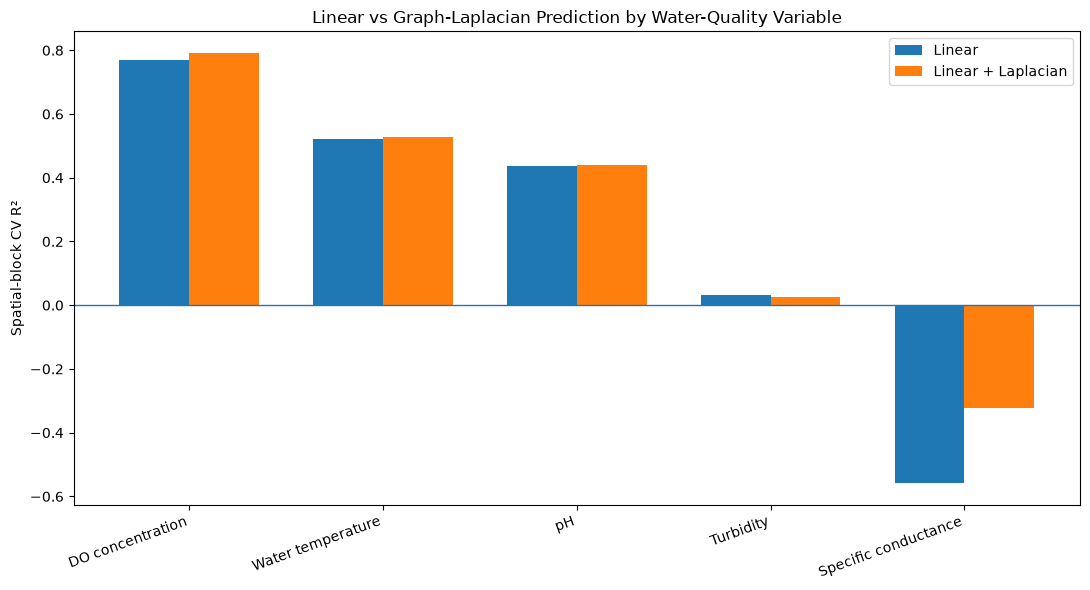

In [129]:
# ============================================================
# FIGURE 1:
# LINEAR VS GRAPH R²
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


plot_df = final_results.sort_values(
    "Graph R²",
    ascending=False
).copy()


x = np.arange(
    len(plot_df)
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(11, 6)
)


ax.bar(
    x - width / 2,
    plot_df["Linear R²"],
    width,
    label="Linear"
)

ax.bar(
    x + width / 2,
    plot_df["Graph R²"],
    width,
    label="Linear + Laplacian"
)


ax.axhline(
    0,
    linewidth=1
)


ax.set_xticks(x)

ax.set_xticklabels(
    plot_df["Target"],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Spatial-block CV R²")

ax.set_title(
    "Linear vs Graph-Laplacian Prediction by Water-Quality Variable"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "linear_vs_laplacian_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

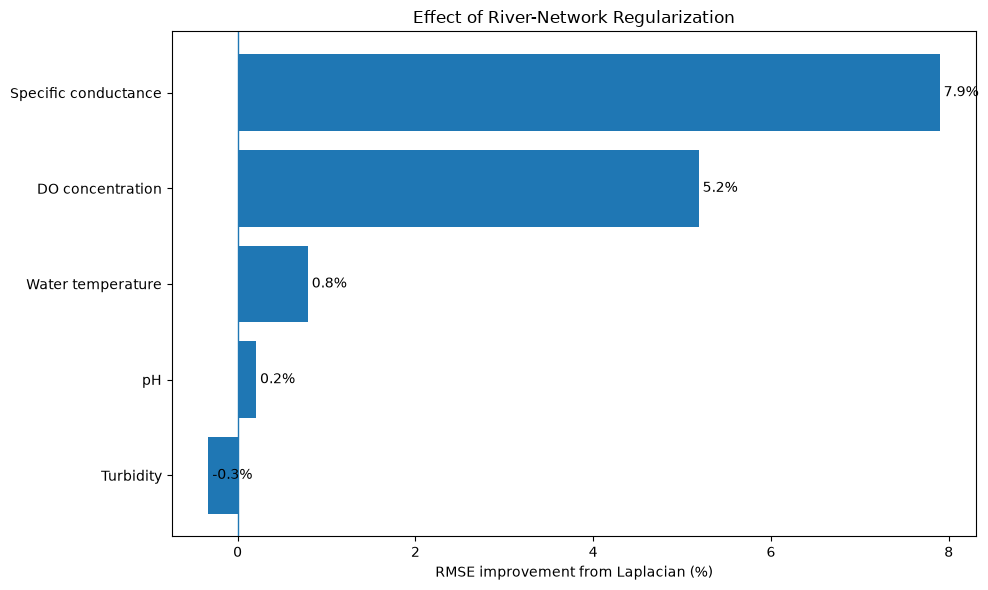

In [130]:
# ============================================================
# FIGURE 2:
# RMSE IMPROVEMENT FROM GRAPH LAPLACIAN
#
# Positive = graph helped
# Negative = graph hurt
# ============================================================

improvement_df = (
    final_results
    .sort_values(
        "Graph RMSE Improvement (%)"
    )
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


ax.barh(
    improvement_df["Target"],
    improvement_df[
        "Graph RMSE Improvement (%)"
    ]
)


ax.axvline(
    0,
    linewidth=1
)


ax.set_xlabel(
    "RMSE improvement from Laplacian (%)"
)

ax.set_title(
    "Effect of River-Network Regularization"
)


for i, value in enumerate(
    improvement_df[
        "Graph RMSE Improvement (%)"
    ]
):

    ax.text(
        value,
        i,
        f" {value:.1f}%",
        va="center"
    )


plt.tight_layout()

plt.savefig(
    "laplacian_rmse_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [131]:
# ============================================================
# DO NODE-LEVEL SUMMARY
# ============================================================

do_final = (
    do_node_comparison
    .copy()
    .sort_values(
        "graph_rmse_improvement_%",
        ascending=False
    )
)


print(
    "DO nodes improved:",
    (
        do_final[
            "graph_rmse_improvement_%"
        ] > 0
    ).sum(),
    "/",
    len(do_final)
)

print(
    "Median node-level improvement:",
    do_final[
        "graph_rmse_improvement_%"
    ].median()
)

print(
    "Mean node-level improvement:",
    do_final[
        "graph_rmse_improvement_%"
    ].mean()
)


display(do_final)


do_final.to_csv(
    "do_node_level_graph_results.csv",
    index=False
)

DO nodes improved: 7 / 10
Median node-level improvement: 6.7035139862657385
Mean node-level improvement: 4.5880037572792975


,block,node,hours,linear_rmse,graph_rmse,graph_rmse_improvement_%
0,1,67739434,7042,0.576622,0.494648,14.216209
2,2,126377584,6705,0.752598,0.652657,13.279465
5,3,88786999,5079,0.828853,0.734250,11.413721
6,3,90706215,5235,1.207012,1.070151,11.338820
8,3,96496279,7038,0.940564,0.850112,9.616775
7,3,93392084,1140,1.080907,1.039938,3.790253
1,1,93300040,6476,0.576926,0.559051,3.098235
4,3,84197086,4285,0.534339,0.548831,-2.712079
9,3,97532807,5722,0.793610,0.851625,-7.310323
3,2,131520862,4227,0.788078,0.873592,-10.851038


Using graph: manual G_plot
Nodes: 67 | Edges: 66
Nodes with coordinates: 67
Nodes with spatial-block assignments: 10

Block counts:
spatial_block
1    2
2    2
3    6
Name: count, dtype: int64

Training nodes: 15
Final test nodes: 4
Support gauge nodes: 3
Junction nodes: 18
Leaf / endpoint nodes: 20

Spatial blocks found: [1, 2, 3]


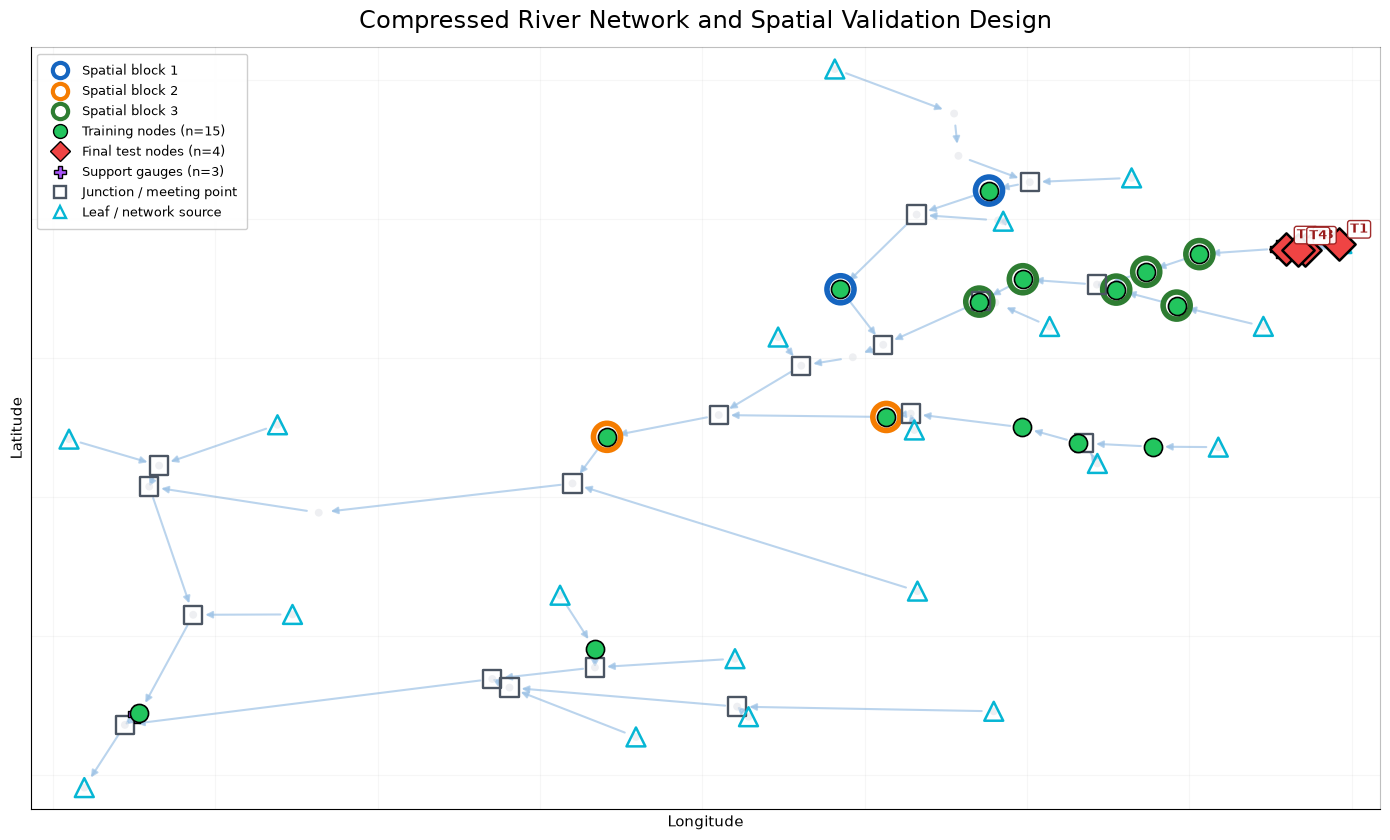


Saved figure:
/Users/andrewchincea/TDA_Lab_Practice/rivernets/making_the_graph/river_network_blocks_train_test.png

Test-node label key:
T1: 81497938
T2: 82982643
T3: 83027786
T4: 83222751


In [135]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# OPTIONAL MANUAL OVERRIDES
# ============================================================
# Uncomment these if needed:
#
# G_plot = G
# block_df = development_blocked[["node", "spatial_block"]].copy()
# train_nodes_manual = set(development["node"])
# test_nodes_manual = set(final_test["node"])
# ============================================================


# ============================================================
# 1. FIND GRAPH
# ============================================================

if "G_plot" not in globals():

    graph_candidates = [
        "G_master_compressed",
        "G_compressed_all5",
        "G_compressed",
        "G_master",
        "G_largest",
        "G"
    ]

    G_plot = None
    graph_name_used = None


    for name in graph_candidates:

        if name in globals():

            obj = globals()[name]

            if isinstance(
                obj,
                (
                    nx.Graph,
                    nx.DiGraph,
                    nx.MultiGraph,
                    nx.MultiDiGraph
                )
            ):

                G_plot = obj
                graph_name_used = name
                break


    if G_plot is None:

        raise ValueError(
            "Could not find the graph automatically.\n"
            "Set it manually, for example:\n"
            "G_plot = G"
        )

else:

    graph_name_used = "manual G_plot"


print("Using graph:", graph_name_used)

print(
    "Nodes:",
    G_plot.number_of_nodes(),
    "| Edges:",
    G_plot.number_of_edges()
)


# ============================================================
# 2. BUILD LONGITUDE / LATITUDE POSITIONS
# ============================================================

pos = {}


for node, data in G_plot.nodes(
    data=True
):

    lon = data.get(
        "longitude"
    )

    lat = data.get(
        "latitude"
    )


    if (
        lon is not None
        and
        lat is not None
    ):

        pos[node] = (
            float(lon),
            float(lat)
        )


if len(pos) == 0:

    raise ValueError(
        "No longitude/latitude coordinates found."
    )


graph_nodes = set(
    pos.keys()
)


print(
    "Nodes with coordinates:",
    len(graph_nodes)
)


# ============================================================
# 3. FIND SPATIAL BLOCK DATA
# ============================================================

if "block_df" not in globals():

    possible_block_frames = [
        "development_blocked",
        "development_blocked_flow",
        "hourly_dev",
        "node_block_hours",
        "block_assignments",
        "node_blocks",
        "do_diagnostic"
    ]

    block_df = None


    for name in possible_block_frames:

        if (
            name in globals()
            and
            isinstance(
                globals()[name],
                pd.DataFrame
            )
        ):

            candidate = (
                globals()[name]
                .copy()
            )


            if "node" not in candidate.columns:
                continue


            if "spatial_block" in candidate.columns:

                block_df = candidate[
                    [
                        "node",
                        "spatial_block"
                    ]
                ].copy()

                print(
                    "Using spatial blocks from:",
                    name
                )

                break


            elif "block" in candidate.columns:

                block_df = candidate[
                    [
                        "node",
                        "block"
                    ]
                ].copy()

                block_df = (
                    block_df.rename(
                        columns={
                            "block":
                                "spatial_block"
                        }
                    )
                )

                print(
                    "Using spatial blocks from:",
                    name
                )

                break


    if block_df is None:

        raise ValueError(
            "Could not automatically find spatial blocks.\n\n"
            "Try:\n"
            "block_df = development_blocked[['node', 'spatial_block']].copy()"
        )


# ============================================================
# 4. CLEAN BLOCK TABLE
# ============================================================

block_df = (
    block_df[
        [
            "node",
            "spatial_block"
        ]
    ]
    .dropna()
    .drop_duplicates(
        subset="node"
    )
    .copy()
)


block_df["node"] = (
    pd.to_numeric(
        block_df["node"],
        errors="coerce"
    )
)


block_df = (
    block_df.dropna(
        subset=["node"]
    )
)


block_df["node"] = (
    block_df["node"]
    .astype(int)
)


node_to_block = dict(
    zip(
        block_df["node"],
        block_df["spatial_block"]
    )
)


print(
    "Nodes with spatial-block assignments:",
    len(node_to_block)
)


print(
    "\nBlock counts:"
)

print(
    block_df[
        "spatial_block"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# 5. FIND TRAINING / TEST NODES
# ============================================================

train_nodes = set()
test_nodes = set()


# ------------------------------------------------------------
# Manual overrides
# ------------------------------------------------------------

if "train_nodes_manual" in globals():

    train_nodes = set(
        train_nodes_manual
    )


if "test_nodes_manual" in globals():

    test_nodes = set(
        test_nodes_manual
    )


# ------------------------------------------------------------
# Training nodes
# ------------------------------------------------------------

if len(train_nodes) == 0:

    if (
        "development"
        in globals()
        and
        isinstance(
            development,
            pd.DataFrame
        )
        and
        "node"
        in development.columns
    ):

        train_nodes = set(

            pd.to_numeric(
                development["node"],
                errors="coerce"
            )
            .dropna()
            .astype(int)
            .tolist()

        )


# ------------------------------------------------------------
# Final test nodes
# ------------------------------------------------------------

if len(test_nodes) == 0:

    if (
        "final_test"
        in globals()
        and
        isinstance(
            final_test,
            pd.DataFrame
        )
        and
        "node"
        in final_test.columns
    ):

        test_nodes = set(

            pd.to_numeric(
                final_test["node"],
                errors="coerce"
            )
            .dropna()
            .astype(int)
            .tolist()

        )


# Keep only nodes actually in graph

train_nodes = (
    train_nodes
    & graph_nodes
)

test_nodes = (
    test_nodes
    & graph_nodes
)


# Test takes priority if overlap exists

train_nodes = (
    train_nodes
    - test_nodes
)


print(
    "\nTraining nodes:",
    len(train_nodes)
)

print(
    "Final test nodes:",
    len(test_nodes)
)


# ============================================================
# 6. SUPPORT GAUGE NODES
# ============================================================

support_nodes = set()


for node, data in G_plot.nodes(
    data=True
):

    if node not in graph_nodes:
        continue


    count = data.get(
        "support_gauge_count",
        0
    )

    gauges = data.get(
        "support_gauges",
        []
    )


    try:

        if float(count) > 0:

            support_nodes.add(
                node
            )

            continue

    except Exception:

        pass


    if (
        isinstance(
            gauges,
            (list, tuple)
        )
        and
        len(gauges) > 0
    ):

        support_nodes.add(
            node
        )


# Don't stack them on top of train/test markers

support_nodes = (
    support_nodes
    - train_nodes
    - test_nodes
)


print(
    "Support gauge nodes:",
    len(support_nodes)
)


# ============================================================
# 7. JUNCTION AND LEAF NODES
# ============================================================

G_und = G_plot.to_undirected(
    as_view=True
)


junction_nodes = {

    node

    for node in graph_nodes

    if G_und.degree(node) >= 3
}


leaf_nodes = {

    node

    for node in graph_nodes

    if G_und.degree(node) == 1
}


junction_only = (
    junction_nodes
    - train_nodes
    - test_nodes
    - support_nodes
)


leaf_only = (
    leaf_nodes
    - train_nodes
    - test_nodes
    - support_nodes
    - junction_nodes
)


print(
    "Junction nodes:",
    len(junction_nodes)
)

print(
    "Leaf / endpoint nodes:",
    len(leaf_nodes)
)


# ============================================================
# 8. SPATIAL-BLOCK COLORS
# ============================================================

block_palette = {

    1:
        "#1565C0",   # BLUE

    2:
        "#F57C00",   # ORANGE

    3:
        "#2E7D32",   # GREEN

    4:
        "#8E24AA",   # PURPLE

    5:
        "#00838F"    # TEAL
}


assigned_block_nodes = {

    node:
        block

    for node, block
    in node_to_block.items()

    if node in graph_nodes
}


unique_blocks = sorted(

    pd.Series(
        list(
            assigned_block_nodes.values()
        )
    )
    .dropna()
    .unique()
    .tolist()

)


print(
    "\nSpatial blocks found:",
    unique_blocks
)


# ============================================================
# 9. HELPER FUNCTION
# ============================================================

def node_xy(
    nodes
):

    xs = [

        pos[node][0]

        for node in nodes

        if node in pos

    ]


    ys = [

        pos[node][1]

        for node in nodes

        if node in pos

    ]


    return (
        xs,
        ys
    )


# ============================================================
# 10. CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        14,
        8.5
    )
)


# ============================================================
# 11. DRAW RIVER EDGES
# ============================================================

nx.draw_networkx_edges(

    G_plot,

    pos,

    ax=ax,

    edge_color=
        "#9EC3E6",

    width=
        1.5,

    alpha=
        0.70,

    arrows=
        True,

    arrowsize=
        10,

    arrowstyle=
        "-|>"
)


# ============================================================
# 12. SMALL STRUCTURAL BACKGROUND NODES
# ============================================================

nx.draw_networkx_nodes(

    G_plot,

    pos,

    nodelist=
        list(
            graph_nodes
        ),

    node_color=
        "#E5E7EB",

    node_size=
        32,

    edgecolors=
        "none",

    alpha=
        0.65,

    ax=ax
)


# ============================================================
# 13. SPATIAL-BLOCK RINGS
#
# THIS IS THE IMPORTANT PART.
#
# Every node belonging to a spatial validation block
# receives a large outer colored ring.
# ============================================================

for block in unique_blocks:

    block_nodes = [

        node

        for node, assigned_block
        in assigned_block_nodes.items()

        if (
            assigned_block == block
            and
            node in pos
        )
    ]


    if len(
        block_nodes
    ) == 0:

        continue


    x_block, y_block = (
        node_xy(
            block_nodes
        )
    )


    ax.scatter(

        x_block,

        y_block,

        s=
            380,

        facecolors=
            "none",

        edgecolors=
            block_palette.get(
                block,
                "#555555"
            ),

        linewidths=
            4.0,

        marker=
            "o",

        alpha=
            1.0,

        zorder=
            7
    )


# ============================================================
# 14. JUNCTION / MEETING POINTS
#
# DARK GRAY instead of orange so Block 2 is not confusing.
# ============================================================

if len(
    junction_only
) > 0:

    x_junction, y_junction = (
        node_xy(
            junction_only
        )
    )


    ax.scatter(

        x_junction,

        y_junction,

        s=
            175,

        facecolors=
            "none",

        edgecolors=
            "#4B5563",

        linewidths=
            1.7,

        marker=
            "s",

        zorder=
            9
    )


# ============================================================
# 15. LEAF / HEADWATER ENDPOINTS
# ============================================================

if len(
    leaf_only
) > 0:

    x_leaf, y_leaf = (
        node_xy(
            leaf_only
        )
    )


    ax.scatter(

        x_leaf,

        y_leaf,

        s=
            185,

        facecolors=
            "none",

        edgecolors=
            "#06B6D4",

        linewidths=
            1.8,

        marker=
            "^",

        zorder=
            9
    )


# ============================================================
# 16. SUPPORT GAUGES
# ============================================================

if len(
    support_nodes
) > 0:

    x_support, y_support = (
        node_xy(
            support_nodes
        )
    )


    ax.scatter(

        x_support,

        y_support,

        s=
            155,

        c=
            "#A855F7",

        edgecolors=
            "black",

        linewidths=
            1.0,

        marker=
            "P",

        zorder=
            11
    )


# ============================================================
# 17. TRAINING NODES
# ============================================================

if len(
    train_nodes
) > 0:

    x_train, y_train = (
        node_xy(
            train_nodes
        )
    )


    ax.scatter(

        x_train,

        y_train,

        s=
            170,

        c=
            "#22C55E",

        edgecolors=
            "black",

        linewidths=
            1.2,

        marker=
            "o",

        alpha=
            1.0,

        zorder=
            15
    )


# ============================================================
# 18. FINAL TEST NODES
#
# Draw LAST so they are extremely obvious.
# ============================================================

if len(
    test_nodes
) > 0:

    x_test, y_test = (
        node_xy(
            test_nodes
        )
    )


    ax.scatter(

        x_test,

        y_test,

        s=
            270,

        c=
            "#EF4444",

        edgecolors=
            "black",

        linewidths=
            1.8,

        marker=
            "D",

        alpha=
            1.0,

        zorder=
            20
    )


# ============================================================
# 19. LABEL FINAL TEST NODES
#
# Short labels avoid the giant overlapping node IDs.
# ============================================================

test_node_key = {}


for i, node in enumerate(
    sorted(test_nodes),
    start=1
):

    test_node_key[
        f"T{i}"
    ] = node


    if node not in pos:
        continue


    x, y = pos[
        node
    ]


    ax.annotate(

        f"T{i}",

        xy=(
            x,
            y
        ),

        xytext=(
            8,
            8
        ),

        textcoords=
            "offset points",

        fontsize=
            9,

        fontweight=
            "bold",

        color=
            "#991B1B",

        bbox=dict(

            boxstyle=
                "round,pad=0.20",

            facecolor=
                "white",

            edgecolor=
                "#991B1B",

            alpha=
                0.92
        ),

        zorder=
            25
    )


# ============================================================
# 20. TITLE AND AXES
# ============================================================

ax.set_title(

    "Compressed River Network and Spatial Validation Design",

    fontsize=
        17,

    pad=
        14
)


ax.set_xlabel(
    "Longitude",
    fontsize=11
)


ax.set_ylabel(
    "Latitude",
    fontsize=11
)


ax.grid(
    True,
    alpha=
        0.10
)


# ============================================================
# 21. MAP LIMITS
# ============================================================

xs = [

    xy[0]

    for xy
    in pos.values()

]


ys = [

    xy[1]

    for xy
    in pos.values()

]


x_range = (
    max(xs)
    -
    min(xs)
)


y_range = (
    max(ys)
    -
    min(ys)
)


pad_x = (
    0.03
    *
    x_range
)


pad_y = (
    0.03
    *
    y_range
)


ax.set_xlim(

    min(xs)
    -
    pad_x,

    max(xs)
    +
    pad_x
)


ax.set_ylim(

    min(ys)
    -
    pad_y,

    max(ys)
    +
    pad_y
)


# ============================================================
# 22. LEGEND
# ============================================================

legend_items = []


# ------------------------------------------------------------
# Spatial blocks
# ------------------------------------------------------------

for block in unique_blocks:

    legend_items.append(

        Line2D(

            [0],
            [0],

            marker=
                "o",

            color=
                "w",

            markerfacecolor=
                "none",

            markeredgecolor=
                block_palette.get(
                    block,
                    "#555555"
                ),

            markeredgewidth=
                3,

            markersize=
                11,

            label=
                f"Spatial block {int(block)}"
        )
    )


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

legend_items.append(

    Line2D(

        [0],
        [0],

        marker=
            "o",

        color=
            "w",

        markerfacecolor=
            "#22C55E",

        markeredgecolor=
            "black",

        markersize=
            10,

        label=
            f"Training nodes (n={len(train_nodes)})"
    )
)


# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

legend_items.append(

    Line2D(

        [0],
        [0],

        marker=
            "D",

        color=
            "w",

        markerfacecolor=
            "#EF4444",

        markeredgecolor=
            "black",

        markersize=
            10,

        label=
            f"Final test nodes (n={len(test_nodes)})"
    )
)


# ------------------------------------------------------------
# Support gauges
# ------------------------------------------------------------

if len(
    support_nodes
) > 0:

    legend_items.append(

        Line2D(

            [0],
            [0],

            marker=
                "P",

            color=
                "w",

            markerfacecolor=
                "#A855F7",

            markeredgecolor=
                "black",

            markersize=
                9,

            label=
                f"Support gauges (n={len(support_nodes)})"
        )
    )


# ------------------------------------------------------------
# Junctions
# ------------------------------------------------------------

legend_items.append(

    Line2D(

        [0],
        [0],

        marker=
            "s",

        color=
            "w",

        markerfacecolor=
            "none",

        markeredgecolor=
            "#4B5563",

        markeredgewidth=
            1.7,

        markersize=
            9,

        label=
            "Junction / meeting point"
    )
)


# ------------------------------------------------------------
# Leaves
# ------------------------------------------------------------

legend_items.append(

    Line2D(

        [0],
        [0],

        marker=
            "^",

        color=
            "w",

        markerfacecolor=
            "none",

        markeredgecolor=
            "#06B6D4",

        markeredgewidth=
            1.7,

        markersize=
            9,

        label=
            "Leaf / network source"
    )
)


ax.legend(

    handles=
        legend_items,

    loc=
        "upper left",

    fontsize=
        9,

    frameon=
        True,

    framealpha=
        0.96,

    borderpad=
        0.8
)


# ============================================================
# 23. CLEAN APPEARANCE
# ============================================================

ax.spines[
    "top"
].set_alpha(
    0.25
)


ax.spines[
    "right"
].set_alpha(
    0.25
)


plt.tight_layout()


# ============================================================
# 24. SAVE PNG
# ============================================================

output_file = (
    "river_network_blocks_train_test.png"
)


plt.savefig(

    output_file,

    dpi=
        300,

    bbox_inches=
        "tight",

    facecolor=
        "white"
)


plt.show()


# ============================================================
# 25. PRINT TEST NODE KEY
# ============================================================

print(
    "\nSaved figure:"
)

print(
    os.path.abspath(
        output_file
    )
)


print(
    "\nTest-node label key:"
)

for label, node in test_node_key.items():

    print(
        f"{label}: {node}"
    )